In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/GINECOLOGÍA.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 10 questions
Page 1, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=148.2, y1=109.2
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 333
Page 1, Q1, A: Yellow percentage: 0.0%


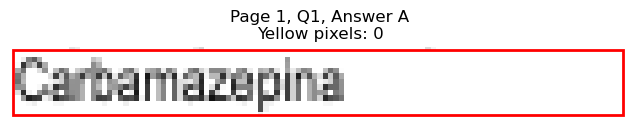

Page 1, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=135.3, y1=121.3
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 279
Page 1, Q1, B: Yellow percentage: 0.0%


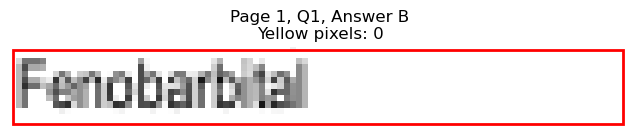

Page 1, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=132.4, y1=133.3
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 228
Page 1, Q1, C: Yellow percentage: 0.0%


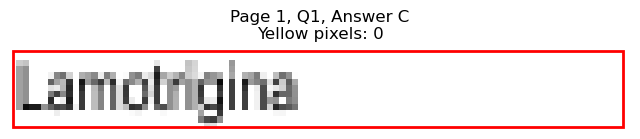

Page 1, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=382.6, y1=109.2
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 218
Page 1, Q1, D: Yellow percentage: 0.0%


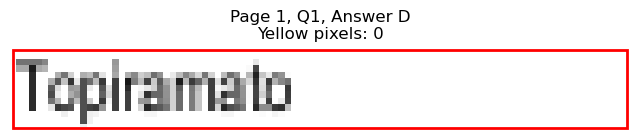

Page 1, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=375.9, y1=121.3
Page 1, Q1, E: Yellow pixels: 922
Page 1, Q1, E: Total non-white pixels: 1170
Page 1, Q1, E: Yellow percentage: 78.8%


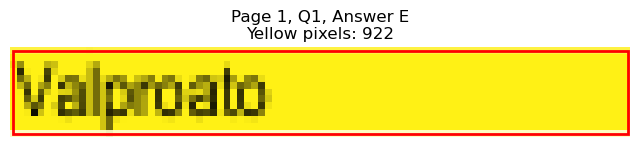


Page 1, Q1 - Selected Answer: E (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=94.6, y1=205.5
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 50
Page 1, Q2, A: Yellow percentage: 0.0%


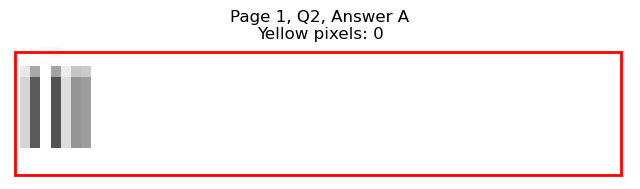

Page 1, Q2 - B: Detected box: x0=70.8, y0=205.5, x1=79.0, y1=217.7
Page 1, Q2, B: Yellow pixels: 59
Page 1, Q2, B: Total non-white pixels: 114
Page 1, Q2, B: Yellow percentage: 51.8%


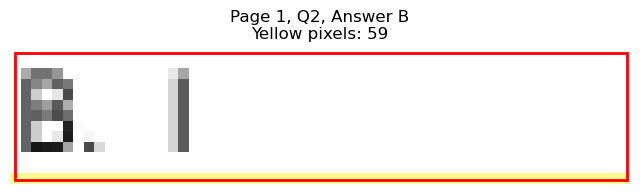

Page 1, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=95.6, y1=229.7
Page 1, Q2, C: Yellow pixels: 768
Page 1, Q2, C: Total non-white pixels: 806
Page 1, Q2, C: Yellow percentage: 95.3%


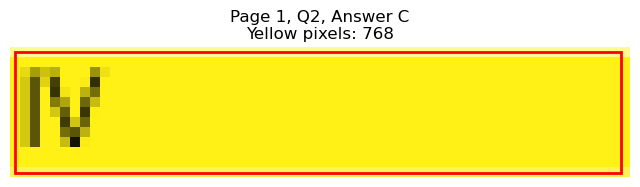

Page 1, Q2 - D: Detected box: x0=322.5, y0=193.4, x1=331.2, y1=205.5
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 65
Page 1, Q2, D: Yellow percentage: 0.0%


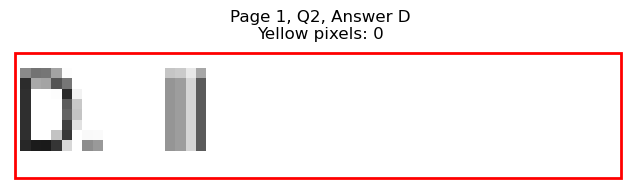

Page 1, Q2 - E: Detected box: x0=322.5, y0=205.5, x1=330.7, y1=217.7
Page 1, Q2, E: Yellow pixels: 0
Page 1, Q2, E: Total non-white pixels: 58
Page 1, Q2, E: Yellow percentage: 0.0%


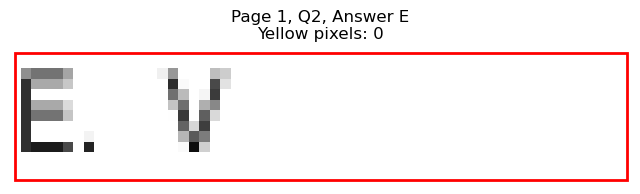


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=194.2, y1=265.8
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 584
Page 1, Q3, A: Yellow percentage: 0.0%


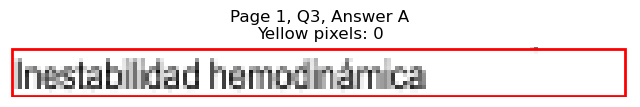

Page 1, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=219.5, y1=277.9
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 685
Page 1, Q3, B: Yellow percentage: 0.0%


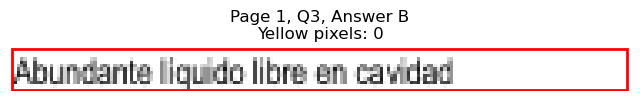

Page 1, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=178.3, y1=289.9
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 471
Page 1, Q3, C: Yellow percentage: 0.0%


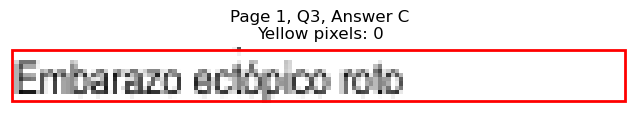

Page 1, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=466.4, y1=265.8
Page 1, Q3, D: Yellow pixels: 1685
Page 1, Q3, D: Total non-white pixels: 2353
Page 1, Q3, D: Yellow percentage: 71.6%


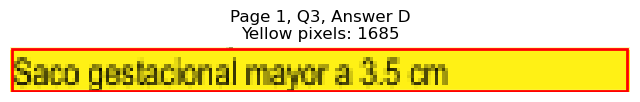

Page 1, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=449.1, y1=277.9
Page 1, Q3, E: Yellow pixels: 158
Page 1, Q3, E: Total non-white pixels: 734
Page 1, Q3, E: Yellow percentage: 21.5%


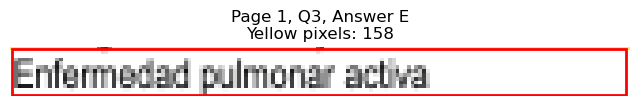


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=85.0, y0=326.1, x1=126.6, y1=338.2
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 203
Page 1, Q4, A: Yellow percentage: 0.0%


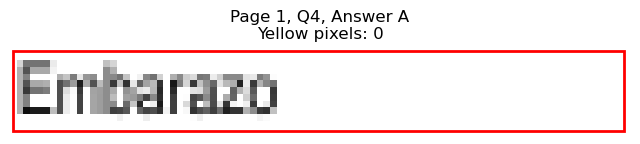

Page 1, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=129.0, y1=350.2
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 230
Page 1, Q4, B: Yellow percentage: 0.0%


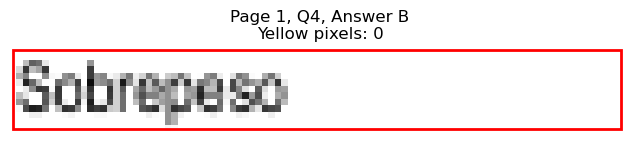

Page 1, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=146.7, y1=362.3
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 328
Page 1, Q4, C: Yellow percentage: 0.0%


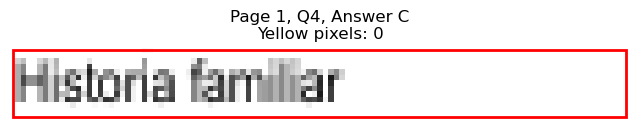

Page 1, Q4 - D: Detected box: x0=336.7, y0=326.1, x1=377.8, y1=338.2
Page 1, Q4, D: Yellow pixels: 92
Page 1, Q4, D: Total non-white pixels: 307
Page 1, Q4, D: Yellow percentage: 30.0%


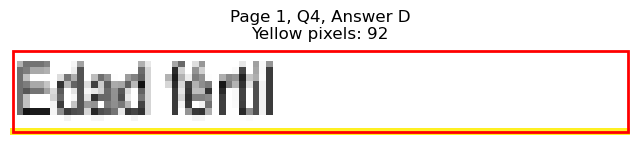

Page 1, Q4 - E: Detected box: x0=336.7, y0=338.1, x1=386.5, y1=350.2
Page 1, Q4, E: Yellow pixels: 1002
Page 1, Q4, E: Total non-white pixels: 1313
Page 1, Q4, E: Yellow percentage: 76.3%


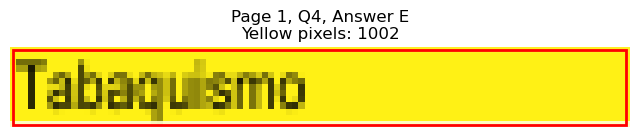


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=123.7, y1=398.4
Page 1, Q5, A: Yellow pixels: 90
Page 1, Q5, A: Total non-white pixels: 289
Page 1, Q5, A: Yellow percentage: 31.1%


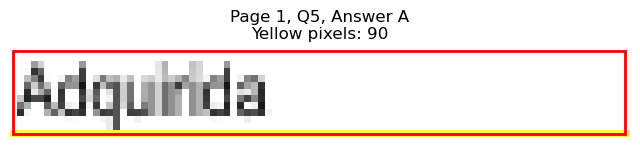

Page 1, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=220.5, y1=410.4
Page 1, Q5, B: Yellow pixels: 1820
Page 1, Q5, B: Total non-white pixels: 2431
Page 1, Q5, B: Yellow percentage: 74.9%


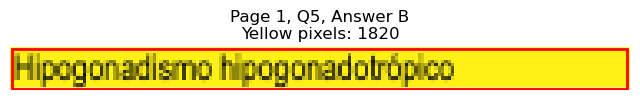

Page 1, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=223.4, y1=422.5
Page 1, Q5, C: Yellow pixels: 190
Page 1, Q5, C: Total non-white pixels: 944
Page 1, Q5, C: Yellow percentage: 20.1%


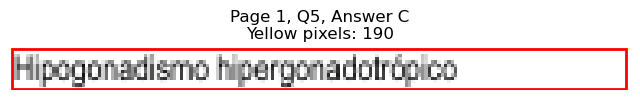

Page 1, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=404.2, y1=398.4
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 365
Page 1, Q5, D: Yellow percentage: 0.0%


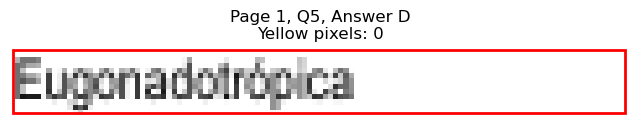

Page 1, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=381.2, y1=410.4
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 257
Page 1, Q5, E: Yellow percentage: 0.0%


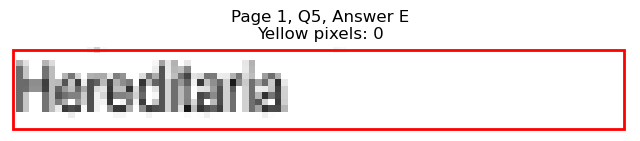


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=85.0, y0=458.6, x1=158.7, y1=470.7
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 364
Page 1, Q6, A: Yellow percentage: 0.0%


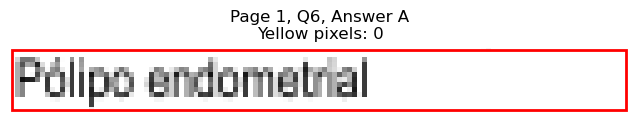

Page 1, Q6 - B: Detected box: x0=85.0, y0=470.7, x1=165.4, y1=482.8
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 412
Page 1, Q6, B: Yellow percentage: 0.0%


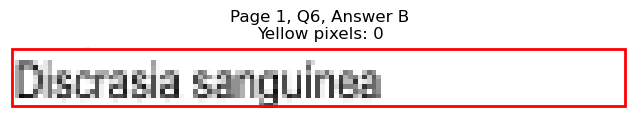

Page 1, Q6 - C: Detected box: x0=85.0, y0=482.7, x1=219.5, y1=494.8
Page 1, Q6, C: Yellow pixels: 0
Page 1, Q6, C: Total non-white pixels: 659
Page 1, Q6, C: Yellow percentage: 0.0%


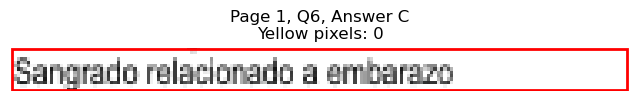

Page 1, Q6 - D: Detected box: x0=336.7, y0=458.6, x1=494.6, y1=470.7
Page 1, Q6, D: Yellow pixels: 1793
Page 1, Q6, D: Total non-white pixels: 2470
Page 1, Q6, D: Yellow percentage: 72.6%


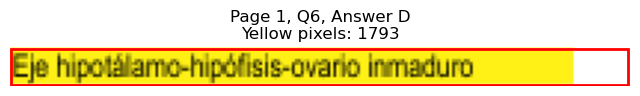

Page 1, Q6 - E: Detected box: x0=336.7, y0=470.7, x1=390.8, y1=482.8
Page 1, Q6, E: Yellow pixels: 105
Page 1, Q6, E: Total non-white pixels: 363
Page 1, Q6, E: Yellow percentage: 28.9%


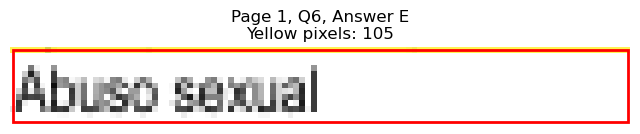


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=466.5, y1=530.9
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 1820
Page 1, Q7, A: Yellow percentage: 0.0%


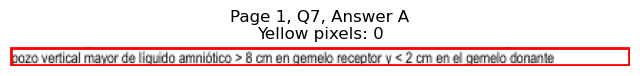

Page 1, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=382.8, y1=543.0
Page 1, Q7, B: Yellow pixels: 349
Page 1, Q7, B: Total non-white pixels: 2165
Page 1, Q7, B: Yellow percentage: 16.1%


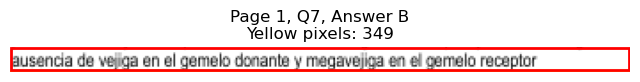

Page 1, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=497.1, y1=555.0
Page 1, Q7, C: Yellow pixels: 3632
Page 1, Q7, C: Total non-white pixels: 5752
Page 1, Q7, C: Yellow percentage: 63.1%


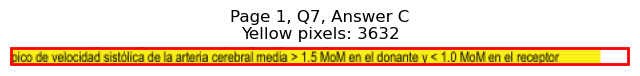

Page 1, Q7 - D: Detected box: x0=85.0, y0=554.9, x1=385.6, y1=567.0
Page 1, Q7, D: Yellow pixels: 347
Page 1, Q7, D: Total non-white pixels: 1872
Page 1, Q7, D: Yellow percentage: 18.5%


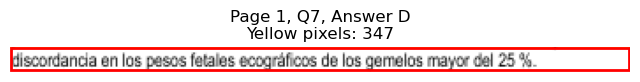

Page 1, Q7 - E: Detected box: x0=85.0, y0=567.1, x1=498.1, y1=579.2
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 2048
Page 1, Q7, E: Yellow percentage: 0.0%


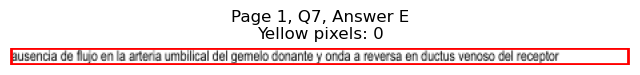


Page 1, Q7 - Selected Answer: C (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=70.8, y0=615.2, x1=79.0, y1=627.3
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 53
Page 1, Q8, A: Yellow percentage: 0.0%


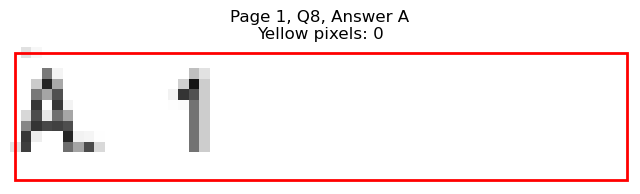

Page 1, Q8 - B: Detected box: x0=70.8, y0=627.3, x1=79.0, y1=639.4
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 65
Page 1, Q8, B: Yellow percentage: 0.0%


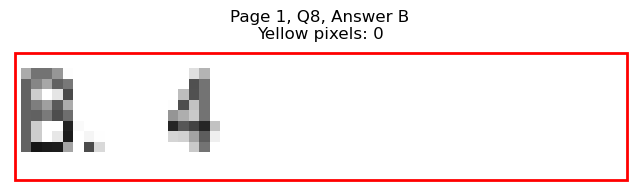

Page 1, Q8 - C: Detected box: x0=70.8, y0=639.3, x1=79.5, y1=651.4
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 60
Page 1, Q8, C: Yellow percentage: 0.0%


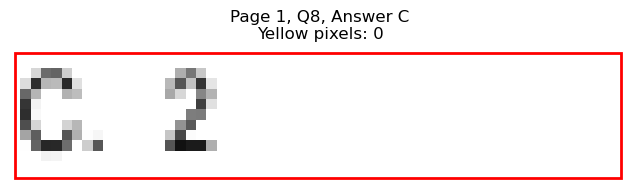

Page 1, Q8 - D: Detected box: x0=322.5, y0=615.2, x1=331.2, y1=627.3
Page 1, Q8, D: Yellow pixels: 673
Page 1, Q8, D: Total non-white pixels: 780
Page 1, Q8, D: Yellow percentage: 86.3%


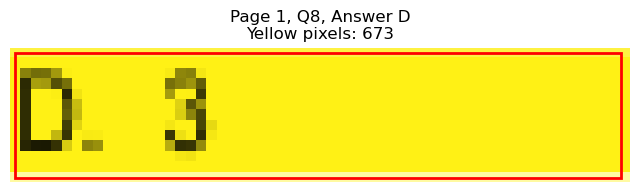

Page 1, Q8 - E: Detected box: x0=322.5, y0=627.3, x1=330.7, y1=639.4
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 117
Page 1, Q8, E: Yellow percentage: 0.0%


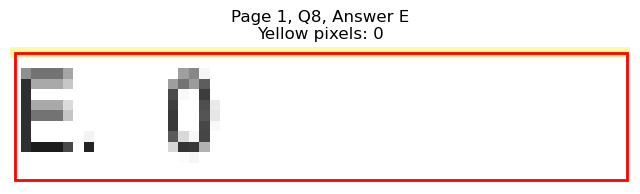


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=85.0, y0=687.5, x1=182.2, y1=699.7
Page 1, Q9, A: Yellow pixels: 149
Page 1, Q9, A: Total non-white pixels: 614
Page 1, Q9, A: Yellow percentage: 24.3%


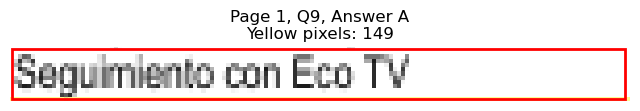

Page 1, Q9 - B: Detected box: x0=85.0, y0=699.5, x1=170.2, y1=711.7
Page 1, Q9, B: Yellow pixels: 1434
Page 1, Q9, B: Total non-white pixels: 1781
Page 1, Q9, B: Yellow percentage: 80.5%


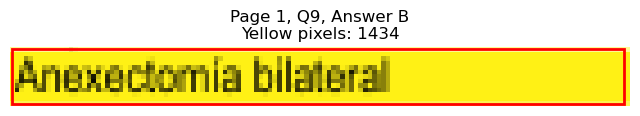

Page 1, Q9 - C: Detected box: x0=85.0, y0=711.7, x1=175.0, y1=723.8
Page 1, Q9, C: Yellow pixels: 141
Page 1, Q9, C: Total non-white pixels: 592
Page 1, Q9, C: Yellow percentage: 23.8%


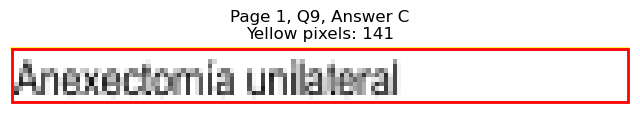

Page 1, Q9 - D: Detected box: x0=336.7, y0=687.5, x1=471.7, y1=699.7
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 689
Page 1, Q9, D: Yellow percentage: 0.0%


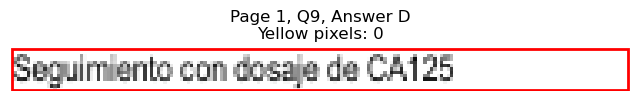

Page 1, Q9 - E: Detected box: x0=336.7, y0=699.5, x1=435.8, y1=711.7
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 549
Page 1, Q9, E: Yellow percentage: 0.0%


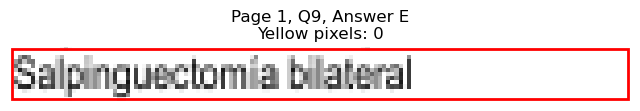


Page 1, Q9 - Selected Answer: B (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=85.0, y0=747.8, x1=241.0, y1=759.9
Page 1, Q10, A: Yellow pixels: 0
Page 1, Q10, A: Total non-white pixels: 815
Page 1, Q10, A: Yellow percentage: 0.0%


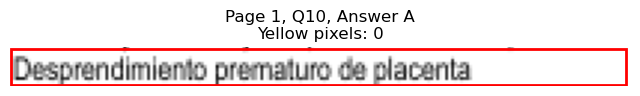

Page 1, Q10 - B: Detected box: x0=85.0, y0=759.8, x1=146.8, y1=771.9
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 336
Page 1, Q10, B: Yellow percentage: 0.0%


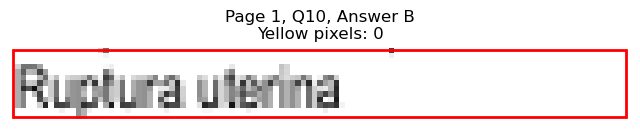

Page 1, Q10 - C: Detected box: x0=85.0, y0=771.9, x1=141.0, y1=784.0
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 299
Page 1, Q10, C: Yellow percentage: 0.0%


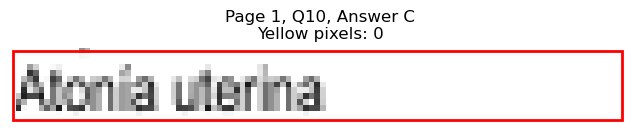

Page 1, Q10 - D: Detected box: x0=336.7, y0=747.8, x1=413.7, y1=759.9
Page 1, Q10, D: Yellow pixels: 1219
Page 1, Q10, D: Total non-white pixels: 1664
Page 1, Q10, D: Yellow percentage: 73.3%


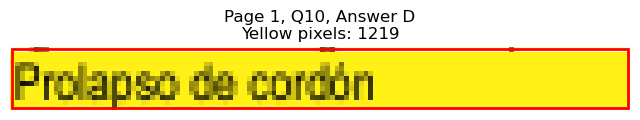

Page 1, Q10 - E: Detected box: x0=336.7, y0=759.8, x1=403.8, y1=771.9
Page 1, Q10, E: Yellow pixels: 117
Page 1, Q10, E: Total non-white pixels: 472
Page 1, Q10, E: Yellow percentage: 24.8%


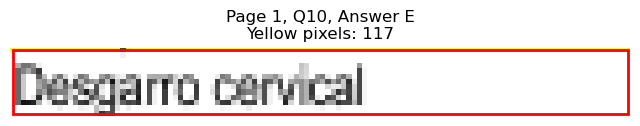


Page 1, Q10 - Selected Answer: D (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=85.0, y0=121.2, x1=93.6, y1=133.3
Page 2, Q1, A: Yellow pixels: 695
Page 2, Q1, A: Total non-white pixels: 780
Page 2, Q1, A: Yellow percentage: 89.1%


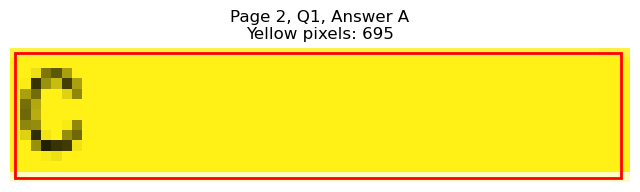

Page 2, Q1 - B: Detected box: x0=70.8, y0=133.2, x1=79.0, y1=145.3
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 135
Page 2, Q1, B: Yellow percentage: 0.0%


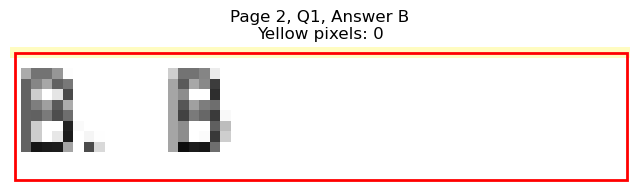

Page 2, Q1 - C: Detected box: x0=70.8, y0=145.3, x1=79.5, y1=157.4
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 63
Page 2, Q1, C: Yellow percentage: 0.0%


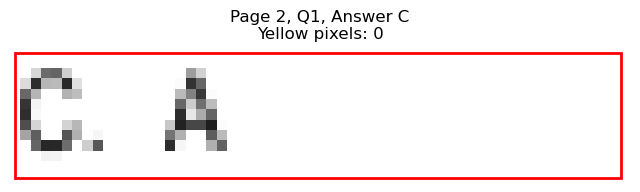

Page 2, Q1 - D: Detected box: x0=322.5, y0=121.2, x1=331.2, y1=133.3
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 69
Page 2, Q1, D: Yellow percentage: 0.0%


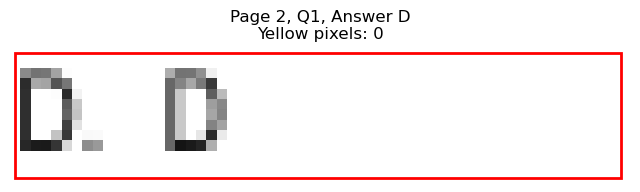

Page 2, Q1 - E: Detected box: x0=322.5, y0=133.2, x1=330.7, y1=145.3
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 61
Page 2, Q1, E: Yellow percentage: 0.0%


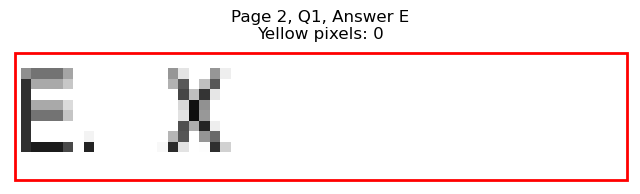


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=227.7, y1=205.5
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 662
Page 2, Q2, A: Yellow percentage: 0.0%


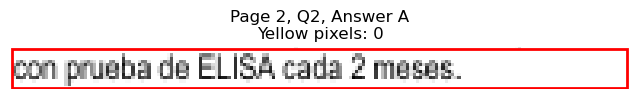

Page 2, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=185.5, y1=217.7
Page 2, Q2, B: Yellow pixels: 152
Page 2, Q2, B: Total non-white pixels: 630
Page 2, Q2, B: Yellow percentage: 24.1%


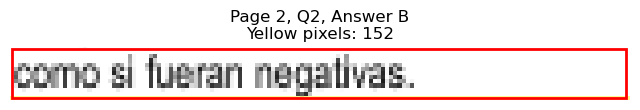

Page 2, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=286.5, y1=229.7
Page 2, Q2, C: Yellow pixels: 2518
Page 2, Q2, C: Total non-white pixels: 3289
Page 2, Q2, C: Yellow percentage: 76.6%


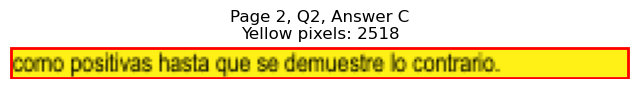

Page 2, Q2 - D: Detected box: x0=85.0, y0=229.7, x1=227.7, y1=241.8
Page 2, Q2, D: Yellow pixels: 194
Page 2, Q2, D: Total non-white pixels: 856
Page 2, Q2, D: Yellow percentage: 22.7%


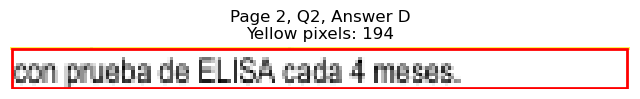

Page 2, Q2 - E: Detected box: x0=85.0, y0=241.7, x1=209.0, y1=253.8
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 606
Page 2, Q2, E: Yellow percentage: 0.0%


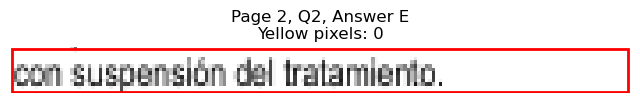


Page 2, Q2 - Selected Answer: C (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=125.2, y1=289.9
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 244
Page 2, Q3, A: Yellow percentage: 0.0%


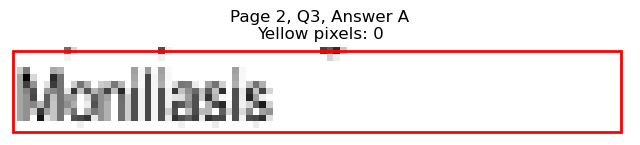

Page 2, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=167.3, y1=302.0
Page 2, Q3, B: Yellow pixels: 1263
Page 2, Q3, B: Total non-white pixels: 1744
Page 2, Q3, B: Yellow percentage: 72.4%


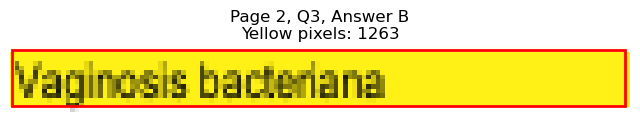

Page 2, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=145.3, y1=314.0
Page 2, Q3, C: Yellow pixels: 108
Page 2, Q3, C: Total non-white pixels: 432
Page 2, Q3, C: Yellow percentage: 25.0%


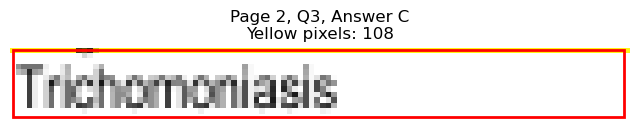

Page 2, Q3 - D: Detected box: x0=336.7, y0=277.8, x1=394.6, y1=289.9
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 305
Page 2, Q3, D: Yellow percentage: 0.0%


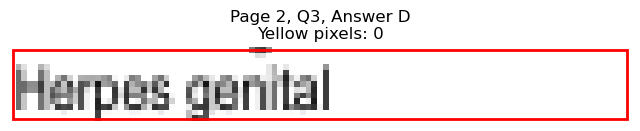

Page 2, Q3 - E: Detected box: x0=336.7, y0=289.9, x1=439.6, y1=302.0
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 562
Page 2, Q3, E: Yellow percentage: 0.0%


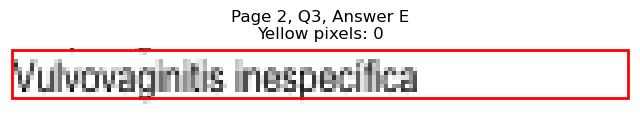


Page 2, Q3 - Selected Answer: B (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=85.0, y0=350.2, x1=147.7, y1=362.3
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 317
Page 2, Q4, A: Yellow percentage: 0.0%


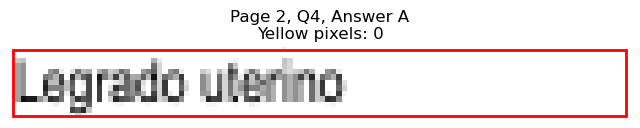

Page 2, Q4 - B: Detected box: x0=85.0, y0=362.2, x1=112.2, y1=374.3
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 147
Page 2, Q4, B: Yellow percentage: 0.0%


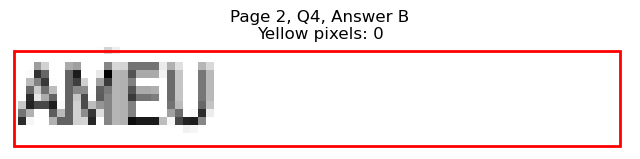

Page 2, Q4 - C: Detected box: x0=85.0, y0=374.2, x1=140.5, y1=386.3
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 299
Page 2, Q4, C: Yellow percentage: 0.0%


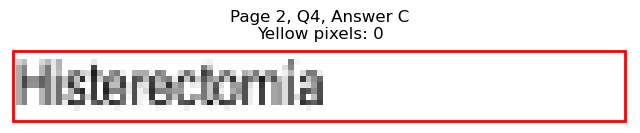

Page 2, Q4 - D: Detected box: x0=336.7, y0=350.2, x1=391.9, y1=362.3
Page 2, Q4, D: Yellow pixels: 106
Page 2, Q4, D: Total non-white pixels: 394
Page 2, Q4, D: Yellow percentage: 26.9%


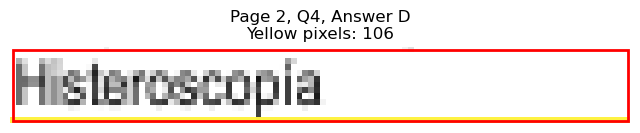

Page 2, Q4 - E: Detected box: x0=336.7, y0=362.2, x1=414.2, y1=374.3
Page 2, Q4, E: Yellow pixels: 1230
Page 2, Q4, E: Total non-white pixels: 1677
Page 2, Q4, E: Yellow percentage: 73.3%


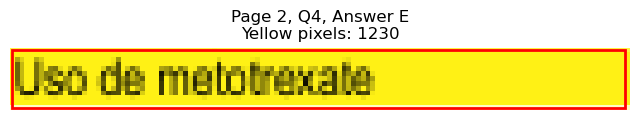


Page 2, Q4 - Selected Answer: E (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=85.0, y0=422.4, x1=199.4, y1=434.5
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 595
Page 2, Q5, A: Yellow percentage: 0.0%


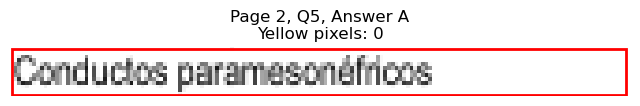

Page 2, Q5 - B: Detected box: x0=85.0, y0=434.4, x1=153.5, y1=446.5
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 352
Page 2, Q5, B: Yellow percentage: 0.0%


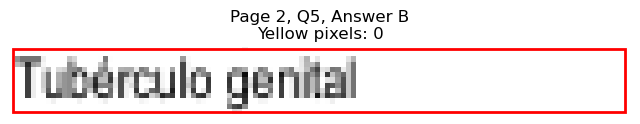

Page 2, Q5 - C: Detected box: x0=85.0, y0=446.6, x1=143.9, y1=458.7
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 295
Page 2, Q5, C: Yellow percentage: 0.0%


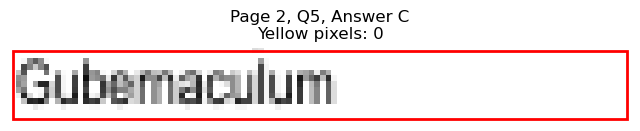

Page 2, Q5 - D: Detected box: x0=336.7, y0=422.4, x1=433.9, y1=434.5
Page 2, Q5, D: Yellow pixels: 1520
Page 2, Q5, D: Total non-white pixels: 1924
Page 2, Q5, D: Yellow percentage: 79.0%


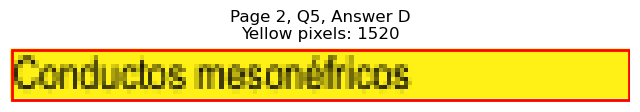

Page 2, Q5 - E: Detected box: x0=336.7, y0=434.4, x1=421.4, y1=446.5
Page 2, Q5, E: Yellow pixels: 136
Page 2, Q5, E: Total non-white pixels: 602
Page 2, Q5, E: Yellow percentage: 22.6%


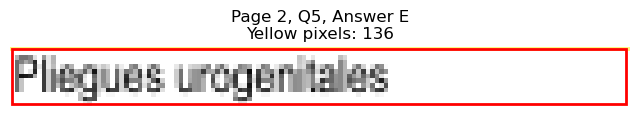


Page 2, Q5 - Selected Answer: D (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=70.8, y0=494.7, x1=79.0, y1=506.8
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 48
Page 2, Q6, A: Yellow percentage: 0.0%


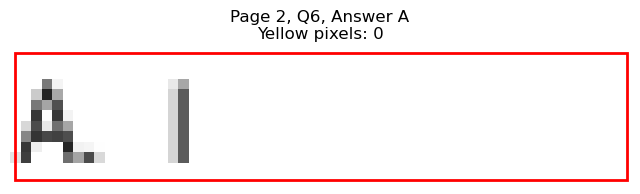

Page 2, Q6 - B: Detected box: x0=85.0, y0=506.8, x1=94.6, y1=518.9
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 109
Page 2, Q6, B: Yellow percentage: 0.0%


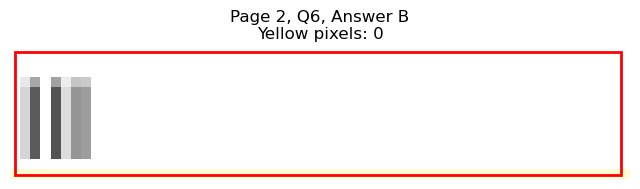

Page 2, Q6 - C: Detected box: x0=70.8, y0=518.8, x1=79.5, y1=530.9
Page 2, Q6, C: Yellow pixels: 670
Page 2, Q6, C: Total non-white pixels: 780
Page 2, Q6, C: Yellow percentage: 85.9%


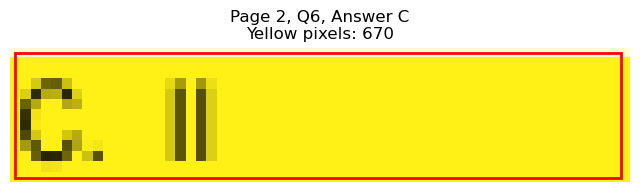

Page 2, Q6 - D: Detected box: x0=322.5, y0=494.7, x1=331.2, y1=506.8
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 72
Page 2, Q6, D: Yellow percentage: 0.0%


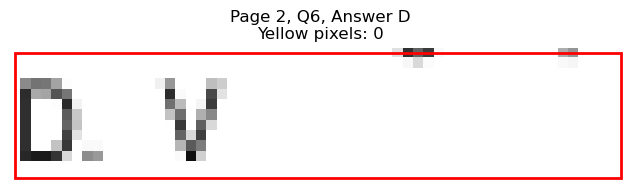

Page 2, Q6 - E: Detected box: x0=336.7, y0=506.8, x1=347.2, y1=518.9
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 44
Page 2, Q6, E: Yellow percentage: 0.0%


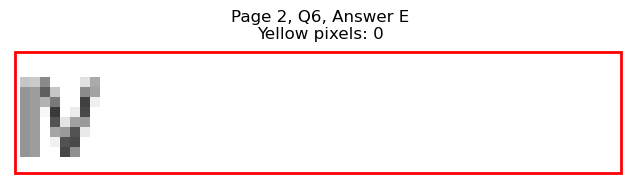


Page 2, Q6 - Selected Answer: C (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=85.0, y0=554.9, x1=269.8, y1=567.0
Page 2, Q7, A: Yellow pixels: 2060
Page 2, Q7, A: Total non-white pixels: 3304
Page 2, Q7, A: Yellow percentage: 62.3%


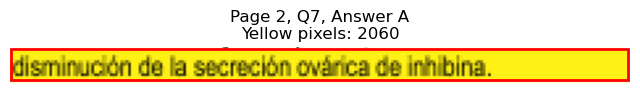

Page 2, Q7 - B: Detected box: x0=85.0, y0=567.1, x1=257.8, y1=579.2
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 1057
Page 2, Q7, B: Yellow percentage: 0.0%


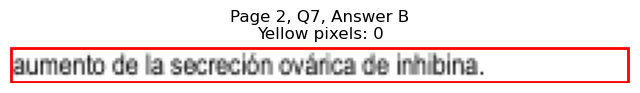

Page 2, Q7 - C: Detected box: x0=85.0, y0=579.1, x1=232.9, y1=591.2
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 732
Page 2, Q7, C: Yellow percentage: 0.0%


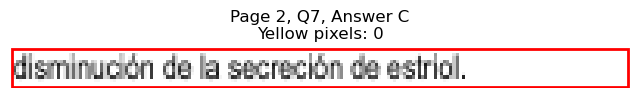

Page 2, Q7 - D: Detected box: x0=85.0, y0=591.2, x1=248.7, y1=603.3
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 804
Page 2, Q7, D: Yellow percentage: 0.0%


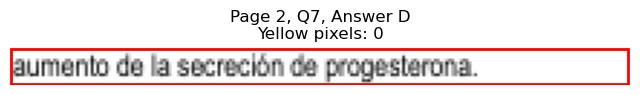

Page 2, Q7 - E: Detected box: x0=85.0, y0=603.2, x1=287.9, y1=615.3
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 966
Page 2, Q7, E: Yellow percentage: 0.0%


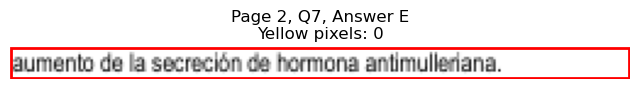


Page 2, Q7 - Selected Answer: A (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=85.0, y0=651.4, x1=114.6, y1=663.5
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 159
Page 2, Q8, A: Yellow percentage: 0.0%


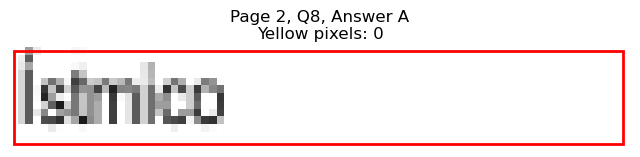

Page 2, Q8 - B: Detected box: x0=85.0, y0=663.4, x1=119.4, y1=675.5
Page 2, Q8, B: Yellow pixels: 0
Page 2, Q8, B: Total non-white pixels: 164
Page 2, Q8, B: Yellow percentage: 0.0%


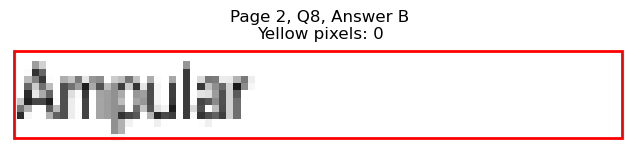

Page 2, Q8 - C: Detected box: x0=85.0, y0=675.4, x1=117.0, y1=687.5
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 160
Page 2, Q8, C: Yellow percentage: 0.0%


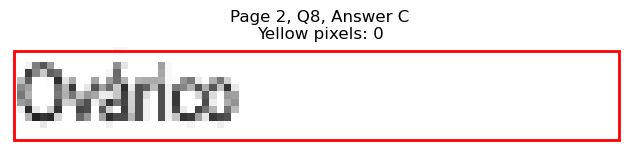

Page 2, Q8 - D: Detected box: x0=336.7, y0=651.4, x1=377.8, y1=663.5
Page 2, Q8, D: Yellow pixels: 1012
Page 2, Q8, D: Total non-white pixels: 1196
Page 2, Q8, D: Yellow percentage: 84.6%


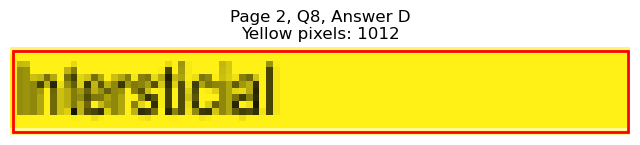

Page 2, Q8 - E: Detected box: x0=336.7, y0=663.4, x1=403.2, y1=675.5
Page 2, Q8, E: Yellow pixels: 118
Page 2, Q8, E: Total non-white pixels: 473
Page 2, Q8, E: Yellow percentage: 24.9%


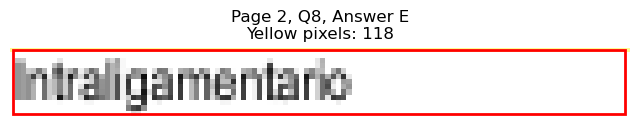


Page 2, Q8 - Selected Answer: D (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=85.0, y0=711.7, x1=197.5, y1=723.8
Page 2, Q9, A: Yellow pixels: 0
Page 2, Q9, A: Total non-white pixels: 554
Page 2, Q9, A: Yellow percentage: 0.0%


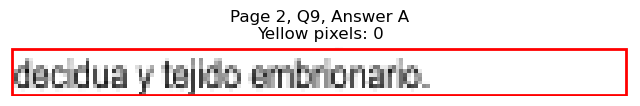

Page 2, Q9 - B: Detected box: x0=85.0, y0=723.7, x1=156.7, y1=735.8
Page 2, Q9, B: Yellow pixels: 0
Page 2, Q9, B: Total non-white pixels: 346
Page 2, Q9, B: Yellow percentage: 0.0%


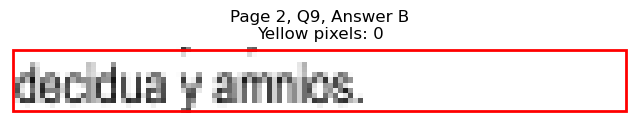

Page 2, Q9 - C: Detected box: x0=85.0, y0=735.8, x1=179.8, y1=747.9
Page 2, Q9, C: Yellow pixels: 0
Page 2, Q9, C: Total non-white pixels: 440
Page 2, Q9, C: Yellow percentage: 0.0%


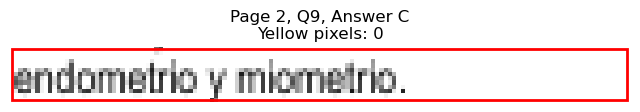

Page 2, Q9 - D: Detected box: x0=336.7, y0=711.7, x1=438.7, y1=723.8
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 663
Page 2, Q9, D: Yellow percentage: 0.0%


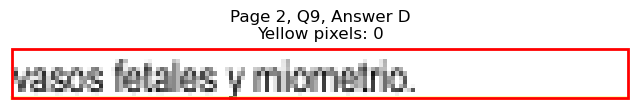

Page 2, Q9 - E: Detected box: x0=336.7, y0=723.7, x1=420.9, y1=735.8
Page 2, Q9, E: Yellow pixels: 1276
Page 2, Q9, E: Total non-white pixels: 1755
Page 2, Q9, E: Yellow percentage: 72.7%


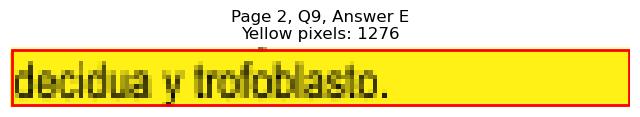


Page 2, Q9 - Selected Answer: E (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=103.7, y1=121.3
Page 3, Q1, A: Yellow pixels: 70
Page 3, Q1, A: Total non-white pixels: 154
Page 3, Q1, A: Yellow percentage: 45.5%


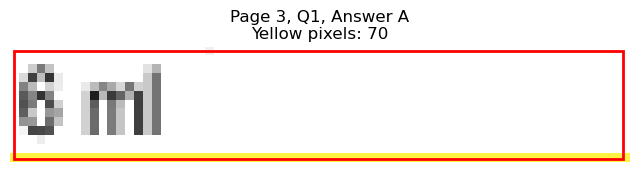

Page 3, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=110.8, y1=133.3
Page 3, Q1, B: Yellow pixels: 825
Page 3, Q1, B: Total non-white pixels: 1001
Page 3, Q1, B: Yellow percentage: 82.4%


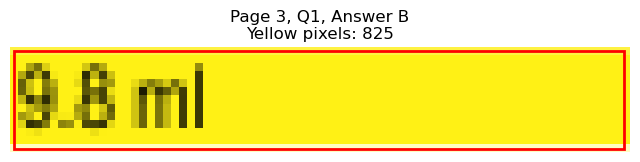

Page 3, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=110.8, y1=145.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 183
Page 3, Q1, C: Yellow percentage: 0.0%


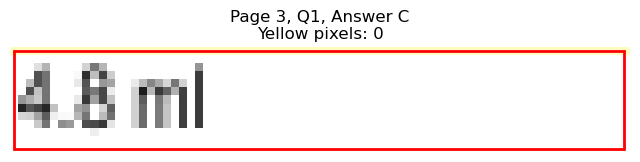

Page 3, Q1 - D: Detected box: x0=336.7, y0=109.2, x1=367.3, y1=121.3
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 122
Page 3, Q1, D: Yellow percentage: 0.0%


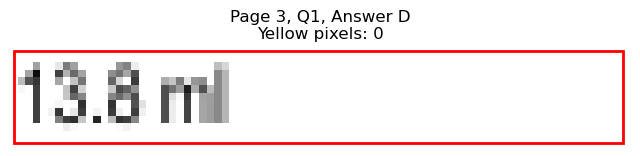

Page 3, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=369.7, y1=133.3
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 111
Page 3, Q1, E: Yellow percentage: 0.0%


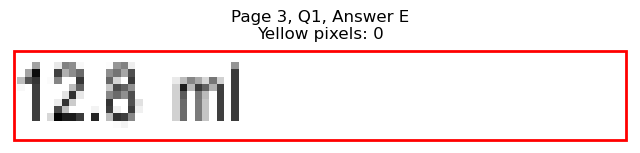


Page 3, Q1 - Selected Answer: B (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=149.7, y1=181.5
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 344
Page 3, Q2, A: Yellow percentage: 0.0%


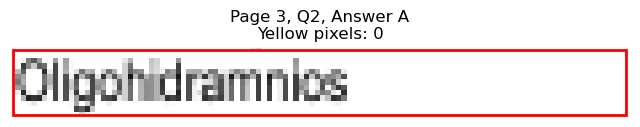

Page 3, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=130.9, y1=193.5
Page 3, Q2, B: Yellow pixels: 97
Page 3, Q2, B: Total non-white pixels: 349
Page 3, Q2, B: Yellow percentage: 27.8%


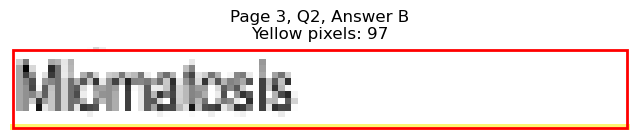

Page 3, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=134.8, y1=205.5
Page 3, Q2, C: Yellow pixels: 1086
Page 3, Q2, C: Total non-white pixels: 1313
Page 3, Q2, C: Yellow percentage: 82.7%


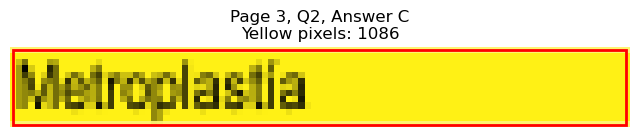

Page 3, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=420.4, y1=181.5
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 388
Page 3, Q2, D: Yellow percentage: 0.0%


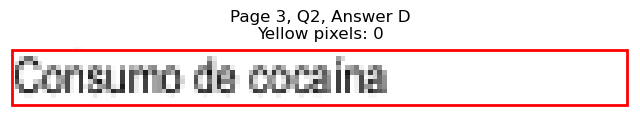

Page 3, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=386.0, y1=193.5
Page 3, Q2, E: Yellow pixels: 0
Page 3, Q2, E: Total non-white pixels: 250
Page 3, Q2, E: Yellow percentage: 0.0%


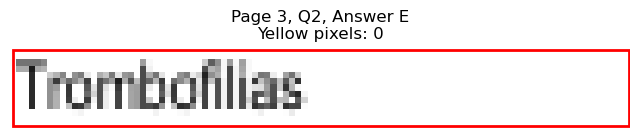


Page 3, Q2 - Selected Answer: C (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=159.6, y1=253.8
Page 3, Q3, A: Yellow pixels: 1191
Page 3, Q3, A: Total non-white pixels: 1638
Page 3, Q3, A: Yellow percentage: 72.7%


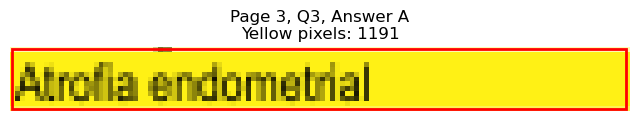

Page 3, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=172.1, y1=265.8
Page 3, Q3, B: Yellow pixels: 139
Page 3, Q3, B: Total non-white pixels: 586
Page 3, Q3, B: Yellow percentage: 23.7%


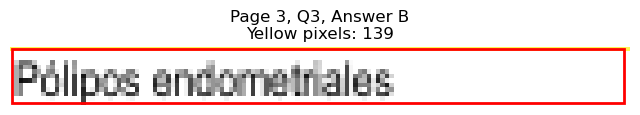

Page 3, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=177.9, y1=277.9
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 505
Page 3, Q3, C: Yellow percentage: 0.0%


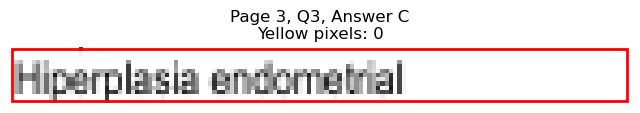

Page 3, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=424.4, y1=253.8
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 436
Page 3, Q3, D: Yellow percentage: 0.0%


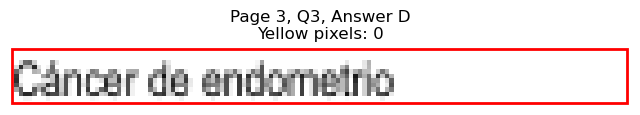

Page 3, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=404.6, y1=265.8
Page 3, Q3, E: Yellow pixels: 0
Page 3, Q3, E: Total non-white pixels: 342
Page 3, Q3, E: Yellow percentage: 0.0%


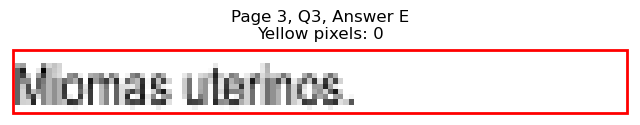


Page 3, Q3 - Selected Answer: A (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=132.9, y1=326.0
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 219
Page 3, Q4, A: Yellow percentage: 0.0%


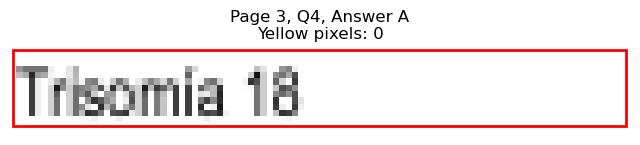

Page 3, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=132.9, y1=338.2
Page 3, Q4, B: Yellow pixels: 99
Page 3, Q4, B: Total non-white pixels: 317
Page 3, Q4, B: Yellow percentage: 31.2%


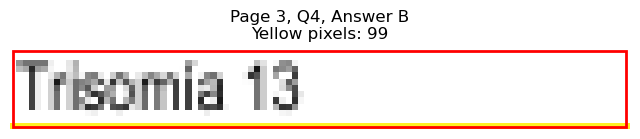

Page 3, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=164.4, y1=350.2
Page 3, Q4, C: Yellow pixels: 1269
Page 3, Q4, C: Total non-white pixels: 1703
Page 3, Q4, C: Yellow percentage: 74.5%


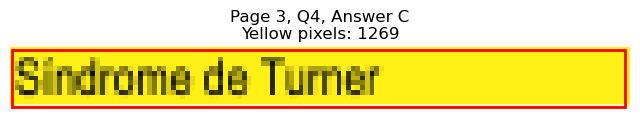

Page 3, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=412.8, y1=326.0
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 348
Page 3, Q4, D: Yellow percentage: 0.0%


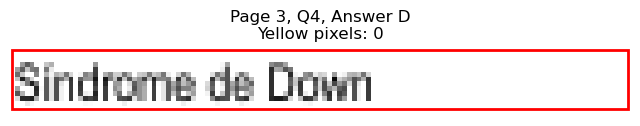

Page 3, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=420.9, y1=338.2
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 387
Page 3, Q4, E: Yellow percentage: 0.0%


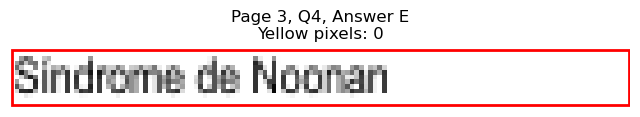


Page 3, Q4 - Selected Answer: C (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=148.2, y1=386.3
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 349
Page 3, Q5, A: Yellow percentage: 0.0%


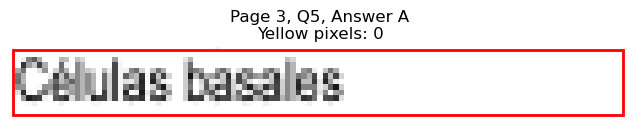

Page 3, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=127.1, y1=398.4
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 207
Page 3, Q5, B: Yellow percentage: 0.0%


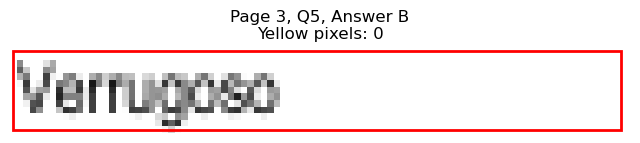

Page 3, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=121.8, y1=410.4
Page 3, Q5, C: Yellow pixels: 0
Page 3, Q5, C: Total non-white pixels: 177
Page 3, Q5, C: Yellow percentage: 0.0%


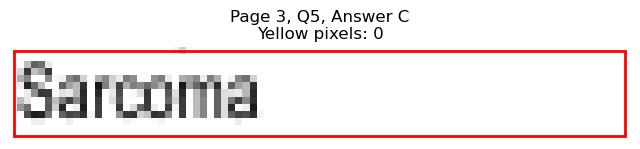

Page 3, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=379.3, y1=386.3
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 224
Page 3, Q5, D: Yellow percentage: 0.0%


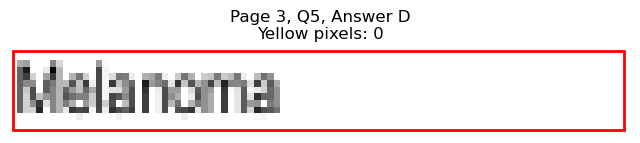

Page 3, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=379.3, y1=398.4
Page 3, Q5, E: Yellow pixels: 955
Page 3, Q5, E: Total non-white pixels: 1222
Page 3, Q5, E: Yellow percentage: 78.2%


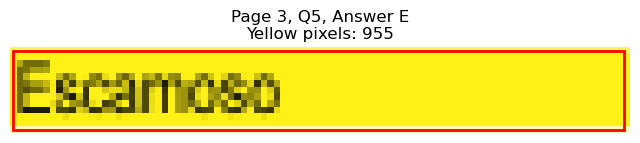


Page 3, Q5 - Selected Answer: E (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=155.8, y1=446.5
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 366
Page 3, Q6, A: Yellow percentage: 0.0%


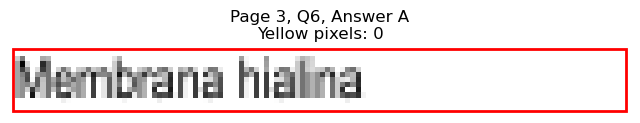

Page 3, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=120.4, y1=458.7
Page 3, Q6, B: Yellow pixels: 976
Page 3, Q6, B: Total non-white pixels: 1131
Page 3, Q6, B: Yellow percentage: 86.3%


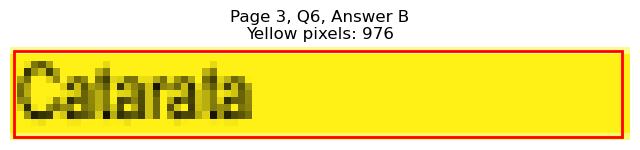

Page 3, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=218.1, y1=470.7
Page 3, Q6, C: Yellow pixels: 185
Page 3, Q6, C: Total non-white pixels: 876
Page 3, Q6, C: Yellow percentage: 21.1%


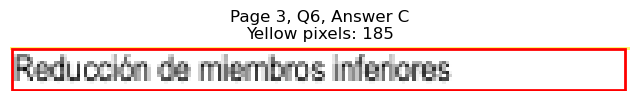

Page 3, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=440.6, y1=446.5
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 539
Page 3, Q6, D: Yellow percentage: 0.0%


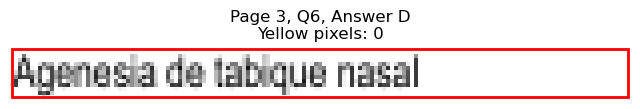

Page 3, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=380.2, y1=458.7
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 252
Page 3, Q6, E: Yellow percentage: 0.0%


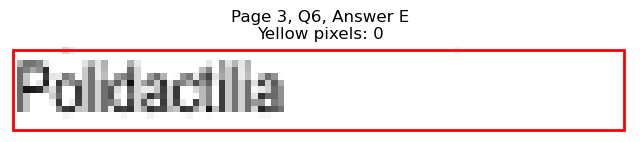


Page 3, Q6 - Selected Answer: B (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=97.0, y1=530.9
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 49
Page 3, Q7, A: Yellow percentage: 0.0%


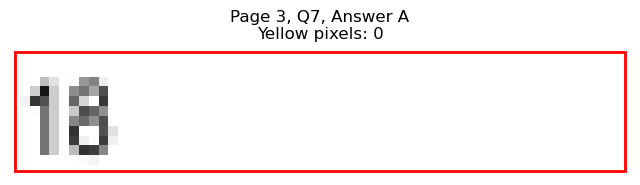

Page 3, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=97.0, y1=543.0
Page 3, Q7, B: Yellow pixels: 717
Page 3, Q7, B: Total non-white pixels: 819
Page 3, Q7, B: Yellow percentage: 87.5%


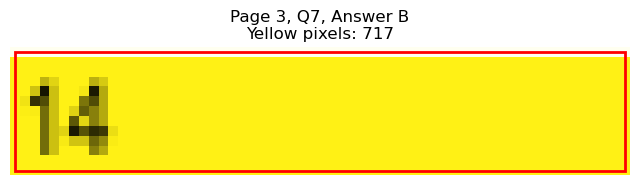

Page 3, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=97.0, y1=555.0
Page 3, Q7, C: Yellow pixels: 63
Page 3, Q7, C: Total non-white pixels: 110
Page 3, Q7, C: Yellow percentage: 57.3%


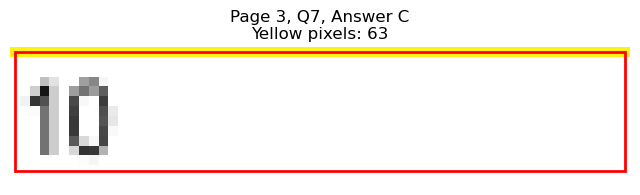

Page 3, Q7 - D: Detected box: x0=336.7, y0=518.8, x1=348.7, y1=530.9
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 52
Page 3, Q7, D: Yellow percentage: 0.0%


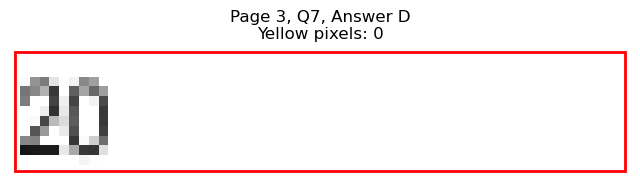

Page 3, Q7 - E: Detected box: x0=336.7, y0=530.9, x1=348.7, y1=543.0
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 45
Page 3, Q7, E: Yellow percentage: 0.0%


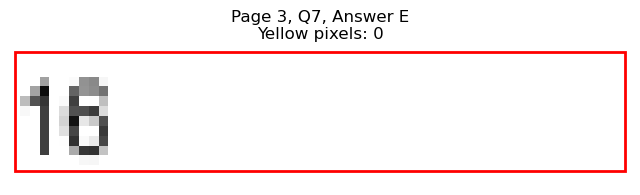


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=85.0, y0=615.2, x1=181.7, y1=627.3
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 514
Page 3, Q8, A: Yellow percentage: 0.0%


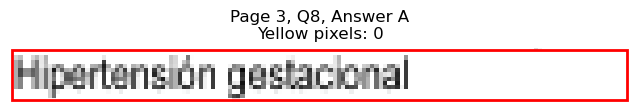

Page 3, Q8 - B: Detected box: x0=85.0, y0=627.3, x1=237.2, y1=639.4
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 767
Page 3, Q8, B: Yellow percentage: 0.0%


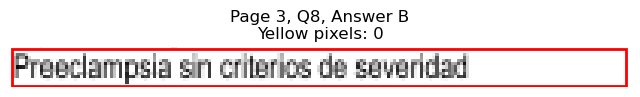

Page 3, Q8 - C: Detected box: x0=85.0, y0=639.3, x1=182.2, y1=651.4
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 491
Page 3, Q8, C: Yellow percentage: 0.0%


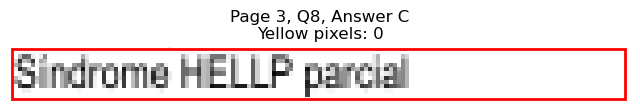

Page 3, Q8 - D: Detected box: x0=85.0, y0=651.4, x1=296.1, y1=663.5
Page 3, Q8, D: Yellow pixels: 263
Page 3, Q8, D: Total non-white pixels: 1356
Page 3, Q8, D: Yellow percentage: 19.4%


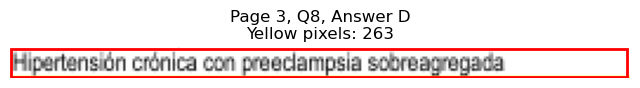

Page 3, Q8 - E: Detected box: x0=85.0, y0=663.4, x1=240.1, y1=675.5
Page 3, Q8, E: Yellow pixels: 2064
Page 3, Q8, E: Total non-white pixels: 2691
Page 3, Q8, E: Yellow percentage: 76.7%


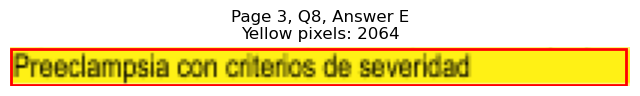


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=85.0, y0=723.7, x1=134.3, y1=735.8
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 243
Page 3, Q9, A: Yellow percentage: 0.0%


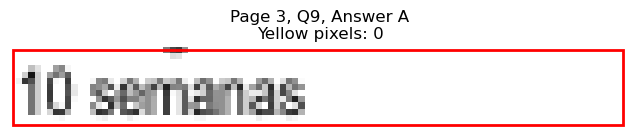

Page 3, Q9 - B: Detected box: x0=85.0, y0=735.8, x1=129.5, y1=747.9
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 219
Page 3, Q9, B: Yellow percentage: 0.0%


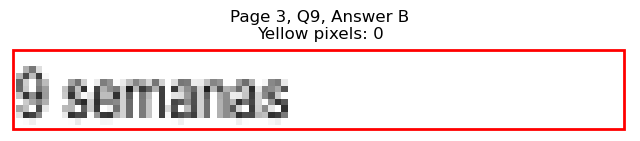

Page 3, Q9 - C: Detected box: x0=85.0, y0=747.8, x1=134.3, y1=759.9
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 238
Page 3, Q9, C: Yellow percentage: 0.0%


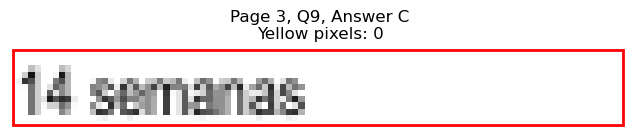

Page 3, Q9 - D: Detected box: x0=336.7, y0=723.7, x1=386.0, y1=735.8
Page 3, Q9, D: Yellow pixels: 1022
Page 3, Q9, D: Total non-white pixels: 1300
Page 3, Q9, D: Yellow percentage: 78.6%


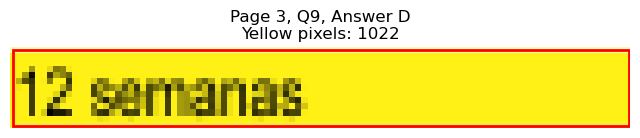

Page 3, Q9 - E: Detected box: x0=336.7, y0=735.8, x1=386.0, y1=747.9
Page 3, Q9, E: Yellow pixels: 100
Page 3, Q9, E: Total non-white pixels: 322
Page 3, Q9, E: Yellow percentage: 31.1%


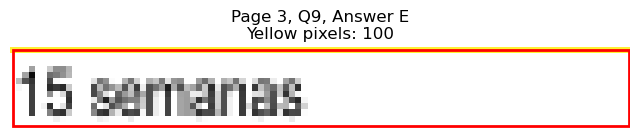


Page 3, Q9 - Selected Answer: D (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=272.7, y1=109.2
Page 4, Q1, A: Yellow pixels: 1537
Page 4, Q1, A: Total non-white pixels: 2485
Page 4, Q1, A: Yellow percentage: 61.9%


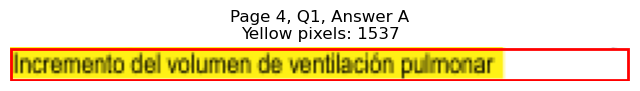

Page 4, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=262.6, y1=121.3
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 1078
Page 4, Q1, B: Yellow percentage: 0.0%


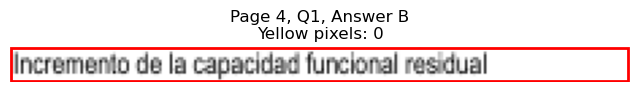

Page 4, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=256.4, y1=133.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 807
Page 4, Q1, C: Yellow percentage: 0.0%


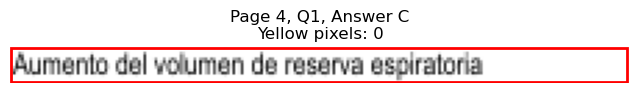

Page 4, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=463.5, y1=109.2
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 659
Page 4, Q1, D: Yellow percentage: 0.0%


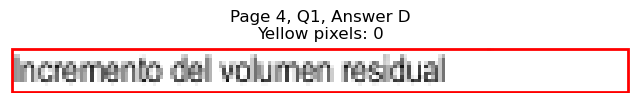

Page 4, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=493.2, y1=121.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 829
Page 4, Q1, E: Yellow percentage: 0.0%


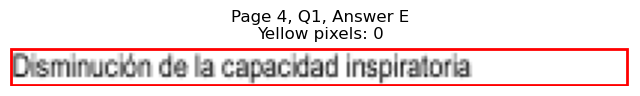


Page 4, Q1 - Selected Answer: A (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=70.8, y0=181.4, x1=79.0, y1=193.5
Page 4, Q2, A: Yellow pixels: 721
Page 4, Q2, A: Total non-white pixels: 767
Page 4, Q2, A: Yellow percentage: 94.0%


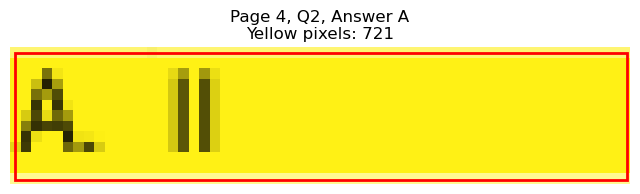

Page 4, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=94.6, y1=205.5
Page 4, Q2, B: Yellow pixels: 61
Page 4, Q2, B: Total non-white pixels: 109
Page 4, Q2, B: Yellow percentage: 56.0%


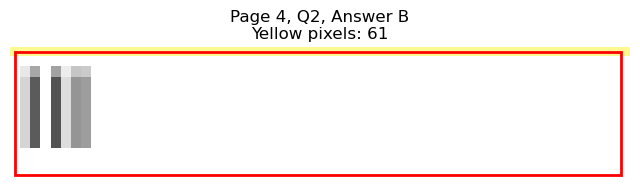

Page 4, Q2 - C: Detected box: x0=70.8, y0=205.5, x1=79.5, y1=217.7
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 51
Page 4, Q2, C: Yellow percentage: 0.0%


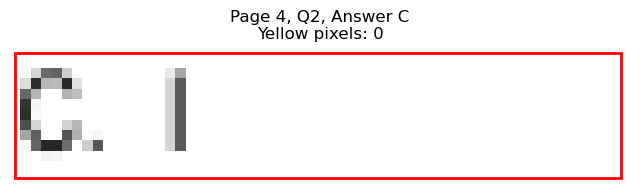

Page 4, Q2 - D: Detected box: x0=336.7, y0=434.4, x1=347.2, y1=446.5
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 77
Page 4, Q2, D: Yellow percentage: 0.0%


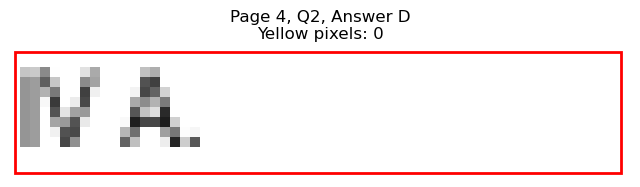

Page 4, Q2 - E: Detected box: x0=322.5, y0=193.4, x1=330.7, y1=205.5
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 58
Page 4, Q2, E: Yellow percentage: 0.0%


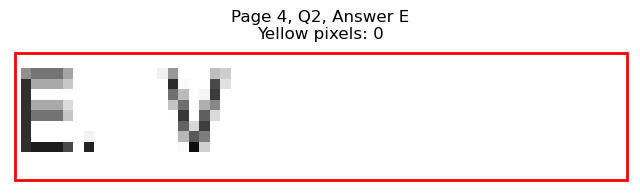


Page 4, Q2 - Selected Answer: A (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=85.0, y0=241.7, x1=190.4, y1=253.8
Page 4, Q3, A: Yellow pixels: 1455
Page 4, Q3, A: Total non-white pixels: 2041
Page 4, Q3, A: Yellow percentage: 71.3%


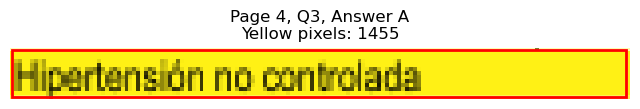

Page 4, Q3 - B: Detected box: x0=85.0, y0=253.7, x1=235.5, y1=265.8
Page 4, Q3, B: Yellow pixels: 188
Page 4, Q3, B: Total non-white pixels: 915
Page 4, Q3, B: Yellow percentage: 20.5%


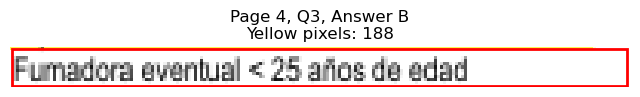

Page 4, Q3 - C: Detected box: x0=85.0, y0=265.8, x1=210.9, y1=277.9
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 656
Page 4, Q3, C: Yellow percentage: 0.0%


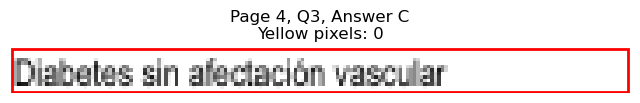

Page 4, Q3 - D: Detected box: x0=336.7, y0=241.7, x1=446.3, y1=253.8
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 557
Page 4, Q3, D: Yellow percentage: 0.0%


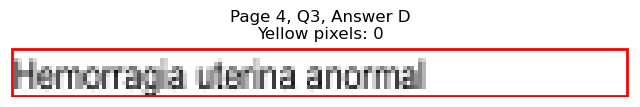

Page 4, Q3 - E: Detected box: x0=336.7, y0=253.7, x1=455.4, y1=265.8
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 626
Page 4, Q3, E: Yellow percentage: 0.0%


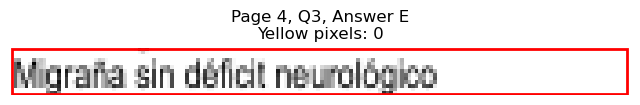


Page 4, Q3 - Selected Answer: A (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=85.0, y0=301.9, x1=222.4, y1=314.0
Page 4, Q4, A: Yellow pixels: 1710
Page 4, Q4, A: Total non-white pixels: 2459
Page 4, Q4, A: Yellow percentage: 69.5%


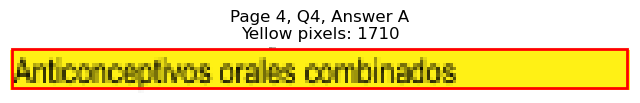

Page 4, Q4 - B: Detected box: x0=85.0, y0=313.9, x1=177.9, y1=326.0
Page 4, Q4, B: Yellow pixels: 142
Page 4, Q4, B: Total non-white pixels: 606
Page 4, Q4, B: Yellow percentage: 23.4%


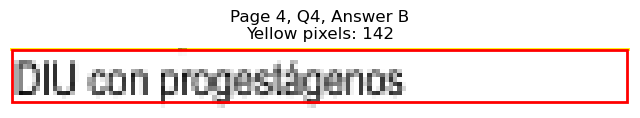

Page 4, Q4 - C: Detected box: x0=85.0, y0=326.1, x1=167.3, y1=338.2
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 424
Page 4, Q4, C: Yellow percentage: 0.0%


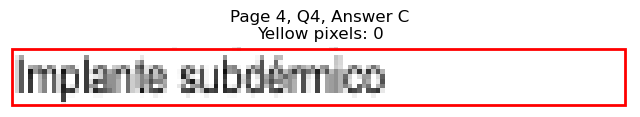

Page 4, Q4 - D: Detected box: x0=336.7, y0=301.9, x1=404.6, y1=314.0
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 333
Page 4, Q4, D: Yellow percentage: 0.0%


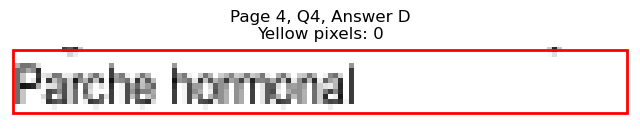

Page 4, Q4 - E: Detected box: x0=336.7, y0=313.9, x1=417.1, y1=326.0
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 415
Page 4, Q4, E: Yellow percentage: 0.0%


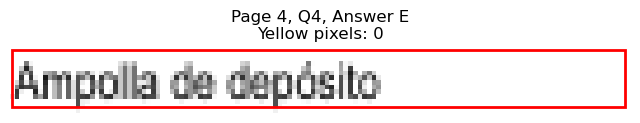


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=85.0, y0=362.2, x1=171.6, y1=374.3
Page 4, Q5, A: Yellow pixels: 138
Page 4, Q5, A: Total non-white pixels: 603
Page 4, Q5, A: Yellow percentage: 22.9%


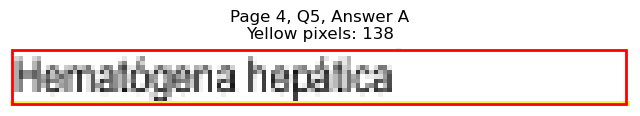

Page 4, Q5 - B: Detected box: x0=85.0, y0=374.2, x1=175.0, y1=386.3
Page 4, Q5, B: Yellow pixels: 1310
Page 4, Q5, B: Total non-white pixels: 1833
Page 4, Q5, B: Yellow percentage: 71.5%


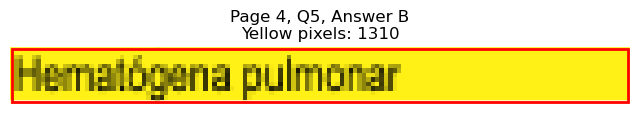

Page 4, Q5 - C: Detected box: x0=85.0, y0=386.3, x1=148.7, y1=398.4
Page 4, Q5, C: Yellow pixels: 1
Page 4, Q5, C: Total non-white pixels: 445
Page 4, Q5, C: Yellow percentage: 0.2%


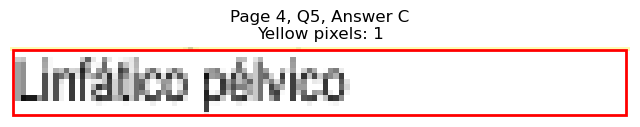

Page 4, Q5 - D: Detected box: x0=336.7, y0=362.2, x1=413.2, y1=374.3
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 382
Page 4, Q5, D: Yellow percentage: 0.0%


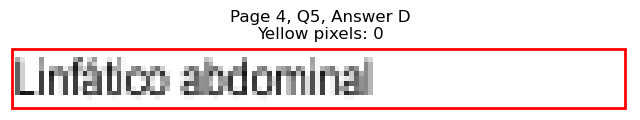

Page 4, Q5 - E: Detected box: x0=336.7, y0=374.2, x1=432.4, y1=386.3
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 485
Page 4, Q5, E: Yellow percentage: 0.0%


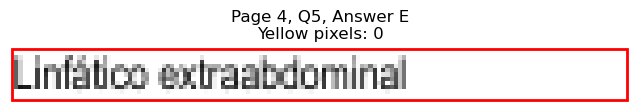


Page 4, Q5 - Selected Answer: B (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=94.6, y1=446.5
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 36
Page 4, Q6, A: Yellow percentage: 0.0%


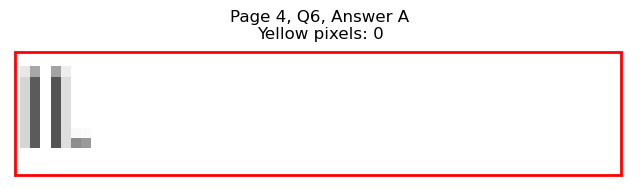

Page 4, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=97.0, y1=458.7
Page 4, Q6, B: Yellow pixels: 779
Page 4, Q6, B: Total non-white pixels: 819
Page 4, Q6, B: Yellow percentage: 95.1%


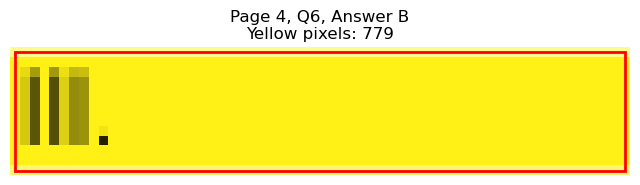

Page 4, Q6 - C: Detected box: x0=70.8, y0=458.6, x1=79.5, y1=470.7
Page 4, Q6, C: Yellow pixels: 60
Page 4, Q6, C: Total non-white pixels: 114
Page 4, Q6, C: Yellow percentage: 52.6%


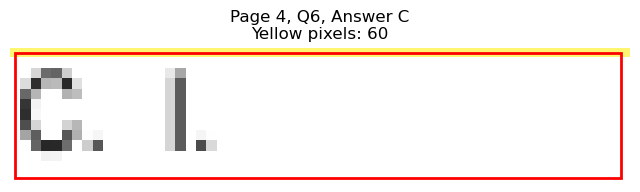

Page 4, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=357.8, y1=446.5
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 77
Page 4, Q6, D: Yellow percentage: 0.0%


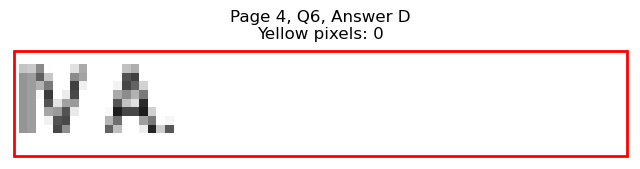

Page 4, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=357.8, y1=458.7
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 87
Page 4, Q6, E: Yellow percentage: 0.0%


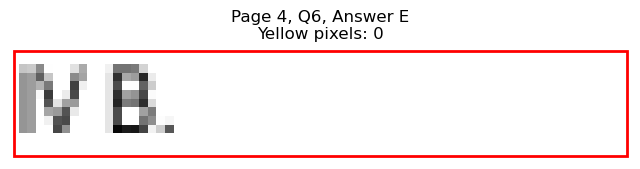


Page 4, Q6 - Selected Answer: B (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=85.0, y0=506.8, x1=95.6, y1=518.9
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 47
Page 4, Q7, A: Yellow percentage: 0.0%


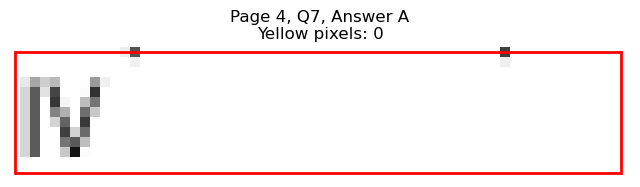

Page 4, Q7 - B: Detected box: x0=70.8, y0=518.8, x1=79.0, y1=530.9
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 71
Page 4, Q7, B: Yellow percentage: 0.0%


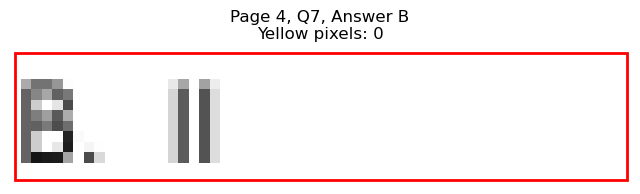

Page 4, Q7 - C: Detected box: x0=85.0, y0=530.9, x1=94.6, y1=543.0
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 48
Page 4, Q7, C: Yellow percentage: 0.0%


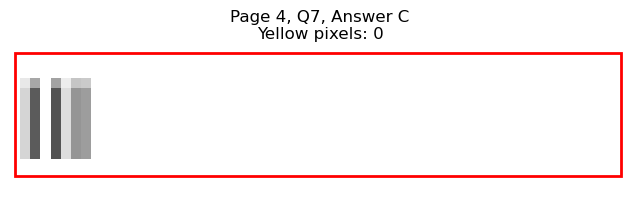

Page 4, Q7 - D: Detected box: x0=322.5, y0=506.8, x1=331.2, y1=518.9
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 121
Page 4, Q7, D: Yellow percentage: 0.0%


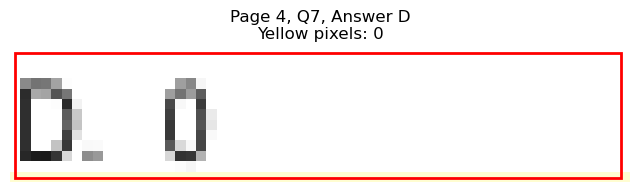

Page 4, Q7 - E: Detected box: x0=322.5, y0=518.8, x1=330.7, y1=530.9
Page 4, Q7, E: Yellow pixels: 664
Page 4, Q7, E: Total non-white pixels: 767
Page 4, Q7, E: Yellow percentage: 86.6%


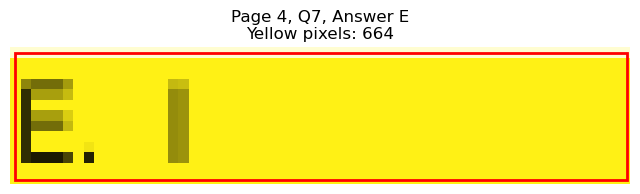


Page 4, Q7 - Selected Answer: E (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=85.0, y0=567.1, x1=200.8, y1=579.2
Page 4, Q8, A: Yellow pixels: 167
Page 4, Q8, A: Total non-white pixels: 727
Page 4, Q8, A: Yellow percentage: 23.0%


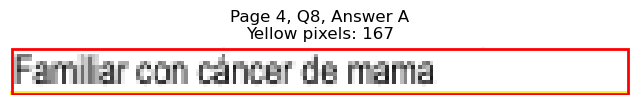

Page 4, Q8 - B: Detected box: x0=85.0, y0=579.1, x1=293.8, y1=591.2
Page 4, Q8, B: Yellow pixels: 2254
Page 4, Q8, B: Total non-white pixels: 3380
Page 4, Q8, B: Yellow percentage: 66.7%


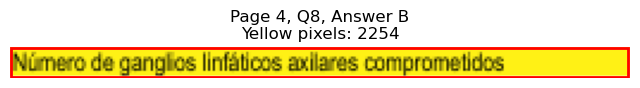

Page 4, Q8 - C: Detected box: x0=85.0, y0=591.2, x1=162.5, y1=603.3
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 528
Page 4, Q8, C: Yellow percentage: 0.0%


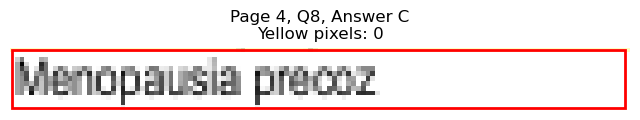

Page 4, Q8 - D: Detected box: x0=85.0, y0=603.2, x1=248.2, y1=615.3
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 791
Page 4, Q8, D: Yellow percentage: 0.0%


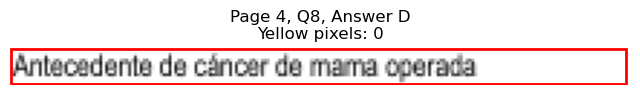

Page 4, Q8 - E: Detected box: x0=85.0, y0=615.2, x1=214.7, y1=627.3
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 678
Page 4, Q8, E: Yellow percentage: 0.0%


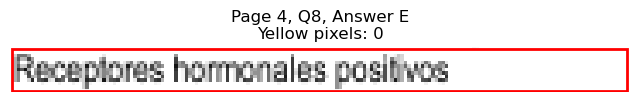


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=85.0, y0=687.5, x1=178.8, y1=699.7
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 513
Page 4, Q9, A: Yellow percentage: 0.0%


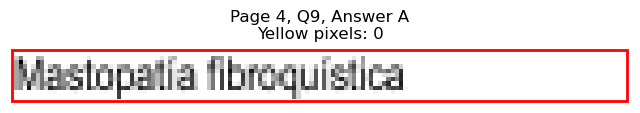

Page 4, Q9 - B: Detected box: x0=85.0, y0=699.5, x1=115.6, y1=711.7
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 145
Page 4, Q9, B: Yellow percentage: 0.0%


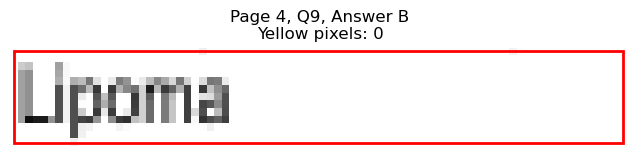

Page 4, Q9 - C: Detected box: x0=85.0, y0=711.7, x1=151.0, y1=723.8
Page 4, Q9, C: Yellow pixels: 1117
Page 4, Q9, C: Total non-white pixels: 1521
Page 4, Q9, C: Yellow percentage: 73.4%


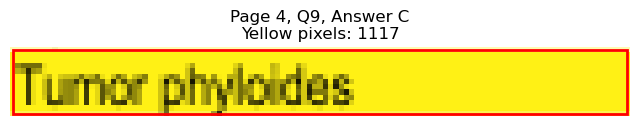

Page 4, Q9 - D: Detected box: x0=336.7, y0=687.5, x1=380.7, y1=699.7
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 212
Page 4, Q9, D: Yellow percentage: 0.0%


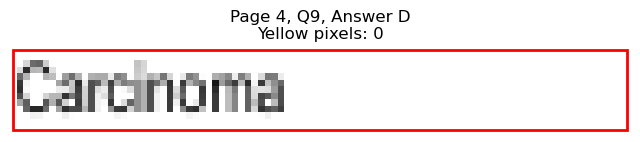

Page 4, Q9 - E: Detected box: x0=336.7, y0=699.5, x1=368.2, y1=711.7
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 181
Page 4, Q9, E: Yellow percentage: 0.0%


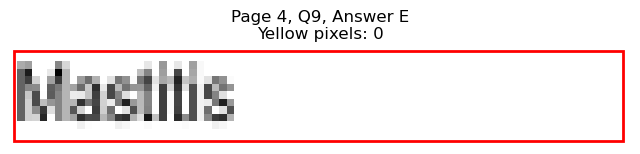


Page 4, Q9 - Selected Answer: C (based on yellow pixel count)





Page 5: Found 10 questions
Page 5, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=144.4, y1=109.2
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 333
Page 5, Q1, A: Yellow percentage: 0.0%


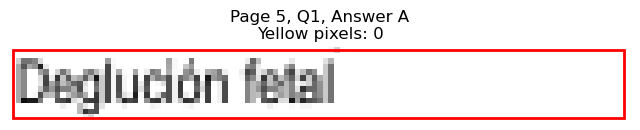

Page 5, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=222.4, y1=121.3
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 706
Page 5, Q1, B: Yellow percentage: 0.0%


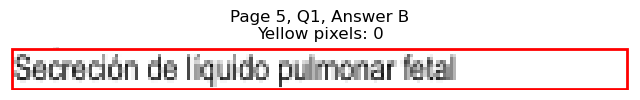

Page 5, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=280.3, y1=133.3
Page 5, Q1, C: Yellow pixels: 247
Page 5, Q1, C: Total non-white pixels: 1242
Page 5, Q1, C: Yellow percentage: 19.9%


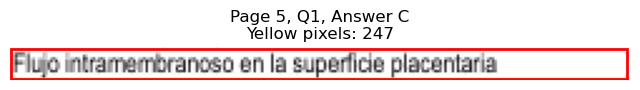

Page 5, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=135.3, y1=145.3
Page 5, Q1, D: Yellow pixels: 1002
Page 5, Q1, D: Total non-white pixels: 1326
Page 5, Q1, D: Yellow percentage: 75.6%


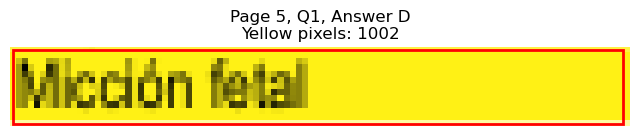

Page 5, Q1 - E: Detected box: x0=85.0, y0=145.3, x1=314.7, y1=157.4
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 1414
Page 5, Q1, E: Yellow percentage: 0.0%


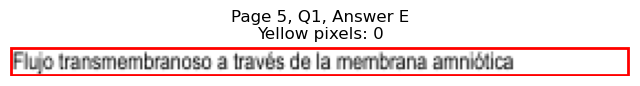


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=239.1, y1=205.5
Page 5, Q2, A: Yellow pixels: 1861
Page 5, Q2, A: Total non-white pixels: 2483
Page 5, Q2, A: Yellow percentage: 74.9%


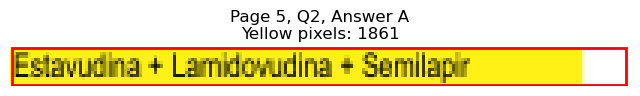

Page 5, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=238.6, y1=217.7
Page 5, Q2, B: Yellow pixels: 190
Page 5, Q2, B: Total non-white pixels: 939
Page 5, Q2, B: Yellow percentage: 20.2%


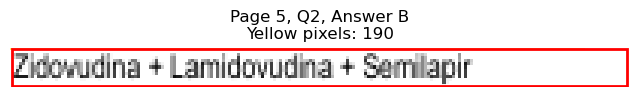

Page 5, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=237.2, y1=229.7
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 740
Page 5, Q2, C: Yellow percentage: 0.0%


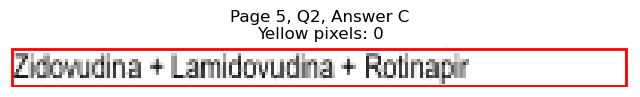

Page 5, Q2 - D: Detected box: x0=336.7, y0=193.4, x1=479.4, y1=205.5
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 712
Page 5, Q2, D: Yellow percentage: 0.0%


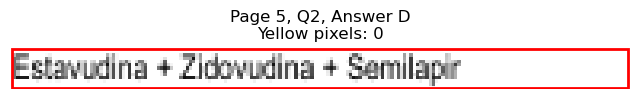

Page 5, Q2 - E: Detected box: x0=336.7, y0=205.5, x1=471.7, y1=217.7
Page 5, Q2, E: Yellow pixels: 0
Page 5, Q2, E: Total non-white pixels: 689
Page 5, Q2, E: Yellow percentage: 0.0%


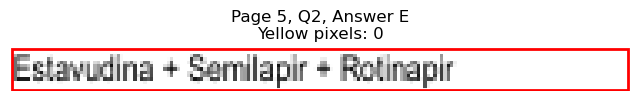


Page 5, Q2 - Selected Answer: A (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=141.0, y1=265.8
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 295
Page 5, Q3, A: Yellow percentage: 0.0%


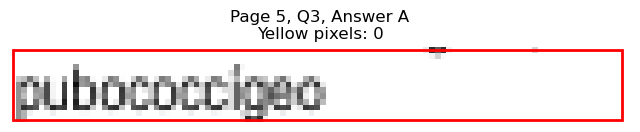

Page 5, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=144.4, y1=277.9
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 319
Page 5, Q3, B: Yellow percentage: 0.0%


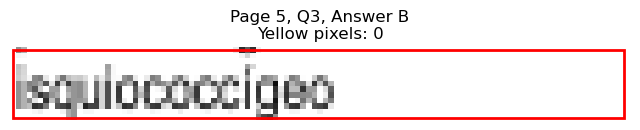

Page 5, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=127.6, y1=289.9
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 220
Page 5, Q3, C: Yellow percentage: 0.0%


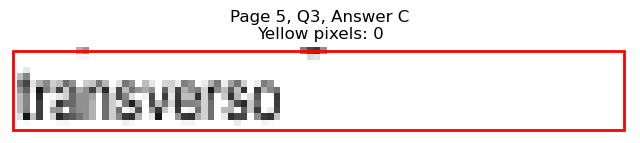

Page 5, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=379.3, y1=265.8
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 226
Page 5, Q3, D: Yellow percentage: 0.0%


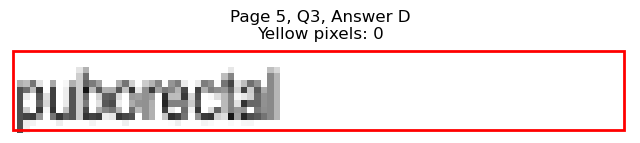

Page 5, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=394.6, y1=277.9
Page 5, Q3, E: Yellow pixels: 1074
Page 5, Q3, E: Total non-white pixels: 1417
Page 5, Q3, E: Yellow percentage: 75.8%


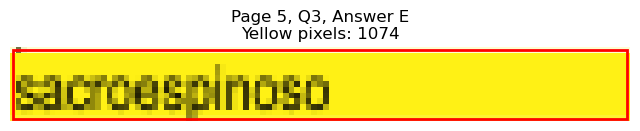


Page 5, Q3 - Selected Answer: E (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=134.3, y1=326.0
Page 5, Q4, A: Yellow pixels: 1013
Page 5, Q4, A: Total non-white pixels: 1414
Page 5, Q4, A: Yellow percentage: 71.6%


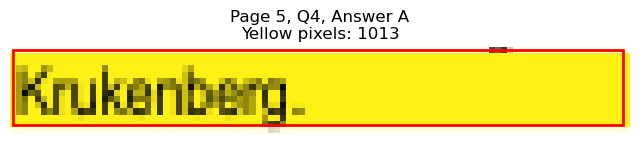

Page 5, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=120.4, y1=338.2
Page 5, Q4, B: Yellow pixels: 0
Page 5, Q4, B: Total non-white pixels: 255
Page 5, Q4, B: Yellow percentage: 0.0%


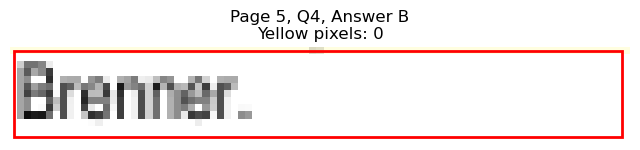

Page 5, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=136.7, y1=350.2
Page 5, Q4, C: Yellow pixels: 0
Page 5, Q4, C: Total non-white pixels: 256
Page 5, Q4, C: Yellow percentage: 0.0%


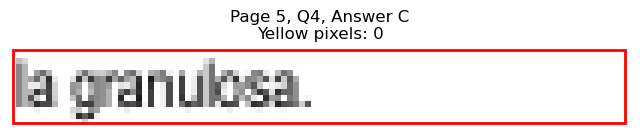

Page 5, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=393.7, y1=326.0
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 278
Page 5, Q4, D: Yellow percentage: 0.0%


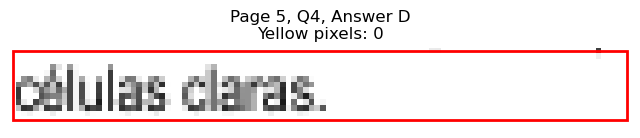

Page 5, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=369.2, y1=338.2
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 183
Page 5, Q4, E: Yellow percentage: 0.0%


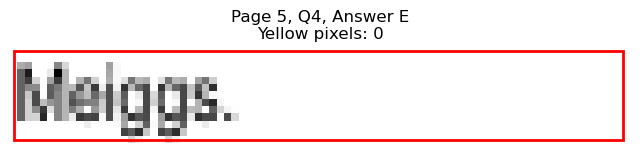


Page 5, Q4 - Selected Answer: A (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=85.0, y0=386.3, x1=135.3, y1=398.4
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 272
Page 5, Q5, A: Yellow percentage: 0.0%


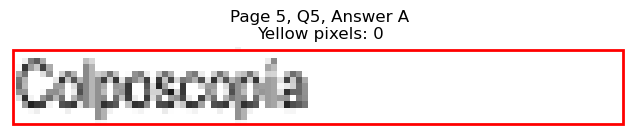

Page 5, Q5 - B: Detected box: x0=85.0, y0=398.3, x1=206.1, y1=410.4
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 612
Page 5, Q5, B: Yellow percentage: 0.0%


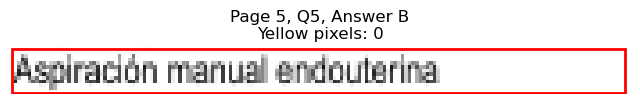

Page 5, Q5 - C: Detected box: x0=85.0, y0=410.4, x1=191.8, y1=422.5
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 570
Page 5, Q5, C: Yellow percentage: 0.0%


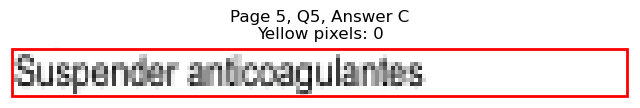

Page 5, Q5 - D: Detected box: x0=336.7, y0=386.3, x1=419.5, y1=398.4
Page 5, Q5, D: Yellow pixels: 1257
Page 5, Q5, D: Total non-white pixels: 1742
Page 5, Q5, D: Yellow percentage: 72.2%


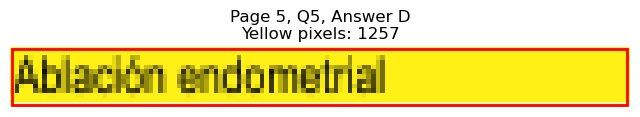

Page 5, Q5 - E: Detected box: x0=336.7, y0=398.3, x1=411.4, y1=410.4
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 498
Page 5, Q5, E: Yellow percentage: 0.0%


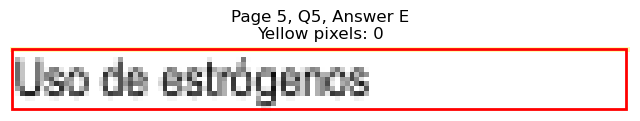


Page 5, Q5 - Selected Answer: D (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=85.0, y0=446.6, x1=118.5, y1=458.7
Page 5, Q6, A: Yellow pixels: 985
Page 5, Q6, A: Total non-white pixels: 1105
Page 5, Q6, A: Yellow percentage: 89.1%


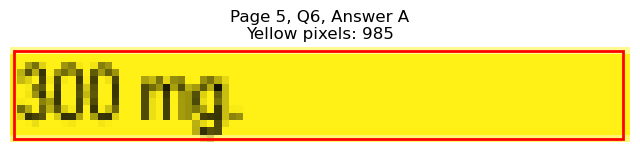

Page 5, Q6 - B: Detected box: x0=85.0, y0=458.6, x1=118.5, y1=470.7
Page 5, Q6, B: Yellow pixels: 85
Page 5, Q6, B: Total non-white pixels: 241
Page 5, Q6, B: Yellow percentage: 35.3%


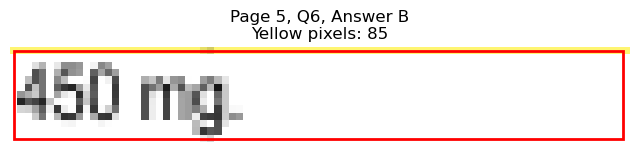

Page 5, Q6 - C: Detected box: x0=85.0, y0=470.7, x1=116.1, y1=482.8
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 156
Page 5, Q6, C: Yellow percentage: 0.0%


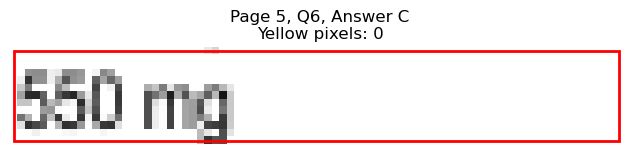

Page 5, Q6 - D: Detected box: x0=336.7, y0=446.6, x1=370.2, y1=458.7
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 154
Page 5, Q6, D: Yellow percentage: 0.0%


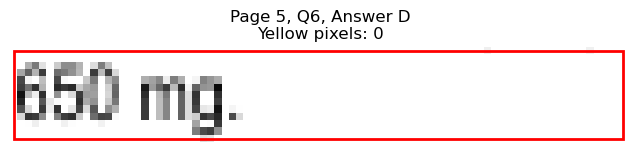

Page 5, Q6 - E: Detected box: x0=336.7, y0=458.6, x1=370.2, y1=470.7
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 150
Page 5, Q6, E: Yellow percentage: 0.0%


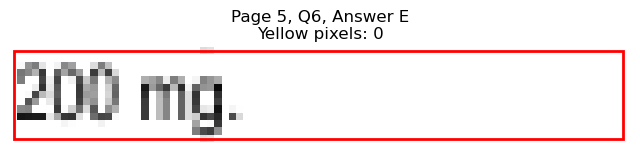


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=85.0, y0=506.8, x1=317.2, y1=518.9
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 1217
Page 5, Q7, A: Yellow percentage: 0.0%


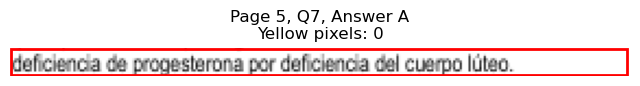

Page 5, Q7 - B: Detected box: x0=85.0, y0=518.8, x1=217.6, y1=530.9
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 664
Page 5, Q7, B: Yellow percentage: 0.0%


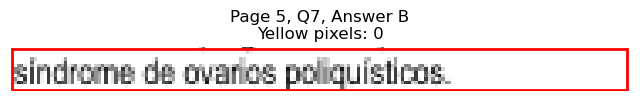

Page 5, Q7 - C: Detected box: x0=85.0, y0=530.9, x1=273.2, y1=543.0
Page 5, Q7, C: Yellow pixels: 240
Page 5, Q7, C: Total non-white pixels: 1439
Page 5, Q7, C: Yellow percentage: 16.7%


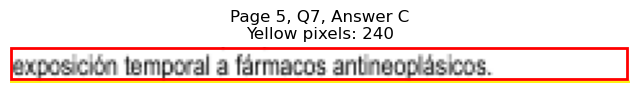

Page 5, Q7 - D: Detected box: x0=85.0, y0=542.9, x1=250.6, y1=555.0
Page 5, Q7, D: Yellow pixels: 1928
Page 5, Q7, D: Total non-white pixels: 2824
Page 5, Q7, D: Yellow percentage: 68.3%


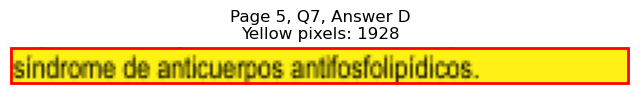

Page 5, Q7 - E: Detected box: x0=85.0, y0=554.9, x1=257.8, y1=567.0
Page 5, Q7, E: Yellow pixels: 221
Page 5, Q7, E: Total non-white pixels: 1119
Page 5, Q7, E: Yellow percentage: 19.7%


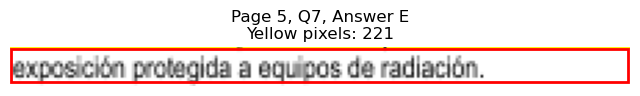


Page 5, Q7 - Selected Answer: D (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=85.0, y0=615.2, x1=94.6, y1=627.3
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 35
Page 5, Q8, A: Yellow percentage: 0.0%


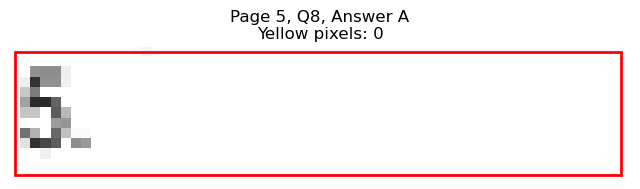

Page 5, Q8 - B: Detected box: x0=85.0, y0=627.3, x1=94.6, y1=639.4
Page 5, Q8, B: Yellow pixels: 0
Page 5, Q8, B: Total non-white pixels: 34
Page 5, Q8, B: Yellow percentage: 0.0%


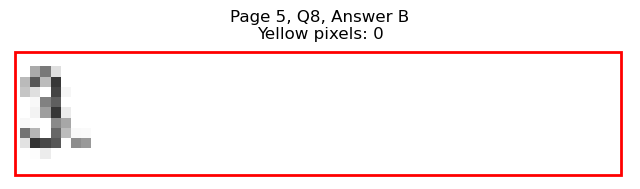

Page 5, Q8 - C: Detected box: x0=85.0, y0=639.3, x1=94.6, y1=651.4
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 29
Page 5, Q8, C: Yellow percentage: 0.0%


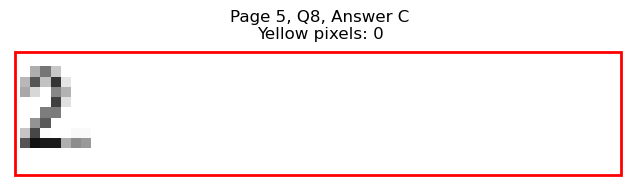

Page 5, Q8 - D: Detected box: x0=336.7, y0=615.2, x1=346.3, y1=627.3
Page 5, Q8, D: Yellow pixels: 709
Page 5, Q8, D: Total non-white pixels: 793
Page 5, Q8, D: Yellow percentage: 89.4%


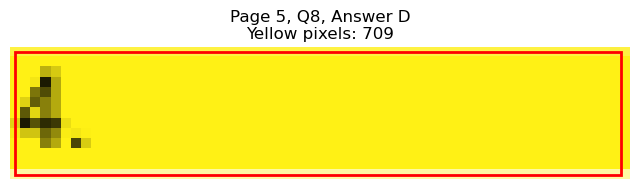

Page 5, Q8 - E: Detected box: x0=336.7, y0=627.3, x1=346.3, y1=639.4
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 94
Page 5, Q8, E: Yellow percentage: 0.0%


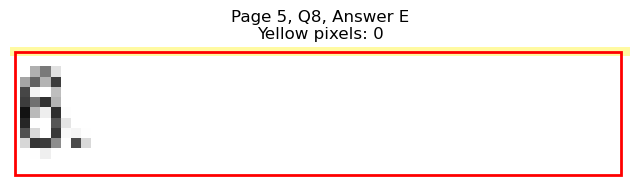


Page 5, Q8 - Selected Answer: D (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=85.0, y0=687.5, x1=98.0, y1=699.7
Page 5, Q9, A: Yellow pixels: 776
Page 5, Q9, A: Total non-white pixels: 832
Page 5, Q9, A: Yellow percentage: 93.3%


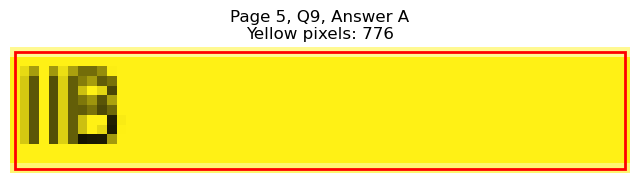

Page 5, Q9 - B: Detected box: x0=85.0, y0=699.5, x1=100.4, y1=711.7
Page 5, Q9, B: Yellow pixels: 67
Page 5, Q9, B: Total non-white pixels: 145
Page 5, Q9, B: Yellow percentage: 46.2%


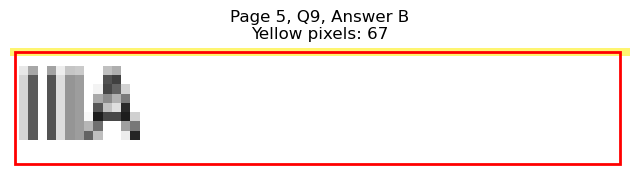

Page 5, Q9 - C: Detected box: x0=85.0, y0=711.7, x1=98.0, y1=723.8
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 60
Page 5, Q9, C: Yellow percentage: 0.0%


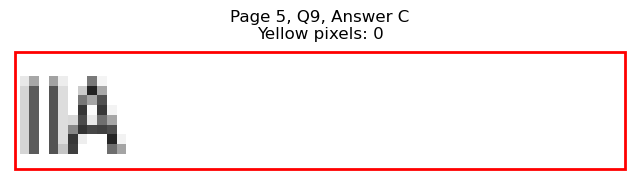

Page 5, Q9 - D: Detected box: x0=336.7, y0=687.5, x1=352.0, y1=699.7
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 84
Page 5, Q9, D: Yellow percentage: 0.0%


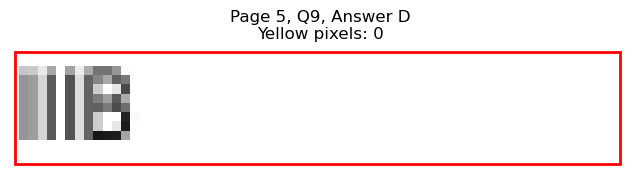

Page 5, Q9 - E: Detected box: x0=336.7, y0=699.5, x1=350.1, y1=711.7
Page 5, Q9, E: Yellow pixels: 0
Page 5, Q9, E: Total non-white pixels: 63
Page 5, Q9, E: Yellow percentage: 0.0%


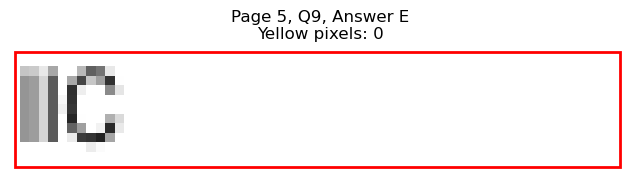


Page 5, Q9 - Selected Answer: A (based on yellow pixel count)




Page 5, Q10 - A: Detected box: x0=85.0, y0=747.8, x1=196.1, y1=759.9
Page 5, Q10, A: Yellow pixels: 0
Page 5, Q10, A: Total non-white pixels: 712
Page 5, Q10, A: Yellow percentage: 0.0%


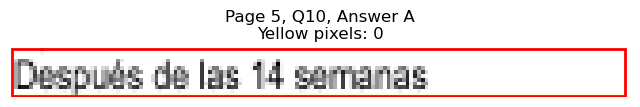

Page 5, Q10 - B: Detected box: x0=85.0, y0=759.8, x1=189.4, y1=771.9
Page 5, Q10, B: Yellow pixels: 1465
Page 5, Q10, B: Total non-white pixels: 2028
Page 5, Q10, B: Yellow percentage: 72.2%


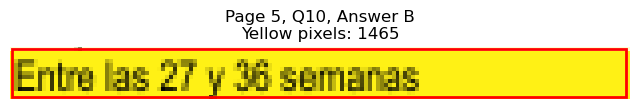

Page 5, Q10 - C: Detected box: x0=85.0, y0=771.9, x1=164.4, y1=784.0
Page 5, Q10, C: Yellow pixels: 129
Page 5, Q10, C: Total non-white pixels: 520
Page 5, Q10, C: Yellow percentage: 24.8%


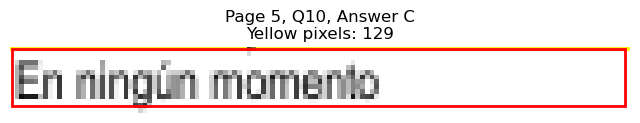

Page 5, Q10 - D: Detected box: x0=336.7, y0=747.8, x1=460.7, y1=759.9
Page 5, Q10, D: Yellow pixels: 0
Page 5, Q10, D: Total non-white pixels: 577
Page 5, Q10, D: Yellow percentage: 0.0%


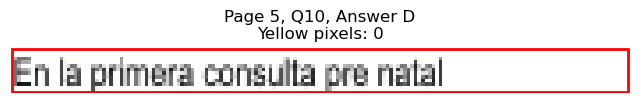

Page 5, Q10 - E: Detected box: x0=336.7, y0=759.8, x1=438.8, y1=771.9
Page 5, Q10, E: Yellow pixels: 0
Page 5, Q10, E: Total non-white pixels: 516
Page 5, Q10, E: Yellow percentage: 0.0%


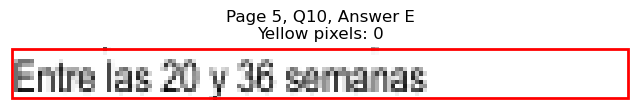


Page 5, Q10 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 9 questions
Page 6, Q1 - A: Detected box: x0=85.0, y0=121.2, x1=143.5, y1=133.3
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 294
Page 6, Q1, A: Yellow percentage: 0.0%


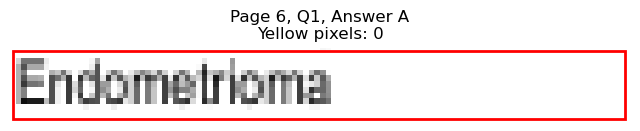

Page 6, Q1 - B: Detected box: x0=85.0, y0=133.2, x1=210.4, y1=145.3
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 658
Page 6, Q1, B: Yellow percentage: 0.0%


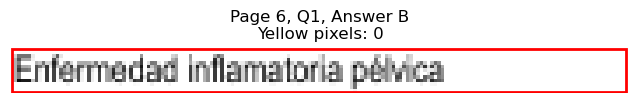

Page 6, Q1 - C: Detected box: x0=85.0, y0=145.3, x1=230.1, y1=157.4
Page 6, Q1, C: Yellow pixels: 1684
Page 6, Q1, C: Total non-white pixels: 2483
Page 6, Q1, C: Yellow percentage: 67.8%


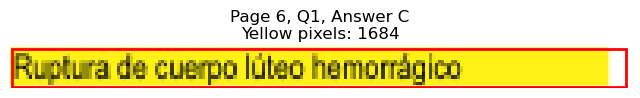

Page 6, Q1 - D: Detected box: x0=336.7, y0=121.2, x1=412.8, y1=133.3
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 384
Page 6, Q1, D: Yellow percentage: 0.0%


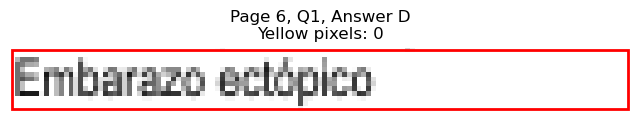

Page 6, Q1 - E: Detected box: x0=336.7, y0=133.2, x1=452.0, y1=145.3
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 547
Page 6, Q1, E: Yellow percentage: 0.0%


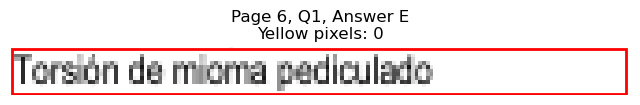


Page 6, Q1 - Selected Answer: C (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=257.8, y1=193.5
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 844
Page 6, Q2, A: Yellow percentage: 0.0%


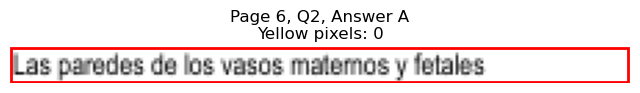

Page 6, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=256.9, y1=205.5
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 843
Page 6, Q2, B: Yellow percentage: 0.0%


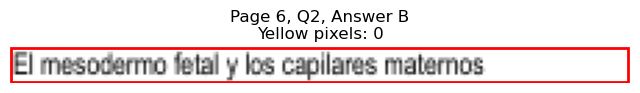

Page 6, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=256.4, y1=217.7
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 854
Page 6, Q2, C: Yellow percentage: 0.0%


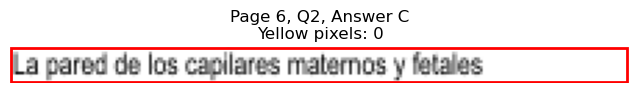

Page 6, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=235.7, y1=229.7
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 789
Page 6, Q2, D: Yellow percentage: 0.0%


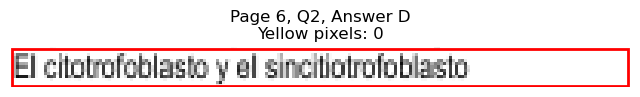

Page 6, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=360.7, y1=241.8
Page 6, Q2, E: Yellow pixels: 2817
Page 6, Q2, E: Total non-white pixels: 4251
Page 6, Q2, E: Yellow percentage: 66.3%


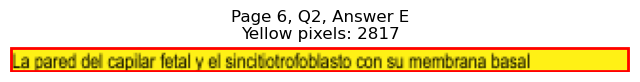


Page 6, Q2 - Selected Answer: E (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=85.0, y0=265.8, x1=115.1, y1=277.9
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 127
Page 6, Q3, A: Yellow percentage: 0.0%


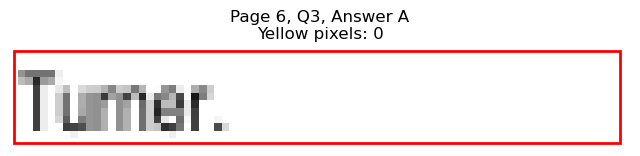

Page 6, Q3 - B: Detected box: x0=85.0, y0=277.8, x1=128.1, y1=289.9
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 217
Page 6, Q3, B: Yellow percentage: 0.0%


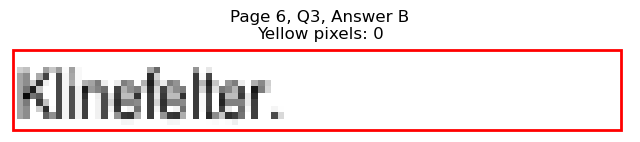

Page 6, Q3 - C: Detected box: x0=85.0, y0=289.9, x1=174.5, y1=302.0
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 460
Page 6, Q3, C: Yellow percentage: 0.0%


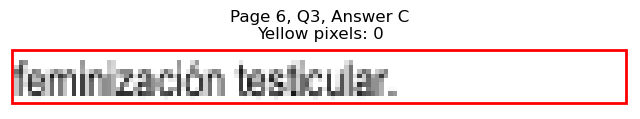

Page 6, Q3 - D: Detected box: x0=336.7, y0=265.8, x1=372.6, y1=277.9
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 271
Page 6, Q3, D: Yellow percentage: 0.0%


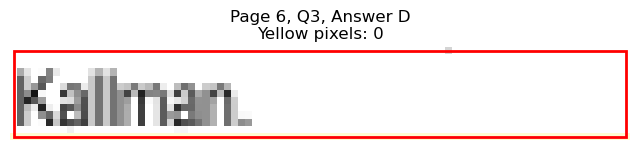

Page 6, Q3 - E: Detected box: x0=336.7, y0=277.8, x1=363.4, y1=289.9
Page 6, Q3, E: Yellow pixels: 832
Page 6, Q3, E: Total non-white pixels: 1014
Page 6, Q3, E: Yellow percentage: 82.1%


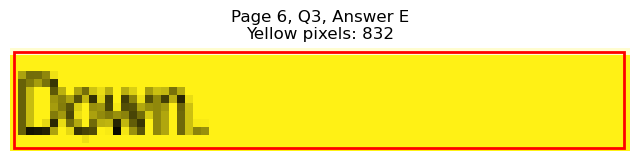


Page 6, Q3 - Selected Answer: E (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=70.8, y0=338.1, x1=79.0, y1=350.2
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 69
Page 6, Q4, A: Yellow percentage: 0.0%


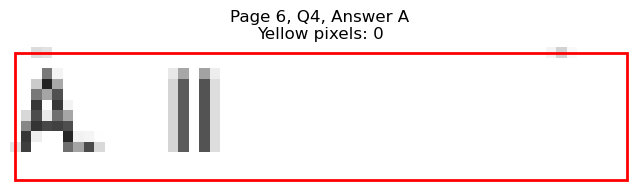

Page 6, Q4 - B: Detected box: x0=85.0, y0=350.2, x1=94.6, y1=362.3
Page 6, Q4, B: Yellow pixels: 693
Page 6, Q4, B: Total non-white pixels: 793
Page 6, Q4, B: Yellow percentage: 87.4%


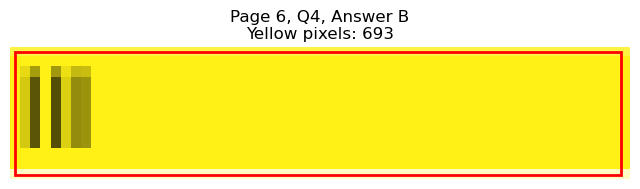

Page 6, Q4 - C: Detected box: x0=70.8, y0=362.2, x1=79.5, y1=374.3
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 111
Page 6, Q4, C: Yellow percentage: 0.0%


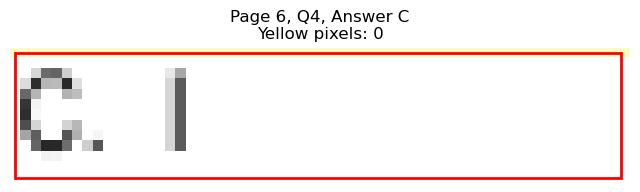

Page 6, Q4 - D: Detected box: x0=336.7, y0=338.1, x1=347.2, y1=350.2
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 44
Page 6, Q4, D: Yellow percentage: 0.0%


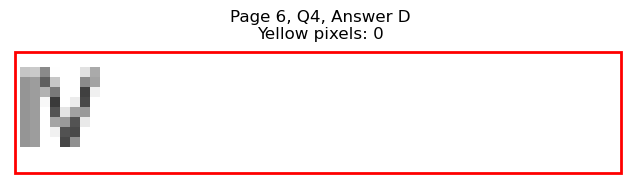

Page 6, Q4 - E: Detected box: x0=322.5, y0=350.2, x1=330.7, y1=362.3
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 58
Page 6, Q4, E: Yellow percentage: 0.0%


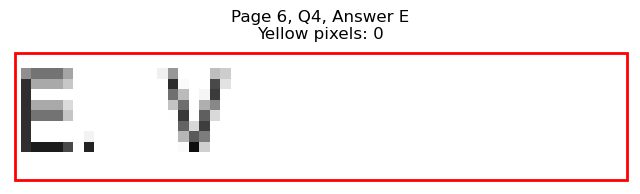


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=85.0, y0=434.4, x1=159.6, y1=446.5
Page 6, Q5, A: Yellow pixels: 0
Page 6, Q5, A: Total non-white pixels: 361
Page 6, Q5, A: Yellow percentage: 0.0%


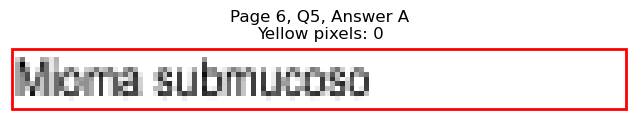

Page 6, Q5 - B: Detected box: x0=85.0, y0=446.6, x1=136.7, y1=458.7
Page 6, Q5, B: Yellow pixels: 1118
Page 6, Q5, B: Total non-white pixels: 1339
Page 6, Q5, B: Yellow percentage: 83.5%


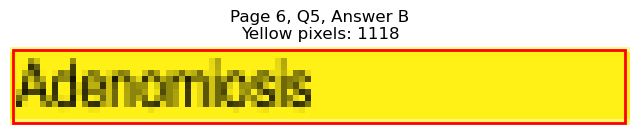

Page 6, Q5 - C: Detected box: x0=85.0, y0=458.6, x1=143.4, y1=470.7
Page 6, Q5, C: Yellow pixels: 110
Page 6, Q5, C: Total non-white pixels: 402
Page 6, Q5, C: Yellow percentage: 27.4%


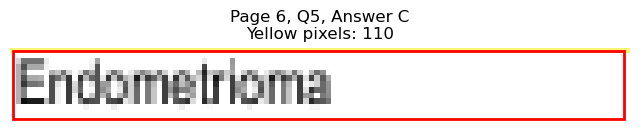

Page 6, Q5 - D: Detected box: x0=336.7, y0=434.4, x1=405.6, y1=446.5
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 361
Page 6, Q5, D: Yellow percentage: 0.0%


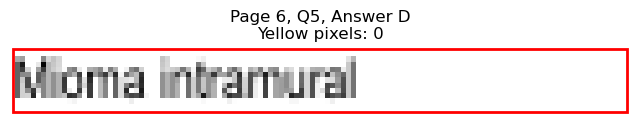

Page 6, Q5 - E: Detected box: x0=336.7, y0=446.6, x1=424.3, y1=458.7
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 436
Page 6, Q5, E: Yellow percentage: 0.0%


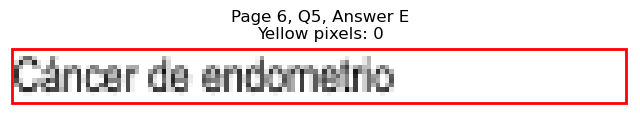


Page 6, Q5 - Selected Answer: B (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=85.0, y0=494.7, x1=239.1, y1=506.8
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 734
Page 6, Q6, A: Yellow percentage: 0.0%


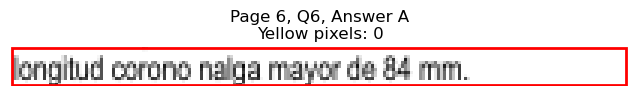

Page 6, Q6 - B: Detected box: x0=85.0, y0=506.8, x1=196.1, y1=518.9
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 541
Page 6, Q6, B: Yellow percentage: 0.0%


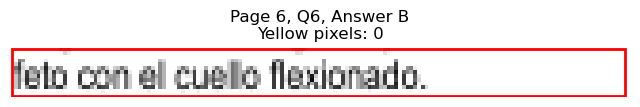

Page 6, Q6 - C: Detected box: x0=85.0, y0=518.8, x1=153.5, y1=530.9
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 523
Page 6, Q6, C: Yellow percentage: 0.0%


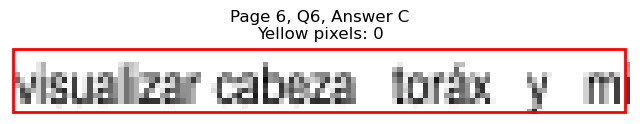

Page 6, Q6 - D: Detected box: x0=336.7, y0=494.7, x1=482.6, y1=506.8
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 708
Page 6, Q6, D: Yellow percentage: 0.0%


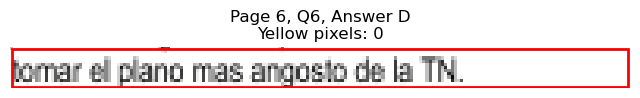

Page 6, Q6 - E: Detected box: x0=336.7, y0=506.8, x1=444.5, y1=518.9
Page 6, Q6, E: Yellow pixels: 1461
Page 6, Q6, E: Total non-white pixels: 2067
Page 6, Q6, E: Yellow percentage: 70.7%


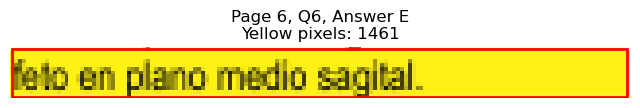


Page 6, Q6 - Selected Answer: E (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=70.8, y0=579.1, x1=79.0, y1=591.2
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 57
Page 6, Q7, A: Yellow percentage: 0.0%


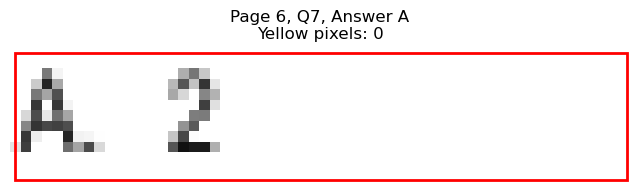

Page 6, Q7 - B: Detected box: x0=70.8, y0=591.2, x1=79.0, y1=603.3
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 69
Page 6, Q7, B: Yellow percentage: 0.0%


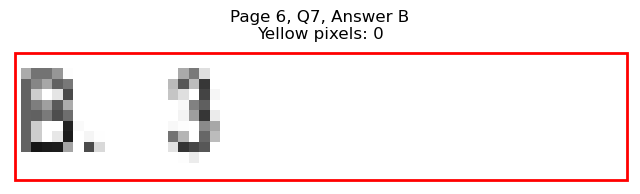

Page 6, Q7 - C: Detected box: x0=85.0, y0=603.2, x1=97.0, y1=615.3
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 49
Page 6, Q7, C: Yellow percentage: 0.0%


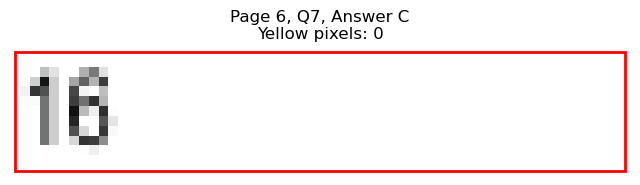

Page 6, Q7 - D: Detected box: x0=336.7, y0=579.1, x1=348.7, y1=591.2
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 40
Page 6, Q7, D: Yellow percentage: 0.0%


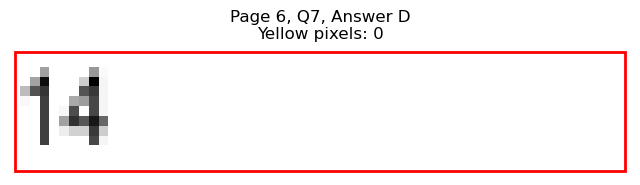

Page 6, Q7 - E: Detected box: x0=322.5, y0=591.2, x1=330.7, y1=603.3
Page 6, Q7, E: Yellow pixels: 669
Page 6, Q7, E: Total non-white pixels: 767
Page 6, Q7, E: Yellow percentage: 87.2%


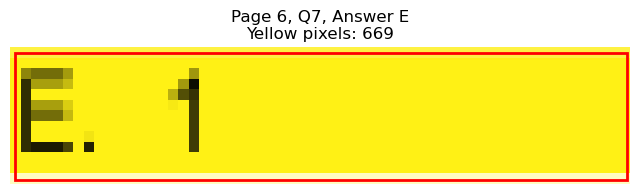


Page 6, Q7 - Selected Answer: E (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=85.0, y0=639.3, x1=132.9, y1=651.4
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 271
Page 6, Q8, A: Yellow percentage: 0.0%


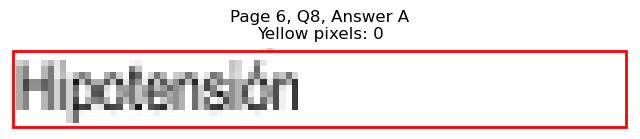

Page 6, Q8 - B: Detected box: x0=85.0, y0=651.4, x1=135.9, y1=663.5
Page 6, Q8, B: Yellow pixels: 1106
Page 6, Q8, B: Total non-white pixels: 1326
Page 6, Q8, B: Yellow percentage: 83.4%


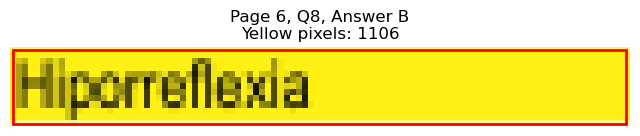

Page 6, Q8 - C: Detected box: x0=85.0, y0=663.4, x1=128.5, y1=675.5
Page 6, Q8, C: Yellow pixels: 95
Page 6, Q8, C: Total non-white pixels: 324
Page 6, Q8, C: Yellow percentage: 29.3%


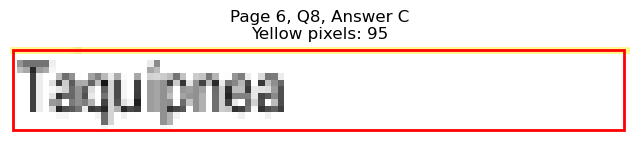

Page 6, Q8 - D: Detected box: x0=336.7, y0=639.3, x1=384.1, y1=651.4
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 237
Page 6, Q8, D: Yellow percentage: 0.0%


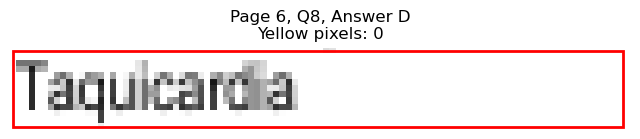

Page 6, Q8 - E: Detected box: x0=336.7, y0=651.4, x1=380.7, y1=663.5
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 228
Page 6, Q8, E: Yellow percentage: 0.0%


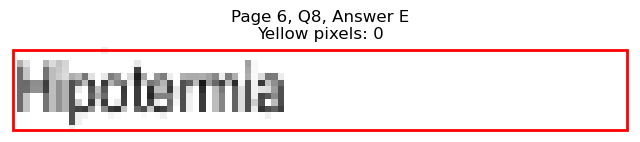


Page 6, Q8 - Selected Answer: B (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=85.0, y0=735.8, x1=209.0, y1=747.9
Page 6, Q9, A: Yellow pixels: 0
Page 6, Q9, A: Total non-white pixels: 807
Page 6, Q9, A: Yellow percentage: 0.0%


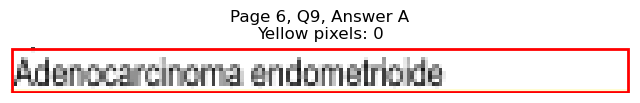

Page 6, Q9 - B: Detected box: x0=85.0, y0=747.8, x1=180.3, y1=759.9
Page 6, Q9, B: Yellow pixels: 1364
Page 6, Q9, B: Total non-white pixels: 1911
Page 6, Q9, B: Yellow percentage: 71.4%


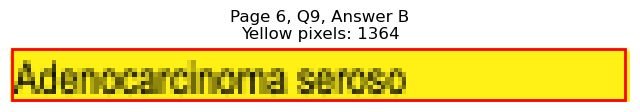

Page 6, Q9 - C: Detected box: x0=85.0, y0=759.8, x1=218.6, y1=771.9
Page 6, Q9, C: Yellow pixels: 185
Page 6, Q9, C: Total non-white pixels: 864
Page 6, Q9, C: Yellow percentage: 21.4%


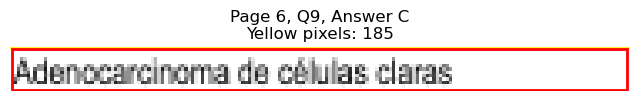

Page 6, Q9 - D: Detected box: x0=336.7, y0=735.8, x1=401.7, y1=747.9
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 318
Page 6, Q9, D: Yellow percentage: 0.0%


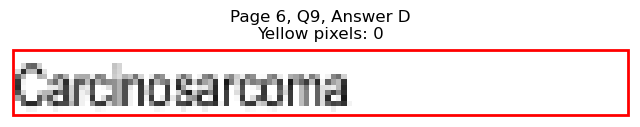

Page 6, Q9 - E: Detected box: x0=336.7, y0=747.8, x1=366.9, y1=759.9
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 171
Page 6, Q9, E: Yellow percentage: 0.0%


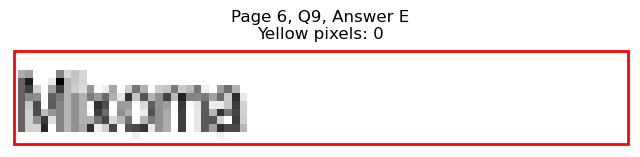


Page 6, Q9 - Selected Answer: B (based on yellow pixel count)





Page 7: Found 10 questions
Page 7, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=174.5, y1=109.2
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 470
Page 7, Q1, A: Yellow percentage: 0.0%


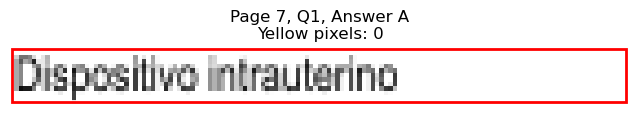

Page 7, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=214.7, y1=121.3
Page 7, Q1, B: Yellow pixels: 181
Page 7, Q1, B: Total non-white pixels: 850
Page 7, Q1, B: Yellow percentage: 21.3%


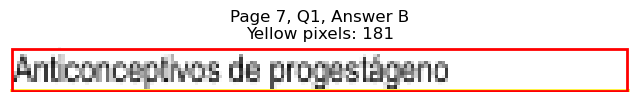

Page 7, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=222.4, y1=133.3
Page 7, Q1, C: Yellow pixels: 1707
Page 7, Q1, C: Total non-white pixels: 2457
Page 7, Q1, C: Yellow percentage: 69.5%


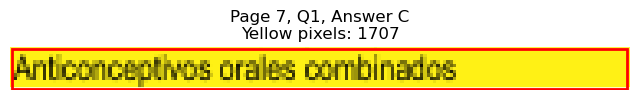

Page 7, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=409.9, y1=109.2
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 356
Page 7, Q1, D: Yellow percentage: 0.0%


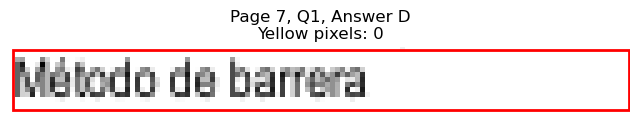

Page 7, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=419.0, y1=121.3
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 435
Page 7, Q1, E: Yellow percentage: 0.0%


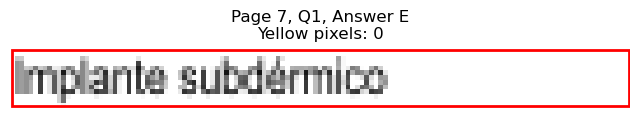


Page 7, Q1 - Selected Answer: C (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=85.0, y0=157.3, x1=130.9, y1=169.4
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 258
Page 7, Q2, A: Yellow percentage: 0.0%


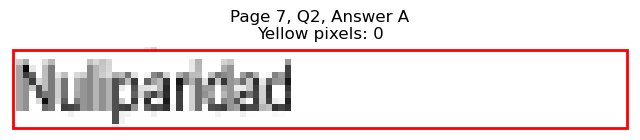

Page 7, Q2 - B: Detected box: x0=85.0, y0=169.4, x1=149.7, y1=181.5
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 343
Page 7, Q2, B: Yellow percentage: 0.0%


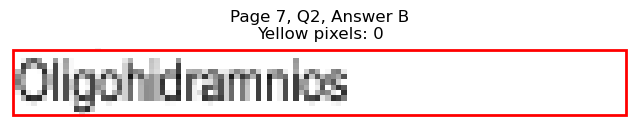

Page 7, Q2 - C: Detected box: x0=85.0, y0=181.4, x1=135.3, y1=193.5
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 258
Page 7, Q2, C: Yellow percentage: 0.0%


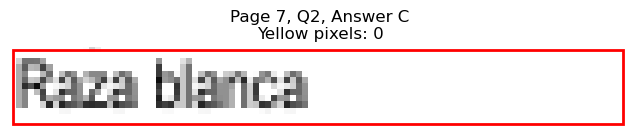

Page 7, Q2 - D: Detected box: x0=336.7, y0=157.3, x1=417.6, y1=169.4
Page 7, Q2, D: Yellow pixels: 1391
Page 7, Q2, D: Total non-white pixels: 1716
Page 7, Q2, D: Yellow percentage: 81.1%


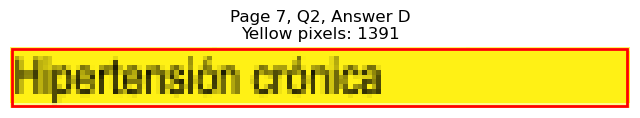

Page 7, Q2 - E: Detected box: x0=336.7, y0=169.4, x1=401.8, y1=181.5
Page 7, Q2, E: Yellow pixels: 116
Page 7, Q2, E: Total non-white pixels: 459
Page 7, Q2, E: Yellow percentage: 25.3%


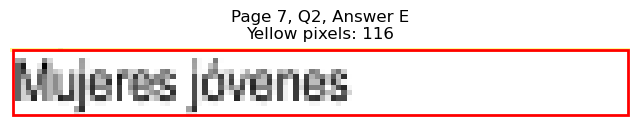


Page 7, Q2 - Selected Answer: D (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=85.0, y0=217.5, x1=117.6, y1=229.7
Page 7, Q3, A: Yellow pixels: 948
Page 7, Q3, A: Total non-white pixels: 1092
Page 7, Q3, A: Yellow percentage: 86.8%


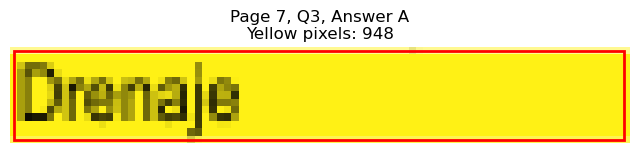

Page 7, Q3 - B: Detected box: x0=85.0, y0=229.7, x1=134.3, y1=241.8
Page 7, Q3, B: Yellow pixels: 101
Page 7, Q3, B: Total non-white pixels: 342
Page 7, Q3, B: Yellow percentage: 29.5%


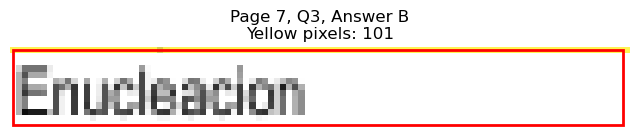

Page 7, Q3 - C: Detected box: x0=85.0, y0=241.7, x1=151.0, y1=253.8
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 356
Page 7, Q3, C: Yellow percentage: 0.0%


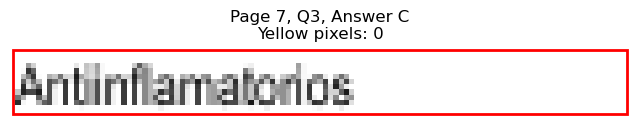

Page 7, Q3 - D: Detected box: x0=336.7, y0=217.5, x1=423.8, y1=229.7
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 492
Page 7, Q3, D: Yellow percentage: 0.0%


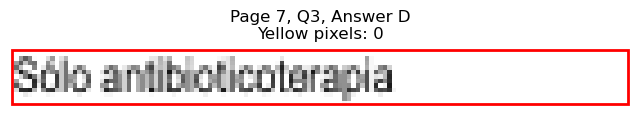

Page 7, Q3 - E: Detected box: x0=336.7, y0=229.7, x1=419.0, y1=241.8
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 407
Page 7, Q3, E: Yellow percentage: 0.0%


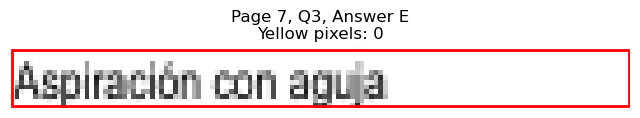


Page 7, Q3 - Selected Answer: A (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=85.0, y0=289.9, x1=164.4, y1=302.0
Page 7, Q4, A: Yellow pixels: 1269
Page 7, Q4, A: Total non-white pixels: 1703
Page 7, Q4, A: Yellow percentage: 74.5%


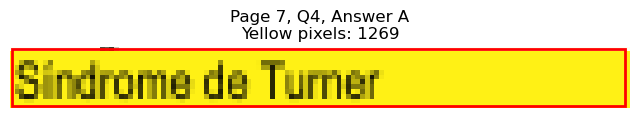

Page 7, Q4 - B: Detected box: x0=85.0, y0=301.9, x1=195.7, y1=314.0
Page 7, Q4, B: Yellow pixels: 162
Page 7, Q4, B: Total non-white pixels: 737
Page 7, Q4, B: Yellow percentage: 22.0%


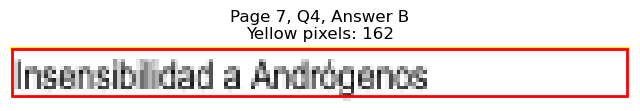

Page 7, Q4 - C: Detected box: x0=85.0, y0=313.9, x1=268.3, y1=326.0
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 919
Page 7, Q4, C: Yellow percentage: 0.0%


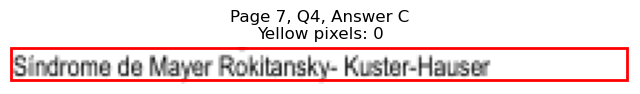

Page 7, Q4 - D: Detected box: x0=336.7, y0=289.9, x1=412.3, y1=302.0
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 396
Page 7, Q4, D: Yellow percentage: 0.0%


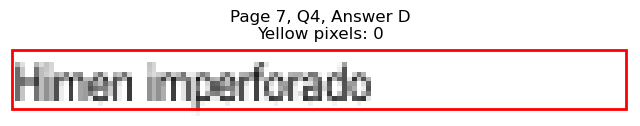

Page 7, Q4 - E: Detected box: x0=336.7, y0=301.9, x1=442.5, y1=314.0
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 543
Page 7, Q4, E: Yellow percentage: 0.0%


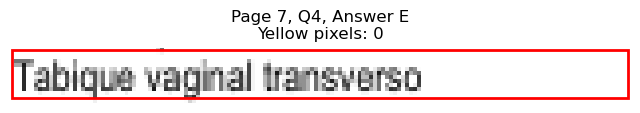


Page 7, Q4 - Selected Answer: A (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=94.6, y1=386.3
Page 7, Q5, A: Yellow pixels: 693
Page 7, Q5, A: Total non-white pixels: 793
Page 7, Q5, A: Yellow percentage: 87.4%


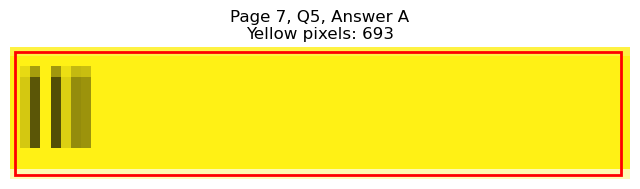

Page 7, Q5 - B: Detected box: x0=70.8, y0=386.3, x1=79.0, y1=398.4
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 130
Page 7, Q5, B: Yellow percentage: 0.0%


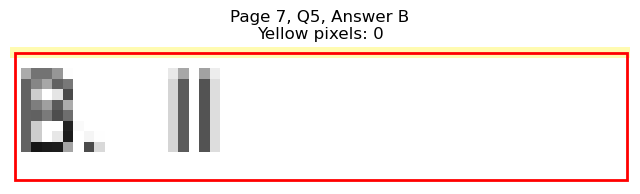

Page 7, Q5 - C: Detected box: x0=70.8, y0=398.3, x1=79.5, y1=410.4
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 51
Page 7, Q5, C: Yellow percentage: 0.0%


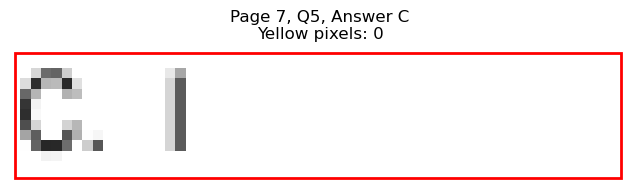

Page 7, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=345.8, y1=386.3
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 36
Page 7, Q5, D: Yellow percentage: 0.0%


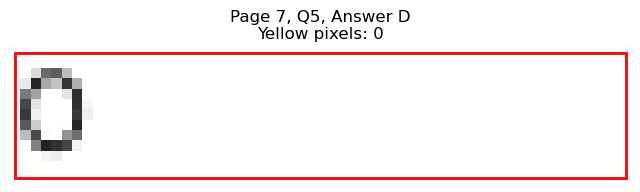

Page 7, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=347.2, y1=398.4
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 44
Page 7, Q5, E: Yellow percentage: 0.0%


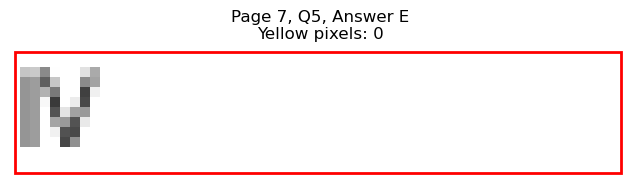


Page 7, Q5 - Selected Answer: A (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=85.0, y0=434.4, x1=126.1, y1=446.5
Page 7, Q6, A: Yellow pixels: 1043
Page 7, Q6, A: Total non-white pixels: 1209
Page 7, Q6, A: Yellow percentage: 86.3%


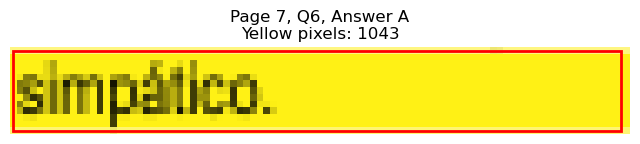

Page 7, Q6 - B: Detected box: x0=85.0, y0=446.6, x1=143.4, y1=458.7
Page 7, Q6, B: Yellow pixels: 110
Page 7, Q6, B: Total non-white pixels: 408
Page 7, Q6, B: Yellow percentage: 27.0%


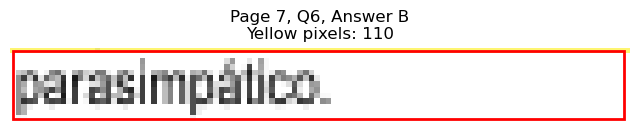

Page 7, Q6 - C: Detected box: x0=85.0, y0=458.6, x1=124.2, y1=470.7
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 194
Page 7, Q6, C: Yellow percentage: 0.0%


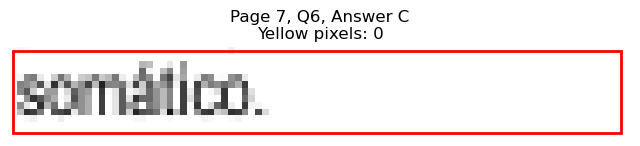

Page 7, Q6 - D: Detected box: x0=336.7, y0=434.4, x1=376.9, y1=446.5
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 209
Page 7, Q6, D: Yellow percentage: 0.0%


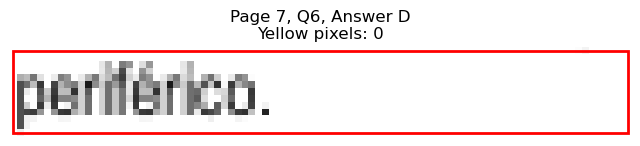

Page 7, Q6 - E: Detected box: x0=336.7, y0=446.6, x1=367.3, y1=458.7
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 139
Page 7, Q6, E: Yellow percentage: 0.0%


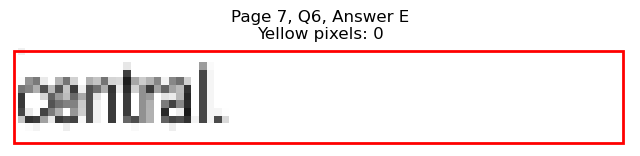


Page 7, Q6 - Selected Answer: A (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=85.0, y0=506.8, x1=140.5, y1=518.9
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 292
Page 7, Q7, A: Yellow percentage: 0.0%


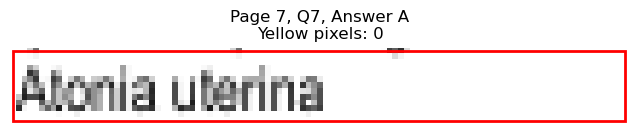

Page 7, Q7 - B: Detected box: x0=85.0, y0=518.8, x1=241.0, y1=530.9
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 800
Page 7, Q7, B: Yellow percentage: 0.0%


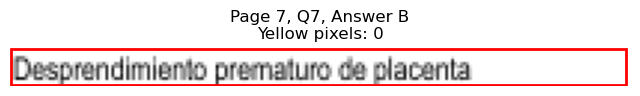

Page 7, Q7 - C: Detected box: x0=85.0, y0=530.9, x1=174.0, y1=543.0
Page 7, Q7, C: Yellow pixels: 0
Page 7, Q7, C: Total non-white pixels: 478
Page 7, Q7, C: Yellow percentage: 0.0%


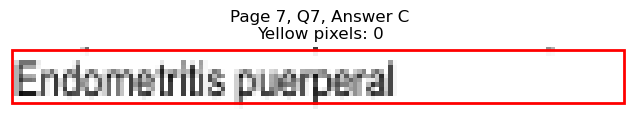

Page 7, Q7 - D: Detected box: x0=336.7, y0=506.8, x1=421.9, y1=518.9
Page 7, Q7, D: Yellow pixels: 1285
Page 7, Q7, D: Total non-white pixels: 1768
Page 7, Q7, D: Yellow percentage: 72.7%


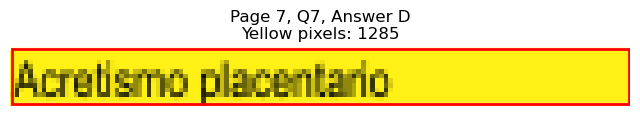

Page 7, Q7 - E: Detected box: x0=336.7, y0=518.8, x1=398.5, y1=530.9
Page 7, Q7, E: Yellow pixels: 112
Page 7, Q7, E: Total non-white pixels: 427
Page 7, Q7, E: Yellow percentage: 26.2%


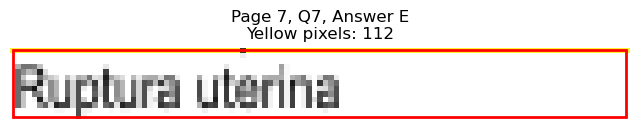


Page 7, Q7 - Selected Answer: D (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=85.0, y0=567.1, x1=265.5, y1=579.2
Page 7, Q8, A: Yellow pixels: 1523
Page 7, Q8, A: Total non-white pixels: 2484
Page 7, Q8, A: Yellow percentage: 61.3%


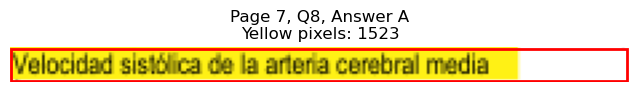

Page 7, Q8 - B: Detected box: x0=85.0, y0=579.1, x1=275.0, y1=591.2
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 1177
Page 7, Q8, B: Yellow percentage: 0.0%


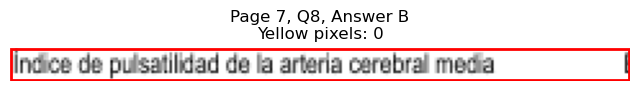

Page 7, Q8 - C: Detected box: x0=85.0, y0=591.2, x1=242.0, y1=603.3
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 842
Page 7, Q8, C: Yellow percentage: 0.0%


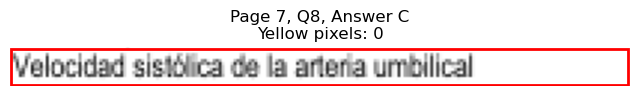

Page 7, Q8 - D: Detected box: x0=336.7, y0=567.1, x1=503.3, y1=579.2
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 893
Page 7, Q8, D: Yellow percentage: 0.0%


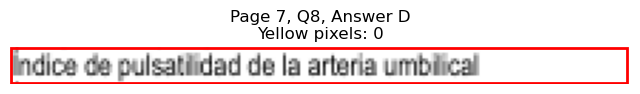

Page 7, Q8 - E: Detected box: x0=336.7, y0=579.1, x1=496.1, y1=591.2
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 837
Page 7, Q8, E: Yellow percentage: 0.0%


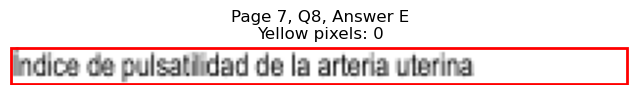


Page 7, Q8 - Selected Answer: A (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=70.8, y0=651.4, x1=79.0, y1=663.5
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 66
Page 7, Q9, A: Yellow percentage: 0.0%


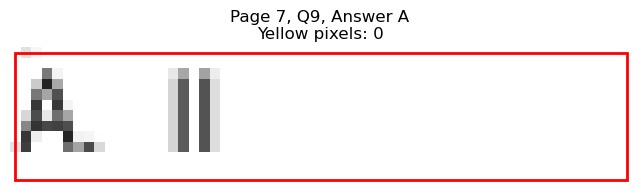

Page 7, Q9 - B: Detected box: x0=70.8, y0=663.4, x1=79.0, y1=675.5
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 55
Page 7, Q9, B: Yellow percentage: 0.0%


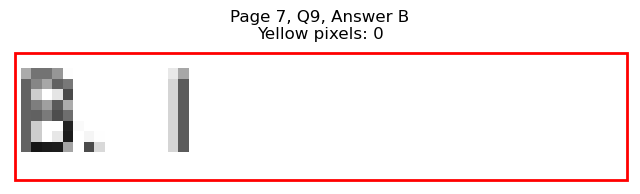

Page 7, Q9 - C: Detected box: x0=70.8, y0=675.4, x1=79.5, y1=687.5
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 63
Page 7, Q9, C: Yellow percentage: 0.0%


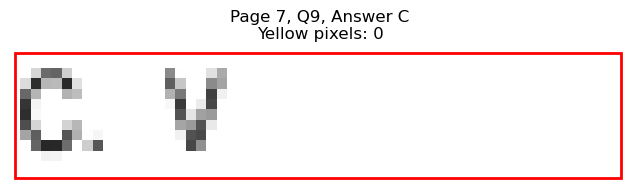

Page 7, Q9 - D: Detected box: x0=336.7, y0=651.4, x1=347.2, y1=663.5
Page 7, Q9, D: Yellow pixels: 62
Page 7, Q9, D: Total non-white pixels: 109
Page 7, Q9, D: Yellow percentage: 56.9%


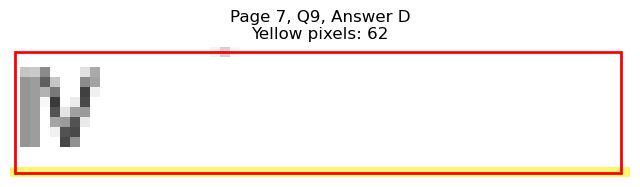

Page 7, Q9 - E: Detected box: x0=336.7, y0=663.4, x1=346.3, y1=675.5
Page 7, Q9, E: Yellow pixels: 754
Page 7, Q9, E: Total non-white pixels: 793
Page 7, Q9, E: Yellow percentage: 95.1%


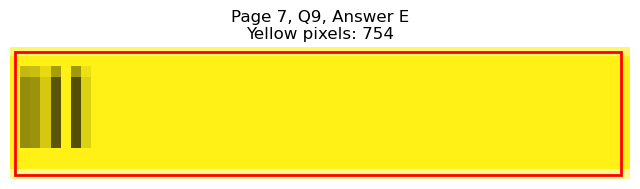


Page 7, Q9 - Selected Answer: E (based on yellow pixel count)




Page 7, Q10 - A: Detected box: x0=85.0, y0=711.7, x1=157.7, y1=723.8
Page 7, Q10, A: Yellow pixels: 0
Page 7, Q10, A: Total non-white pixels: 505
Page 7, Q10, A: Yellow percentage: 0.0%


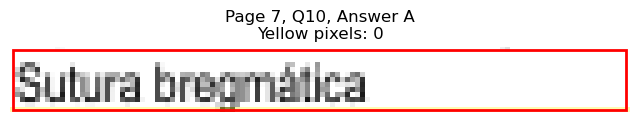

Page 7, Q10 - B: Detected box: x0=85.0, y0=723.7, x1=116.1, y1=735.8
Page 7, Q10, B: Yellow pixels: 843
Page 7, Q10, B: Total non-white pixels: 1079
Page 7, Q10, B: Yellow percentage: 78.1%


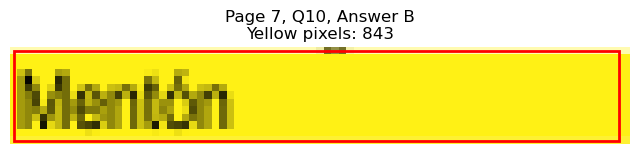

Page 7, Q10 - C: Detected box: x0=85.0, y0=735.8, x1=139.2, y1=747.9
Page 7, Q10, C: Yellow pixels: 106
Page 7, Q10, C: Total non-white pixels: 390
Page 7, Q10, C: Yellow percentage: 27.2%


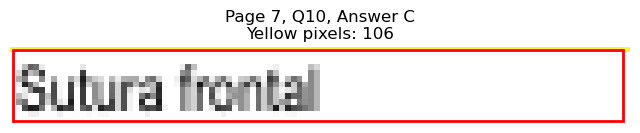

Page 7, Q10 - D: Detected box: x0=336.7, y0=711.7, x1=376.9, y1=723.8
Page 7, Q10, D: Yellow pixels: 0
Page 7, Q10, D: Total non-white pixels: 206
Page 7, Q10, D: Yellow percentage: 0.0%


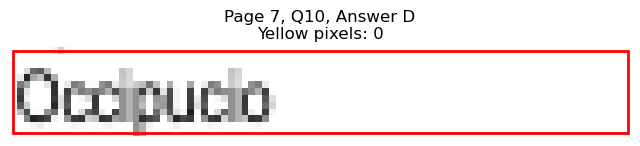

Page 7, Q10 - E: Detected box: x0=336.7, y0=723.7, x1=406.6, y1=735.8
Page 7, Q10, E: Yellow pixels: 0
Page 7, Q10, E: Total non-white pixels: 377
Page 7, Q10, E: Yellow percentage: 0.0%


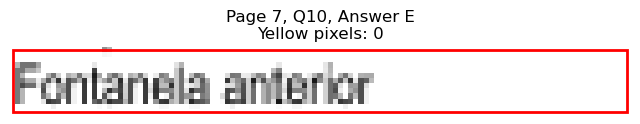


Page 7, Q10 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=107.9, y1=121.3
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 111
Page 8, Q1, A: Yellow percentage: 0.0%


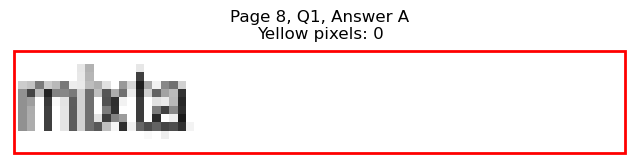

Page 8, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=132.4, y1=133.3
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 233
Page 8, Q1, B: Yellow percentage: 0.0%


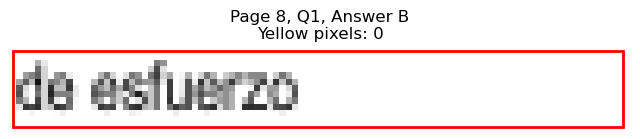

Page 8, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=154.3, y1=145.3
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 339
Page 8, Q1, C: Yellow percentage: 0.0%


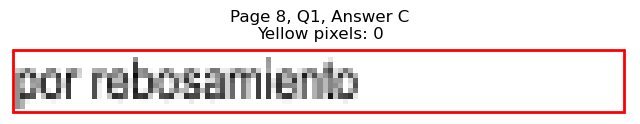

Page 8, Q1 - D: Detected box: x0=336.7, y0=109.2, x1=384.1, y1=121.3
Page 8, Q1, D: Yellow pixels: 994
Page 8, Q1, D: Total non-white pixels: 1287
Page 8, Q1, D: Yellow percentage: 77.2%


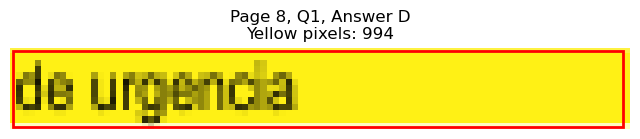

Page 8, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=376.9, y1=133.3
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 300
Page 8, Q1, E: Yellow percentage: 0.0%


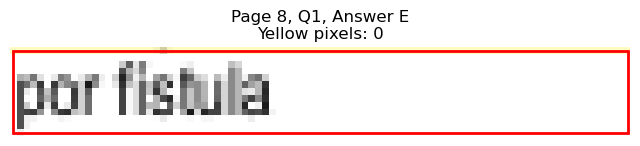


Page 8, Q1 - Selected Answer: D (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=130.9, y1=193.5
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 251
Page 8, Q2, A: Yellow percentage: 0.0%


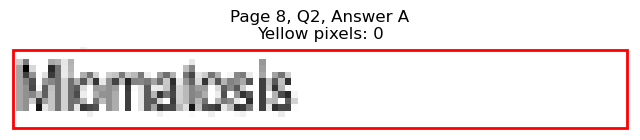

Page 8, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=115.6, y1=205.5
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 145
Page 8, Q2, B: Yellow percentage: 0.0%


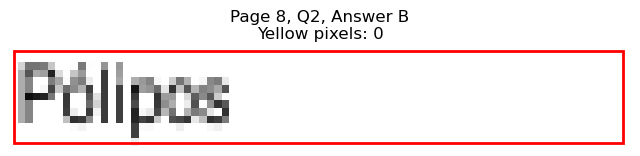

Page 8, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=158.2, y1=217.7
Page 8, Q2, C: Yellow pixels: 1294
Page 8, Q2, C: Total non-white pixels: 1625
Page 8, Q2, C: Yellow percentage: 79.6%


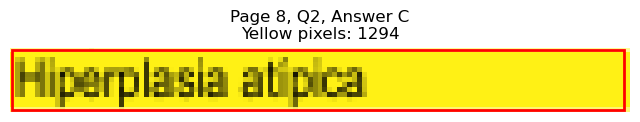

Page 8, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=383.1, y1=193.5
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 261
Page 8, Q2, D: Yellow percentage: 0.0%


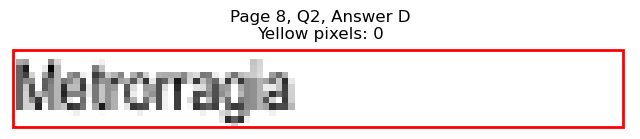

Page 8, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=388.4, y1=205.5
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 268
Page 8, Q2, E: Yellow percentage: 0.0%


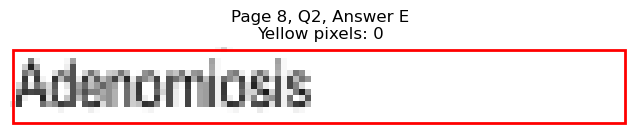


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=168.7, y1=265.8
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 470
Page 8, Q3, A: Yellow percentage: 0.0%


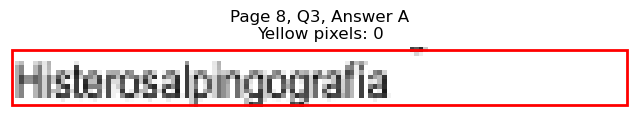

Page 8, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=177.4, y1=277.9
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 522
Page 8, Q3, B: Yellow percentage: 0.0%


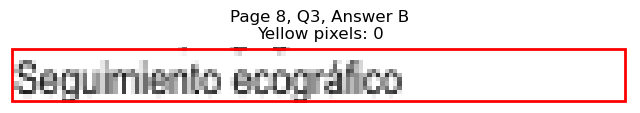

Page 8, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=167.8, y1=289.9
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 432
Page 8, Q3, C: Yellow percentage: 0.0%


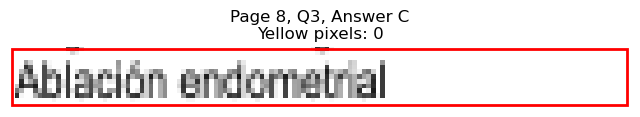

Page 8, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=407.0, y1=265.8
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 377
Page 8, Q3, D: Yellow percentage: 0.0%


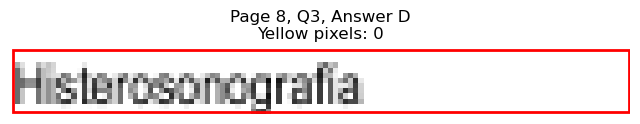

Page 8, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=424.8, y1=277.9
Page 8, Q3, E: Yellow pixels: 1302
Page 8, Q3, E: Total non-white pixels: 1807
Page 8, Q3, E: Yellow percentage: 72.1%


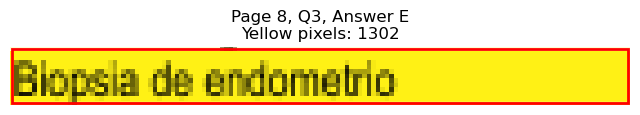


Page 8, Q3 - Selected Answer: E (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=70.8, y0=326.1, x1=79.0, y1=338.2
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 48
Page 8, Q4, A: Yellow percentage: 0.0%


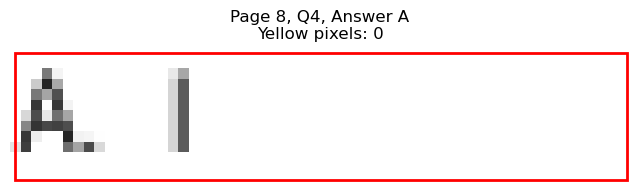

Page 8, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=94.6, y1=350.2
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 48
Page 8, Q4, B: Yellow percentage: 0.0%


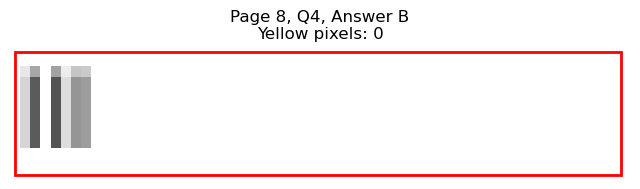

Page 8, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=95.6, y1=362.3
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 42
Page 8, Q4, C: Yellow percentage: 0.0%


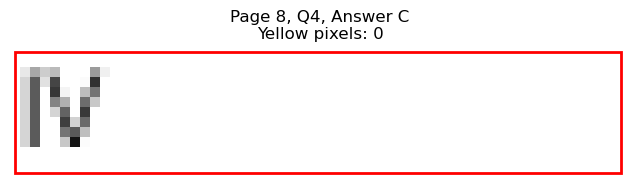

Page 8, Q4 - D: Detected box: x0=336.7, y0=326.1, x1=347.2, y1=338.2
Page 8, Q4, D: Yellow pixels: 62
Page 8, Q4, D: Total non-white pixels: 106
Page 8, Q4, D: Yellow percentage: 58.5%


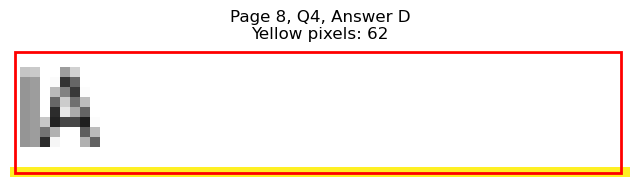

Page 8, Q4 - E: Detected box: x0=322.5, y0=338.1, x1=330.7, y1=350.2
Page 8, Q4, E: Yellow pixels: 649
Page 8, Q4, E: Total non-white pixels: 767
Page 8, Q4, E: Yellow percentage: 84.6%


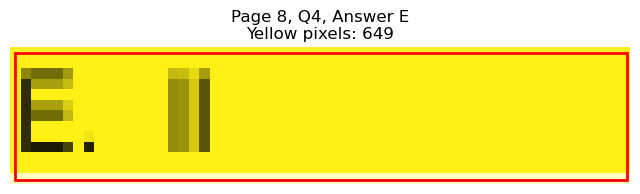


Page 8, Q4 - Selected Answer: E (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=85.0, y0=398.3, x1=97.0, y1=410.4
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 62
Page 8, Q5, A: Yellow percentage: 0.0%


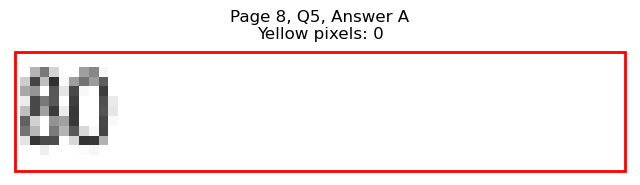

Page 8, Q5 - B: Detected box: x0=85.0, y0=410.4, x1=97.0, y1=422.5
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 50
Page 8, Q5, B: Yellow percentage: 0.0%


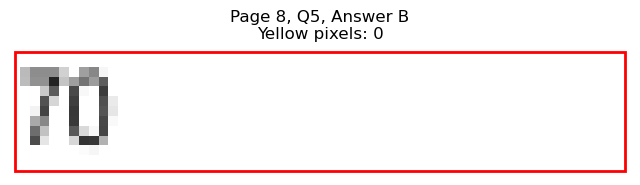

Page 8, Q5 - C: Detected box: x0=85.0, y0=422.4, x1=97.0, y1=434.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 61
Page 8, Q5, C: Yellow percentage: 0.0%


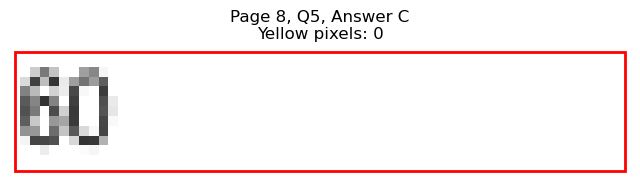

Page 8, Q5 - D: Detected box: x0=336.7, y0=398.3, x1=348.7, y1=410.4
Page 8, Q5, D: Yellow pixels: 774
Page 8, Q5, D: Total non-white pixels: 819
Page 8, Q5, D: Yellow percentage: 94.5%


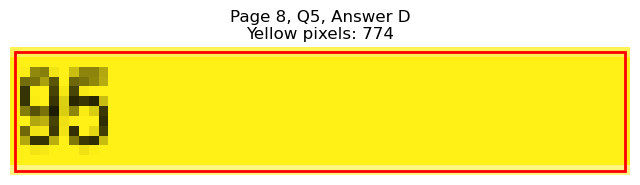

Page 8, Q5 - E: Detected box: x0=336.7, y0=410.4, x1=348.7, y1=422.5
Page 8, Q5, E: Yellow pixels: 63
Page 8, Q5, E: Total non-white pixels: 119
Page 8, Q5, E: Yellow percentage: 52.9%


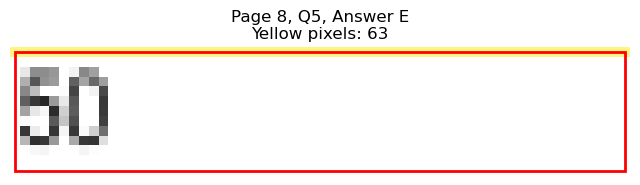


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=85.0, y0=458.6, x1=173.7, y1=470.7
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 452
Page 8, Q6, A: Yellow percentage: 0.0%


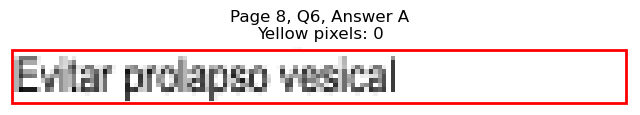

Page 8, Q6 - B: Detected box: x0=85.0, y0=470.7, x1=191.2, y1=482.8
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 543
Page 8, Q6, B: Yellow percentage: 0.0%


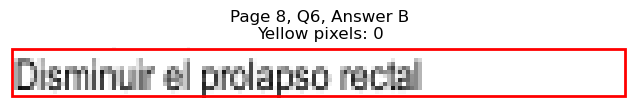

Page 8, Q6 - C: Detected box: x0=85.0, y0=482.7, x1=229.1, y1=494.8
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 754
Page 8, Q6, C: Yellow percentage: 0.0%


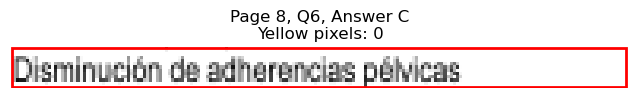

Page 8, Q6 - D: Detected box: x0=336.7, y0=458.6, x1=441.7, y1=470.7
Page 8, Q6, D: Yellow pixels: 1596
Page 8, Q6, D: Total non-white pixels: 2028
Page 8, Q6, D: Yellow percentage: 78.7%


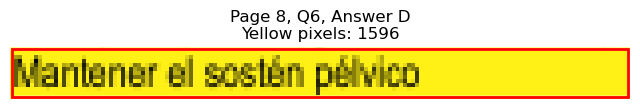

Page 8, Q6 - E: Detected box: x0=336.7, y0=470.7, x1=477.0, y1=482.8
Page 8, Q6, E: Yellow pixels: 190
Page 8, Q6, E: Total non-white pixels: 928
Page 8, Q6, E: Yellow percentage: 20.5%


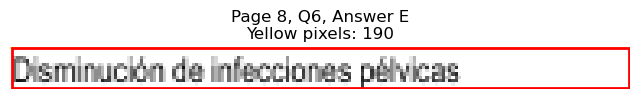


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=85.0, y0=518.8, x1=139.6, y1=530.9
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 297
Page 8, Q7, A: Yellow percentage: 0.0%


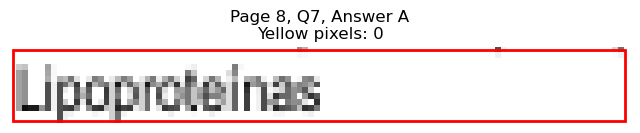

Page 8, Q7 - B: Detected box: x0=85.0, y0=530.9, x1=133.8, y1=543.0
Page 8, Q7, B: Yellow pixels: 100
Page 8, Q7, B: Total non-white pixels: 464
Page 8, Q7, B: Yellow percentage: 21.6%


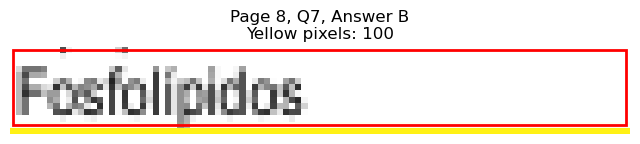

Page 8, Q7 - C: Detected box: x0=85.0, y0=542.9, x1=172.1, y1=555.0
Page 8, Q7, C: Yellow pixels: 1310
Page 8, Q7, C: Total non-white pixels: 1809
Page 8, Q7, C: Yellow percentage: 72.4%


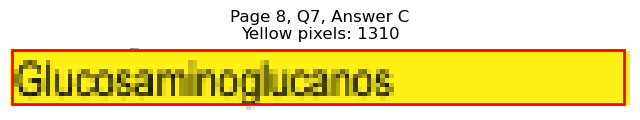

Page 8, Q7 - D: Detected box: x0=336.7, y0=518.8, x1=372.6, y1=530.9
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 191
Page 8, Q7, D: Yellow percentage: 0.0%


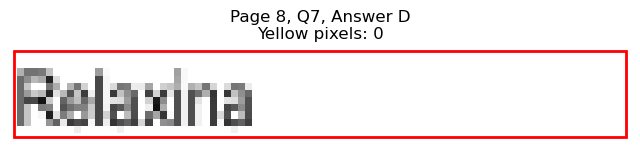

Page 8, Q7 - E: Detected box: x0=336.7, y0=530.9, x1=396.6, y1=543.0
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 309
Page 8, Q7, E: Yellow percentage: 0.0%


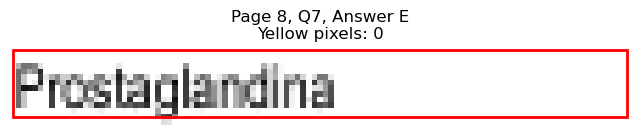


Page 8, Q7 - Selected Answer: C (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=85.0, y0=579.1, x1=183.1, y1=591.2
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 507
Page 8, Q8, A: Yellow percentage: 0.0%


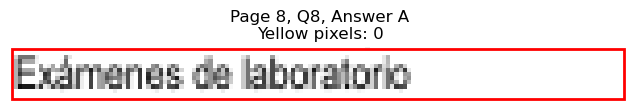

Page 8, Q8 - B: Detected box: x0=85.0, y0=591.2, x1=194.7, y1=603.3
Page 8, Q8, B: Yellow pixels: 1473
Page 8, Q8, B: Total non-white pixels: 2093
Page 8, Q8, B: Yellow percentage: 70.4%


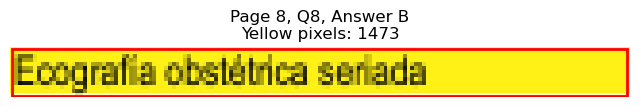

Page 8, Q8 - C: Detected box: x0=85.0, y0=603.2, x1=151.1, y1=615.3
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 474
Page 8, Q8, C: Yellow percentage: 0.0%


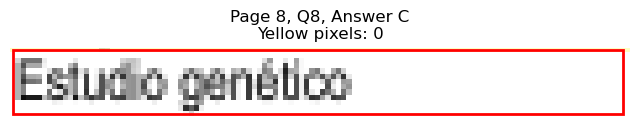

Page 8, Q8 - D: Detected box: x0=336.7, y0=579.1, x1=439.6, y1=591.2
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 529
Page 8, Q8, D: Yellow percentage: 0.0%


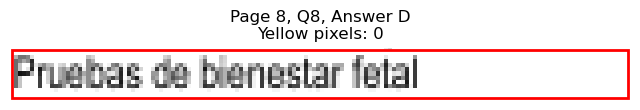

Page 8, Q8 - E: Detected box: x0=336.7, y0=591.2, x1=426.7, y1=603.3
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 462
Page 8, Q8, E: Yellow percentage: 0.0%


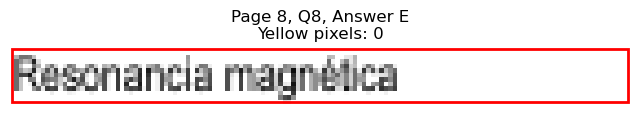


Page 8, Q8 - Selected Answer: B (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=85.0, y0=651.4, x1=304.3, y1=663.5
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 1046
Page 8, Q9, A: Yellow percentage: 0.0%


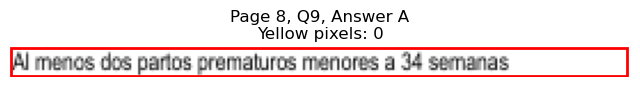

Page 8, Q9 - B: Detected box: x0=85.0, y0=663.4, x1=227.2, y1=675.5
Page 8, Q9, B: Yellow pixels: 194
Page 8, Q9, B: Total non-white pixels: 894
Page 8, Q9, B: Yellow percentage: 21.7%


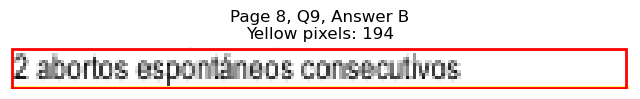

Page 8, Q9 - C: Detected box: x0=85.0, y0=675.4, x1=331.0, y1=687.5
Page 8, Q9, C: Yellow pixels: 2902
Page 8, Q9, C: Total non-white pixels: 3874
Page 8, Q9, C: Yellow percentage: 74.9%


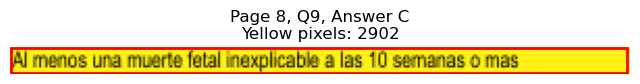

Page 8, Q9 - D: Detected box: x0=85.0, y0=687.5, x1=297.1, y1=699.7
Page 8, Q9, D: Yellow pixels: 264
Page 8, Q9, D: Total non-white pixels: 1295
Page 8, Q9, D: Yellow percentage: 20.4%


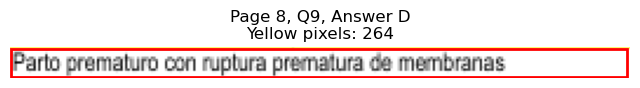

Page 8, Q9 - E: Detected box: x0=85.0, y0=699.5, x1=267.9, y1=711.7
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 936
Page 8, Q9, E: Yellow percentage: 0.0%


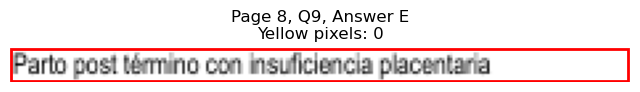


Page 8, Q9 - Selected Answer: C (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=85.0, y0=133.2, x1=141.0, y1=145.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 301
Page 9, Q1, A: Yellow percentage: 0.0%


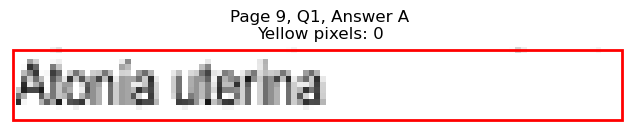

Page 9, Q1 - B: Detected box: x0=85.0, y0=145.3, x1=146.8, y1=157.4
Page 9, Q1, B: Yellow pixels: 113
Page 9, Q1, B: Total non-white pixels: 444
Page 9, Q1, B: Yellow percentage: 25.5%


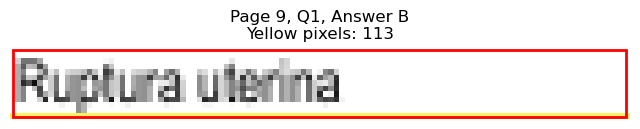

Page 9, Q1 - C: Detected box: x0=85.0, y0=157.3, x1=151.1, y1=169.4
Page 9, Q1, C: Yellow pixels: 1267
Page 9, Q1, C: Total non-white pixels: 1534
Page 9, Q1, C: Yellow percentage: 82.6%


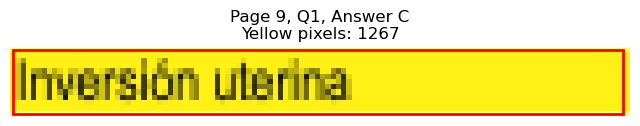

Page 9, Q1 - D: Detected box: x0=336.7, y0=133.2, x1=424.8, y1=145.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 464
Page 9, Q1, D: Yellow percentage: 0.0%


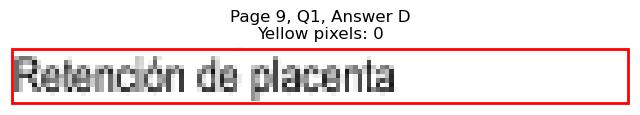

Page 9, Q1 - E: Detected box: x0=336.7, y0=145.3, x1=413.2, y1=157.4
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 384
Page 9, Q1, E: Yellow percentage: 0.0%


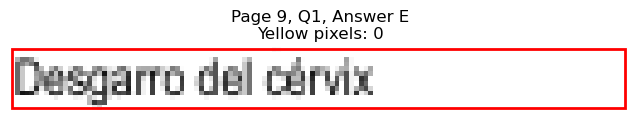


Page 9, Q1 - Selected Answer: C (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=192.8, y1=205.5
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 539
Page 9, Q2, A: Yellow percentage: 0.0%


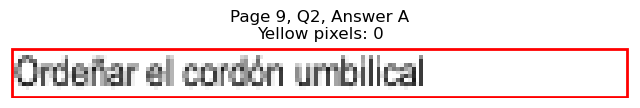

Page 9, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=233.0, y1=217.7
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 727
Page 9, Q2, B: Yellow percentage: 0.0%


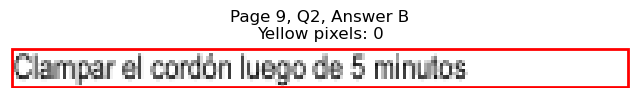

Page 9, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=183.7, y1=229.7
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 504
Page 9, Q2, C: Yellow percentage: 0.0%


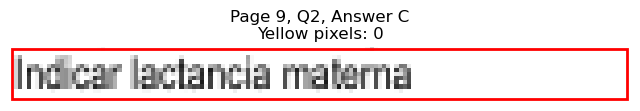

Page 9, Q2 - D: Detected box: x0=336.7, y0=193.4, x1=512.4, y1=205.5
Page 9, Q2, D: Yellow pixels: 1781
Page 9, Q2, D: Total non-white pixels: 2470
Page 9, Q2, D: Yellow percentage: 72.1%


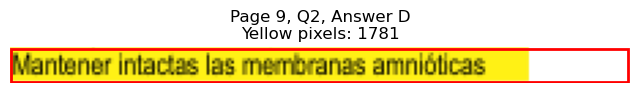

Page 9, Q2 - E: Detected box: x0=336.7, y0=205.5, x1=462.1, y1=217.7
Page 9, Q2, E: Yellow pixels: 177
Page 9, Q2, E: Total non-white pixels: 820
Page 9, Q2, E: Yellow percentage: 21.6%


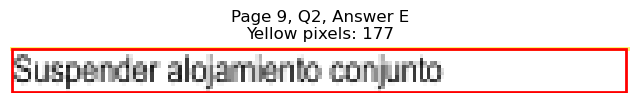


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=85.0, y0=265.8, x1=212.8, y1=277.9
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 668
Page 9, Q3, A: Yellow percentage: 0.0%


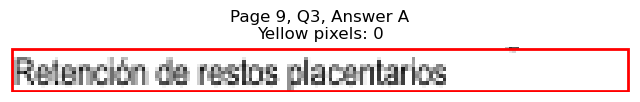

Page 9, Q3 - B: Detected box: x0=85.0, y0=145.3, x1=146.8, y1=157.4
Page 9, Q3, B: Yellow pixels: 113
Page 9, Q3, B: Total non-white pixels: 444
Page 9, Q3, B: Yellow percentage: 25.5%


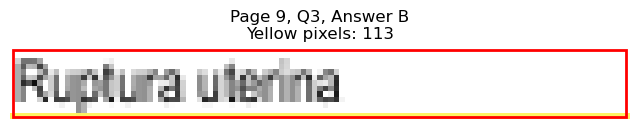

Page 9, Q3 - C: Detected box: x0=85.0, y0=289.9, x1=132.9, y1=302.0
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 240
Page 9, Q3, C: Yellow percentage: 0.0%


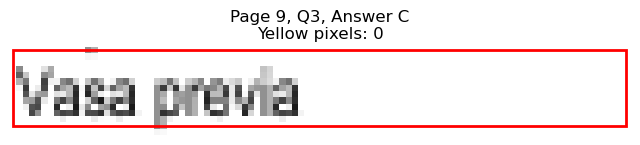

Page 9, Q3 - D: Detected box: x0=336.7, y0=265.8, x1=412.8, y1=277.9
Page 9, Q3, D: Yellow pixels: 1232
Page 9, Q3, D: Total non-white pixels: 1651
Page 9, Q3, D: Yellow percentage: 74.6%


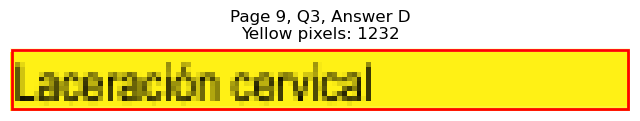

Page 9, Q3 - E: Detected box: x0=336.7, y0=277.8, x1=441.1, y1=289.9
Page 9, Q3, E: Yellow pixels: 156
Page 9, Q3, E: Total non-white pixels: 654
Page 9, Q3, E: Yellow percentage: 23.9%


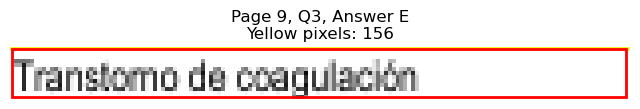


Page 9, Q3 - Selected Answer: D (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=85.0, y0=338.1, x1=188.9, y1=350.2
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 523
Page 9, Q4, A: Yellow percentage: 0.0%


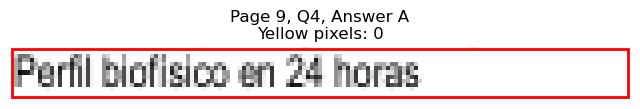

Page 9, Q4 - B: Detected box: x0=85.0, y0=350.2, x1=187.9, y1=362.3
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 518
Page 9, Q4, B: Yellow percentage: 0.0%


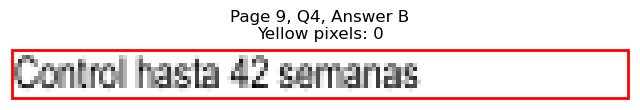

Page 9, Q4 - C: Detected box: x0=85.0, y0=362.2, x1=119.9, y1=374.3
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 184
Page 9, Q4, C: Yellow percentage: 0.0%


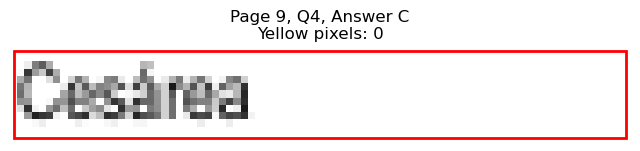

Page 9, Q4 - D: Detected box: x0=336.7, y0=338.1, x1=387.6, y1=350.2
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 255
Page 9, Q4, D: Yellow percentage: 0.0%


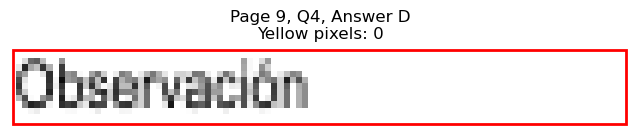

Page 9, Q4 - E: Detected box: x0=336.7, y0=350.2, x1=410.0, y1=362.3
Page 9, Q4, E: Yellow pixels: 1196
Page 9, Q4, E: Total non-white pixels: 1612
Page 9, Q4, E: Yellow percentage: 74.2%


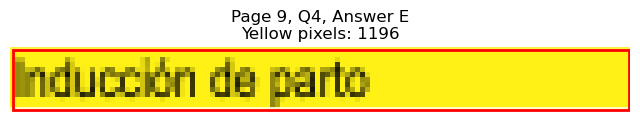


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=85.0, y0=398.3, x1=220.0, y1=410.4
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 670
Page 9, Q5, A: Yellow percentage: 0.0%


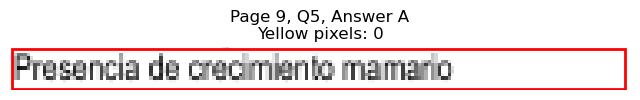

Page 9, Q5 - B: Detected box: x0=85.0, y0=410.4, x1=155.9, y1=422.5
Page 9, Q5, B: Yellow pixels: 1288
Page 9, Q5, B: Total non-white pixels: 1586
Page 9, Q5, B: Yellow percentage: 81.2%


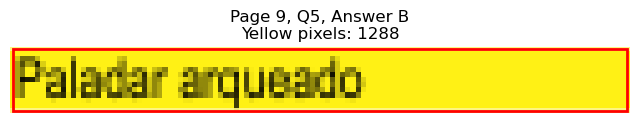

Page 9, Q5 - C: Detected box: x0=85.0, y0=422.4, x1=189.4, y1=434.5
Page 9, Q5, C: Yellow pixels: 156
Page 9, Q5, C: Total non-white pixels: 693
Page 9, Q5, C: Yellow percentage: 22.5%


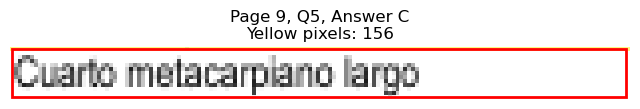

Page 9, Q5 - D: Detected box: x0=336.7, y0=398.3, x1=386.5, y1=410.4
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 256
Page 9, Q5, D: Yellow percentage: 0.0%


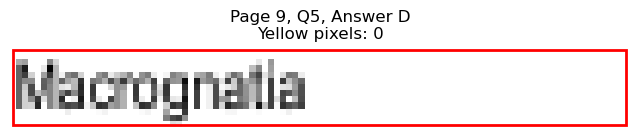

Page 9, Q5 - E: Detected box: x0=336.7, y0=410.4, x1=389.8, y1=422.5
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 246
Page 9, Q5, E: Yellow percentage: 0.0%


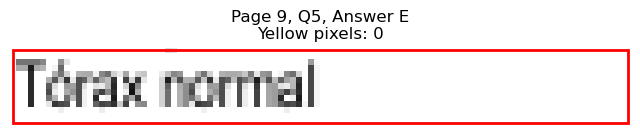


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=115.6, y1=482.8
Page 9, Q6, A: Yellow pixels: 898
Page 9, Q6, A: Total non-white pixels: 1066
Page 9, Q6, A: Yellow percentage: 84.2%


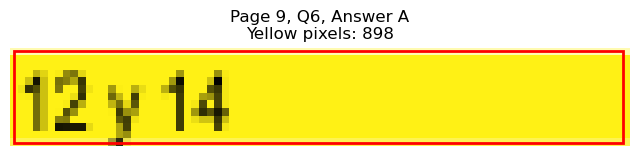

Page 9, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=115.6, y1=494.8
Page 9, Q6, B: Yellow pixels: 80
Page 9, Q6, B: Total non-white pixels: 209
Page 9, Q6, B: Yellow percentage: 38.3%


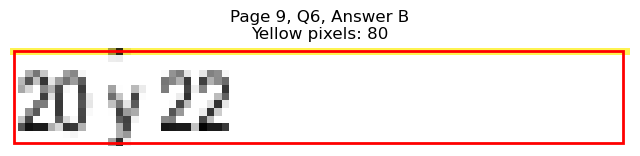

Page 9, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=115.6, y1=506.8
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 130
Page 9, Q6, C: Yellow percentage: 0.0%


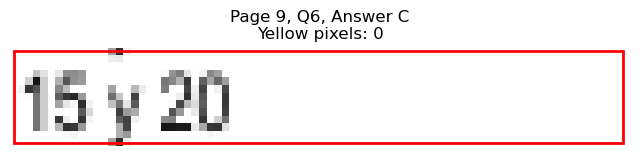

Page 9, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=367.3, y1=482.8
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 120
Page 9, Q6, D: Yellow percentage: 0.0%


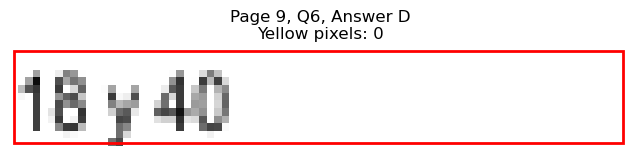

Page 9, Q6 - E: Detected box: x0=336.7, y0=482.7, x1=367.3, y1=494.8
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 118
Page 9, Q6, E: Yellow percentage: 0.0%


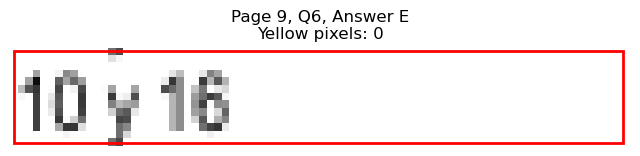


Page 9, Q6 - Selected Answer: A (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=85.0, y0=542.9, x1=270.3, y1=555.0
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 955
Page 9, Q7, A: Yellow percentage: 0.0%


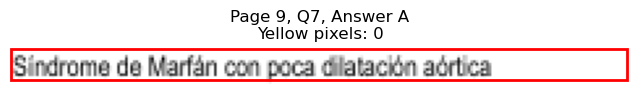

Page 9, Q7 - B: Detected box: x0=85.0, y0=554.9, x1=188.9, y1=567.0
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 571
Page 9, Q7, B: Yellow percentage: 0.0%


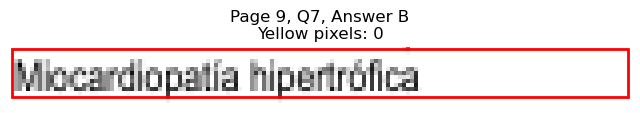

Page 9, Q7 - C: Detected box: x0=85.0, y0=567.1, x1=198.4, y1=579.2
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 611
Page 9, Q7, C: Yellow percentage: 0.0%


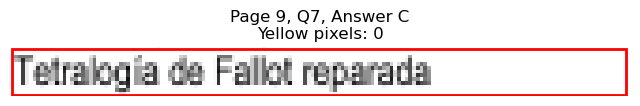

Page 9, Q7 - D: Detected box: x0=336.7, y0=542.9, x1=491.7, y1=555.0
Page 9, Q7, D: Yellow pixels: 190
Page 9, Q7, D: Total non-white pixels: 1124
Page 9, Q7, D: Yellow percentage: 16.9%


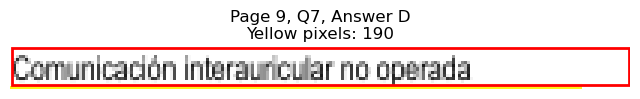

Page 9, Q7 - E: Detected box: x0=336.7, y0=554.9, x1=425.7, y1=567.0
Page 9, Q7, E: Yellow pixels: 1308
Page 9, Q7, E: Total non-white pixels: 1960
Page 9, Q7, E: Yellow percentage: 66.7%


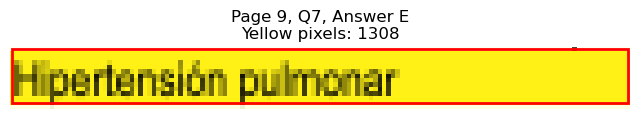


Page 9, Q7 - Selected Answer: E (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=85.0, y0=603.2, x1=128.5, y1=615.3
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 219
Page 9, Q8, A: Yellow percentage: 0.0%


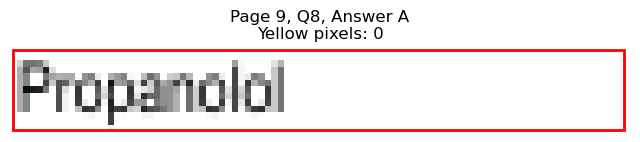

Page 9, Q8 - B: Detected box: x0=85.0, y0=615.2, x1=108.5, y1=627.3
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 112
Page 9, Q8, B: Yellow percentage: 0.0%


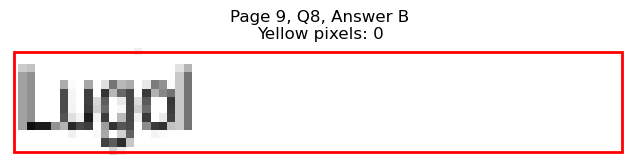

Page 9, Q8 - C: Detected box: x0=85.0, y0=627.3, x1=143.9, y1=639.4
Page 9, Q8, C: Yellow pixels: 1059
Page 9, Q8, C: Total non-white pixels: 1430
Page 9, Q8, C: Yellow percentage: 74.1%


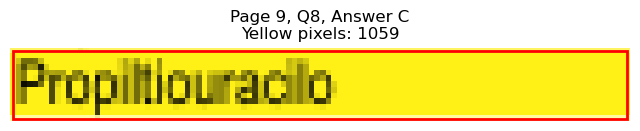

Page 9, Q8 - D: Detected box: x0=336.7, y0=603.2, x1=378.3, y1=615.3
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 237
Page 9, Q8, D: Yellow percentage: 0.0%


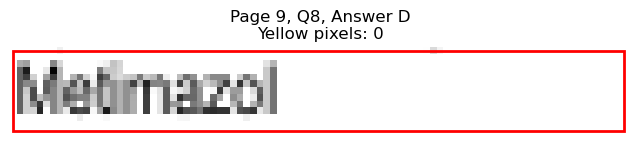

Page 9, Q8 - E: Detected box: x0=336.7, y0=615.2, x1=378.3, y1=627.3
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 233
Page 9, Q8, E: Yellow percentage: 0.0%


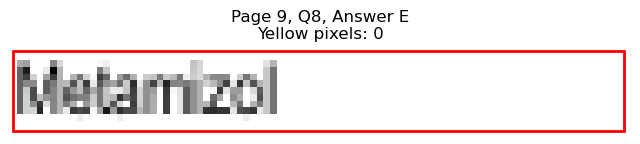


Page 9, Q8 - Selected Answer: C (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=85.0, y0=663.4, x1=124.2, y1=675.5
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 196
Page 9, Q9, A: Yellow percentage: 0.0%


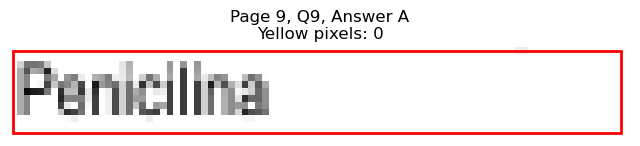

Page 9, Q9 - B: Detected box: x0=85.0, y0=675.4, x1=142.0, y1=687.5
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 309
Page 9, Q9, B: Yellow percentage: 0.0%


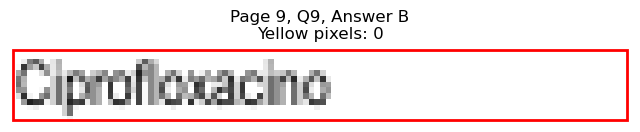

Page 9, Q9 - C: Detected box: x0=85.0, y0=687.5, x1=128.5, y1=699.7
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 231
Page 9, Q9, C: Yellow percentage: 0.0%


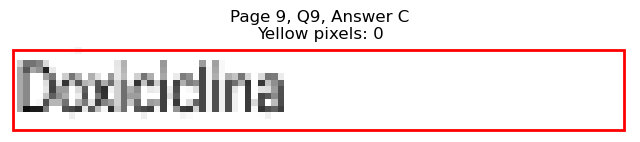

Page 9, Q9 - D: Detected box: x0=336.7, y0=663.4, x1=384.1, y1=675.5
Page 9, Q9, D: Yellow pixels: 1052
Page 9, Q9, D: Total non-white pixels: 1287
Page 9, Q9, D: Yellow percentage: 81.7%


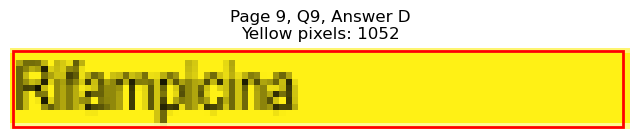

Page 9, Q9 - E: Detected box: x0=336.7, y0=675.4, x1=387.4, y1=687.5
Page 9, Q9, E: Yellow pixels: 102
Page 9, Q9, E: Total non-white pixels: 364
Page 9, Q9, E: Yellow percentage: 28.0%


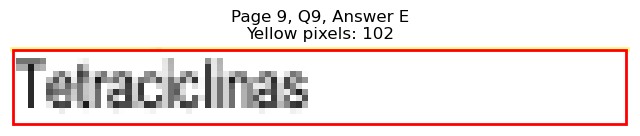


Page 9, Q9 - Selected Answer: D (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=85.0, y0=735.8, x1=128.5, y1=747.9
Page 9, Q10, A: Yellow pixels: 953
Page 9, Q10, A: Total non-white pixels: 1235
Page 9, Q10, A: Yellow percentage: 77.2%


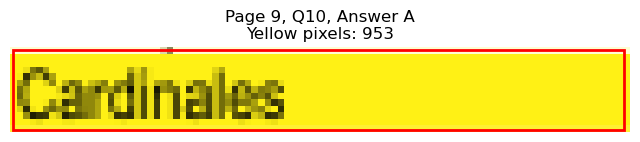

Page 9, Q10 - B: Detected box: x0=85.0, y0=747.8, x1=126.6, y1=759.9
Page 9, Q10, B: Yellow pixels: 93
Page 9, Q10, B: Total non-white pixels: 308
Page 9, Q10, B: Yellow percentage: 30.2%


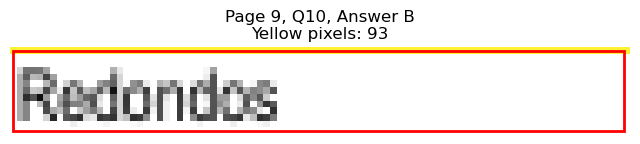

Page 9, Q10 - C: Detected box: x0=85.0, y0=759.8, x1=163.5, y1=771.9
Page 9, Q10, C: Yellow pixels: 0
Page 9, Q10, C: Total non-white pixels: 405
Page 9, Q10, C: Yellow percentage: 0.0%


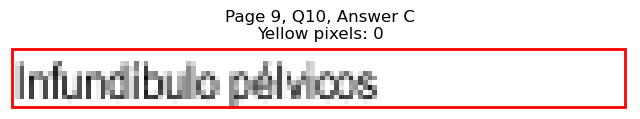

Page 9, Q10 - D: Detected box: x0=336.7, y0=735.8, x1=392.7, y1=747.9
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 283
Page 9, Q10, D: Yellow percentage: 0.0%


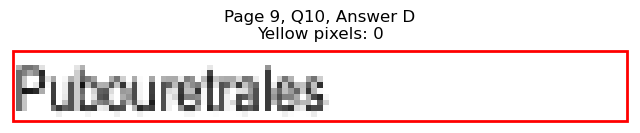

Page 9, Q10 - E: Detected box: x0=336.7, y0=747.8, x1=367.8, y1=759.9
Page 9, Q10, E: Yellow pixels: 0
Page 9, Q10, E: Total non-white pixels: 143
Page 9, Q10, E: Yellow percentage: 0.0%


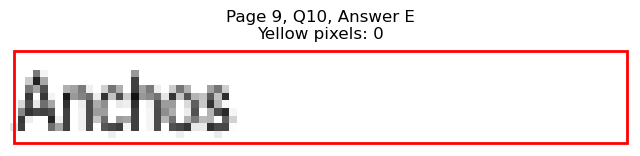


Page 9, Q10 - Selected Answer: A (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=70.8, y0=109.2, x1=79.0, y1=121.3
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 66
Page 10, Q1, A: Yellow percentage: 0.0%


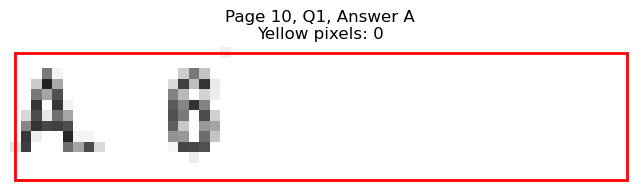

Page 10, Q1 - B: Detected box: x0=70.8, y0=121.2, x1=79.0, y1=133.3
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 65
Page 10, Q1, B: Yellow percentage: 0.0%


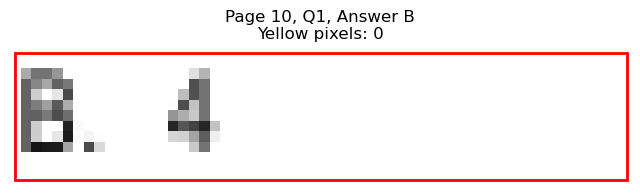

Page 10, Q1 - C: Detected box: x0=70.8, y0=133.2, x1=79.5, y1=145.3
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 57
Page 10, Q1, C: Yellow percentage: 0.0%


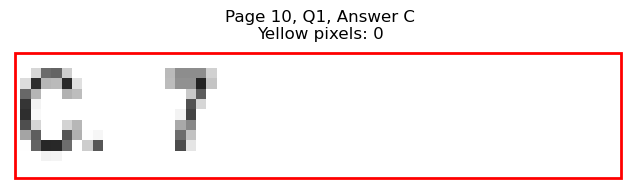

Page 10, Q1 - D: Detected box: x0=322.5, y0=109.2, x1=331.2, y1=121.3
Page 10, Q1, D: Yellow pixels: 670
Page 10, Q1, D: Total non-white pixels: 780
Page 10, Q1, D: Yellow percentage: 85.9%


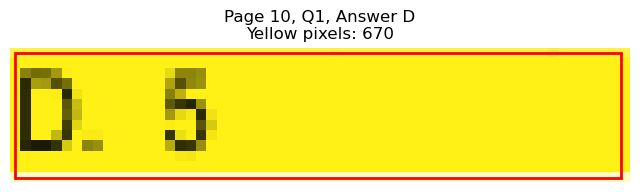

Page 10, Q1 - E: Detected box: x0=322.5, y0=121.2, x1=330.7, y1=133.3
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 119
Page 10, Q1, E: Yellow percentage: 0.0%


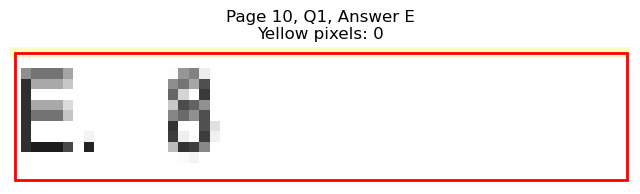


Page 10, Q1 - Selected Answer: D (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=184.1, y1=193.5
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 523
Page 10, Q2, A: Yellow percentage: 0.0%


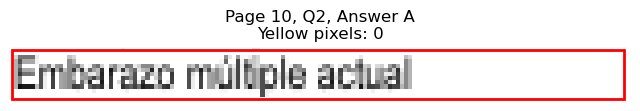

Page 10, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=137.7, y1=205.5
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 272
Page 10, Q2, B: Yellow percentage: 0.0%


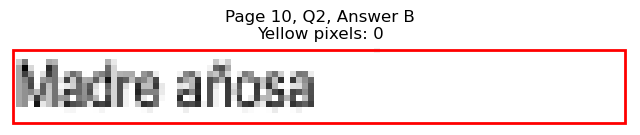

Page 10, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=269.8, y1=217.7
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 943
Page 10, Q2, C: Yellow percentage: 0.0%


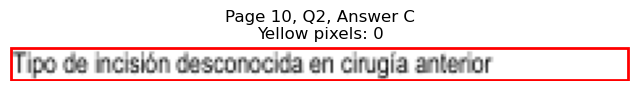

Page 10, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=124.2, y1=229.7
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 214
Page 10, Q2, D: Yellow percentage: 0.0%


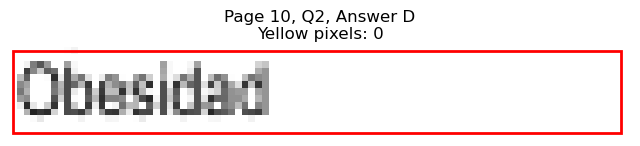

Page 10, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=285.5, y1=241.8
Page 10, Q2, E: Yellow pixels: 2241
Page 10, Q2, E: Total non-white pixels: 3276
Page 10, Q2, E: Yellow percentage: 68.4%


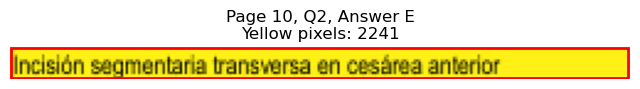


Page 10, Q2 - Selected Answer: E (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=85.0, y0=289.9, x1=100.4, y1=302.0
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 75
Page 10, Q3, A: Yellow percentage: 0.0%


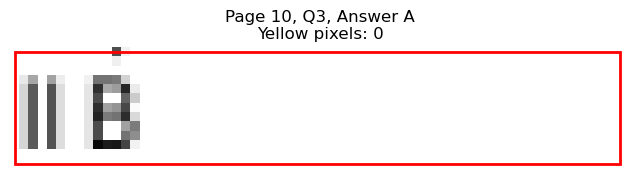

Page 10, Q3 - B: Detected box: x0=85.0, y0=301.9, x1=102.7, y1=314.0
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 78
Page 10, Q3, B: Yellow percentage: 0.0%


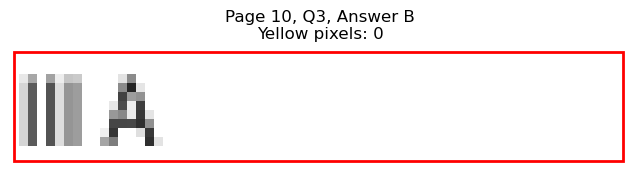

Page 10, Q3 - C: Detected box: x0=85.0, y0=313.9, x1=102.7, y1=326.0
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 81
Page 10, Q3, C: Yellow percentage: 0.0%


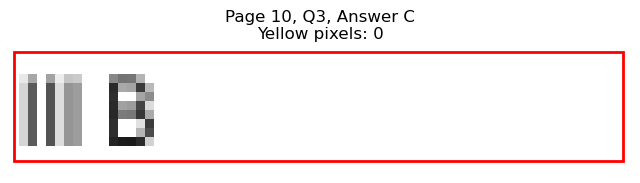

Page 10, Q3 - D: Detected box: x0=336.7, y0=289.9, x1=355.4, y1=302.0
Page 10, Q3, D: Yellow pixels: 70
Page 10, Q3, D: Total non-white pixels: 214
Page 10, Q3, D: Yellow percentage: 32.7%


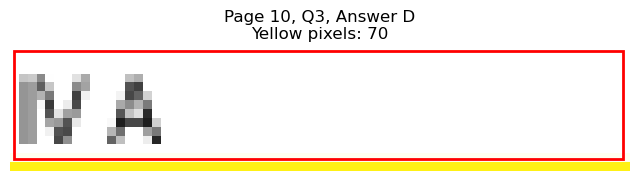

Page 10, Q3 - E: Detected box: x0=336.7, y0=301.9, x1=352.0, y1=314.0
Page 10, Q3, E: Yellow pixels: 751
Page 10, Q3, E: Total non-white pixels: 871
Page 10, Q3, E: Yellow percentage: 86.2%


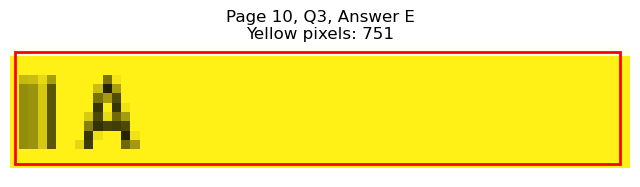


Page 10, Q3 - Selected Answer: E (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=85.0, y0=362.2, x1=94.6, y1=374.3
Page 10, Q4, A: Yellow pixels: 693
Page 10, Q4, A: Total non-white pixels: 793
Page 10, Q4, A: Yellow percentage: 87.4%


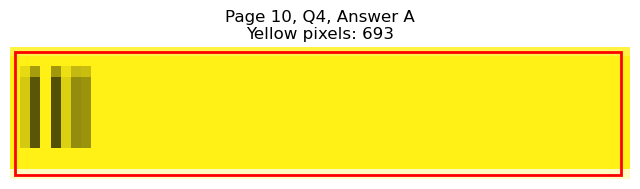

Page 10, Q4 - B: Detected box: x0=70.8, y0=374.2, x1=79.0, y1=386.3
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 114
Page 10, Q4, B: Yellow percentage: 0.0%


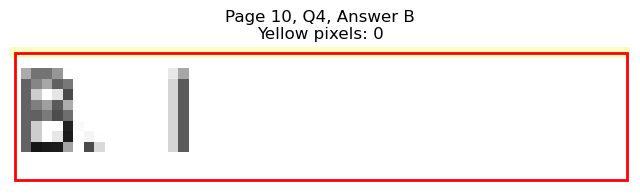

Page 10, Q4 - C: Detected box: x0=70.8, y0=386.3, x1=79.5, y1=398.4
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 67
Page 10, Q4, C: Yellow percentage: 0.0%


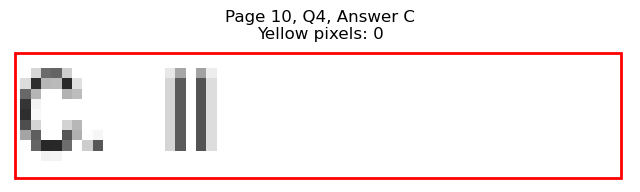

Page 10, Q4 - D: Detected box: x0=336.7, y0=362.2, x1=345.8, y1=374.3
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 36
Page 10, Q4, D: Yellow percentage: 0.0%


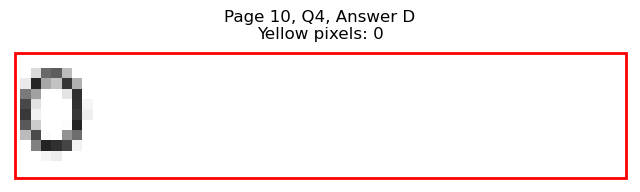

Page 10, Q4 - E: Detected box: x0=336.7, y0=374.2, x1=347.2, y1=386.3
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 44
Page 10, Q4, E: Yellow percentage: 0.0%


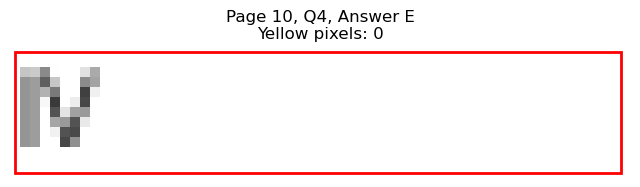


Page 10, Q4 - Selected Answer: A (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=85.0, y0=434.4, x1=181.2, y1=446.5
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 458
Page 10, Q5, A: Yellow percentage: 0.0%


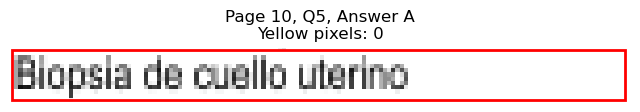

Page 10, Q5 - B: Detected box: x0=85.0, y0=446.6, x1=194.2, y1=458.7
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 565
Page 10, Q5, B: Yellow percentage: 0.0%


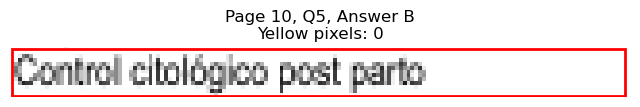

Page 10, Q5 - C: Detected box: x0=85.0, y0=458.6, x1=164.9, y1=470.7
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 440
Page 10, Q5, C: Yellow percentage: 0.0%


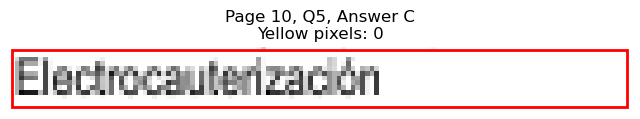

Page 10, Q5 - D: Detected box: x0=336.7, y0=434.4, x1=387.0, y1=446.5
Page 10, Q5, D: Yellow pixels: 1124
Page 10, Q5, D: Total non-white pixels: 1313
Page 10, Q5, D: Yellow percentage: 85.6%


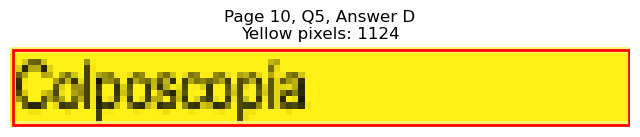

Page 10, Q5 - E: Detected box: x0=336.7, y0=446.6, x1=381.2, y1=458.7
Page 10, Q5, E: Yellow pixels: 96
Page 10, Q5, E: Total non-white pixels: 300
Page 10, Q5, E: Yellow percentage: 32.0%


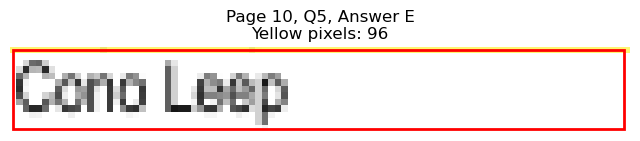


Page 10, Q5 - Selected Answer: D (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=85.0, y0=518.8, x1=172.1, y1=530.9
Page 10, Q6, A: Yellow pixels: 1299
Page 10, Q6, A: Total non-white pixels: 1807
Page 10, Q6, A: Yellow percentage: 71.9%


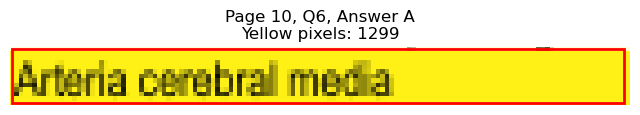

Page 10, Q6 - B: Detected box: x0=85.0, y0=530.9, x1=148.7, y1=543.0
Page 10, Q6, B: Yellow pixels: 115
Page 10, Q6, B: Total non-white pixels: 425
Page 10, Q6, B: Yellow percentage: 27.1%


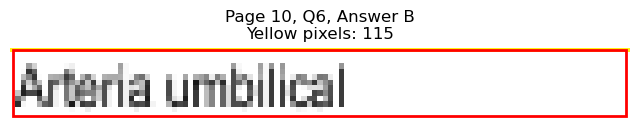

Page 10, Q6 - C: Detected box: x0=85.0, y0=542.9, x1=150.0, y1=555.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 342
Page 10, Q6, C: Yellow percentage: 0.0%


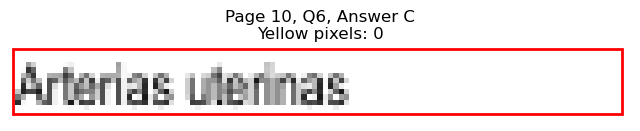

Page 10, Q6 - D: Detected box: x0=336.7, y0=518.8, x1=396.1, y1=530.9
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 287
Page 10, Q6, D: Yellow percentage: 0.0%


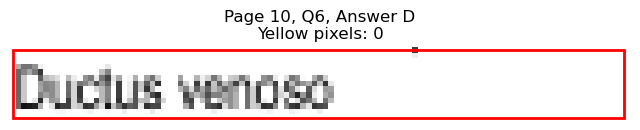

Page 10, Q6 - E: Detected box: x0=336.7, y0=530.9, x1=422.4, y1=543.0
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 437
Page 10, Q6, E: Yellow percentage: 0.0%


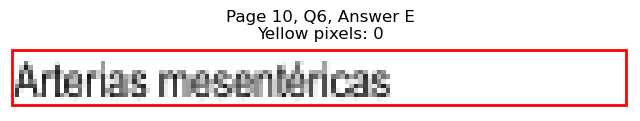


Page 10, Q6 - Selected Answer: A (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=85.0, y0=591.2, x1=201.3, y1=603.3
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 607
Page 10, Q7, A: Yellow percentage: 0.0%


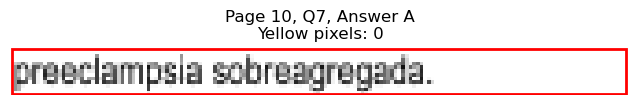

Page 10, Q7 - B: Detected box: x0=85.0, y0=603.2, x1=242.0, y1=615.3
Page 10, Q7, B: Yellow pixels: 190
Page 10, Q7, B: Total non-white pixels: 996
Page 10, Q7, B: Yellow percentage: 19.1%


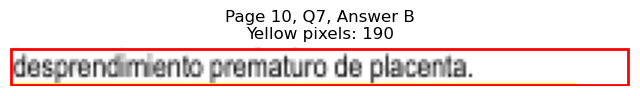

Page 10, Q7 - C: Detected box: x0=85.0, y0=615.2, x1=160.6, y1=627.3
Page 10, Q7, C: Yellow pixels: 1211
Page 10, Q7, C: Total non-white pixels: 1651
Page 10, Q7, C: Yellow percentage: 73.3%


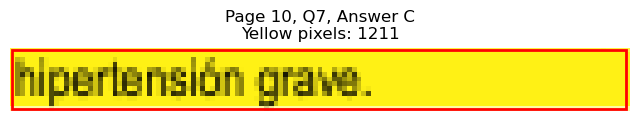

Page 10, Q7 - D: Detected box: x0=336.7, y0=591.2, x1=362.5, y1=603.3
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 110
Page 10, Q7, D: Yellow percentage: 0.0%


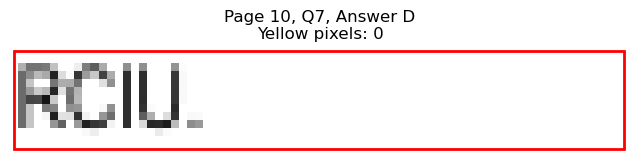

Page 10, Q7 - E: Detected box: x0=336.7, y0=603.2, x1=380.2, y1=615.3
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 216
Page 10, Q7, E: Yellow percentage: 0.0%


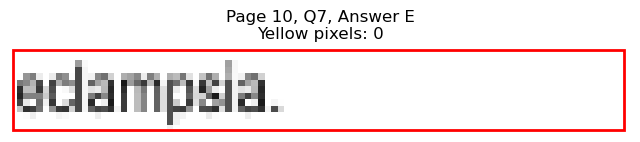


Page 10, Q7 - Selected Answer: C (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=85.0, y0=663.4, x1=192.3, y1=675.5
Page 10, Q8, A: Yellow pixels: 159
Page 10, Q8, A: Total non-white pixels: 674
Page 10, Q8, A: Yellow percentage: 23.6%


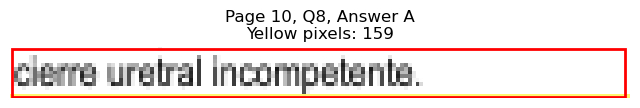

Page 10, Q8 - B: Detected box: x0=85.0, y0=675.4, x1=166.8, y1=687.5
Page 10, Q8, B: Yellow pixels: 1417
Page 10, Q8, B: Total non-white pixels: 1729
Page 10, Q8, B: Yellow percentage: 82.0%


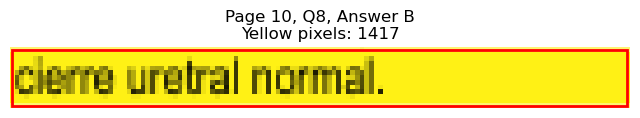

Page 10, Q8 - C: Detected box: x0=85.0, y0=687.5, x1=221.0, y1=699.7
Page 10, Q8, C: Yellow pixels: 187
Page 10, Q8, C: Total non-white pixels: 865
Page 10, Q8, C: Yellow percentage: 21.6%


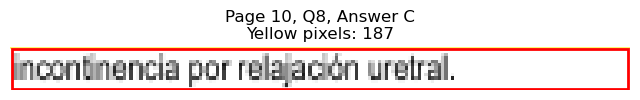

Page 10, Q8 - D: Detected box: x0=336.7, y0=663.4, x1=439.2, y1=675.5
Page 10, Q8, D: Yellow pixels: 0
Page 10, Q8, D: Total non-white pixels: 506
Page 10, Q8, D: Yellow percentage: 0.0%


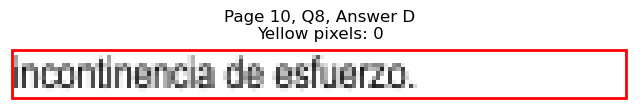

Page 10, Q8 - E: Detected box: x0=336.7, y0=675.4, x1=465.0, y1=687.5
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 612
Page 10, Q8, E: Yellow percentage: 0.0%


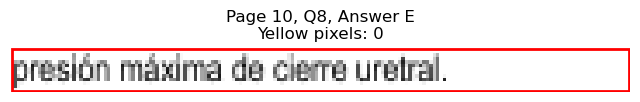


Page 10, Q8 - Selected Answer: B (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=85.0, y0=723.7, x1=147.6, y1=735.8
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 316
Page 10, Q9, A: Yellow percentage: 0.0%


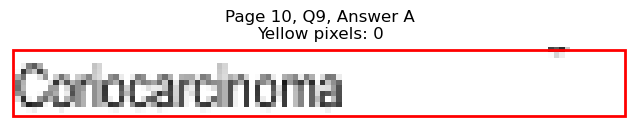

Page 10, Q9 - B: Detected box: x0=85.0, y0=735.8, x1=209.0, y1=747.9
Page 10, Q9, B: Yellow pixels: 1599
Page 10, Q9, B: Total non-white pixels: 2275
Page 10, Q9, B: Yellow percentage: 70.3%


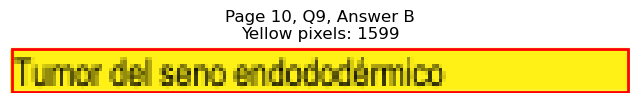

Page 10, Q9 - C: Detected box: x0=85.0, y0=747.8, x1=140.1, y1=759.9
Page 10, Q9, C: Yellow pixels: 107
Page 10, Q9, C: Total non-white pixels: 378
Page 10, Q9, C: Yellow percentage: 28.3%


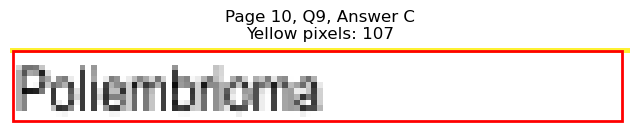

Page 10, Q9 - D: Detected box: x0=336.7, y0=723.7, x1=370.2, y1=735.8
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 150
Page 10, Q9, D: Yellow percentage: 0.0%


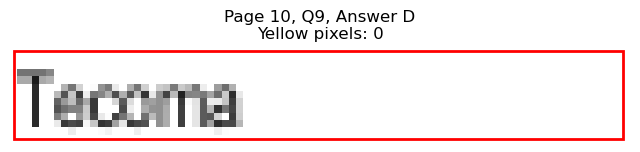

Page 10, Q9 - E: Detected box: x0=336.7, y0=735.8, x1=405.7, y1=747.9
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 346
Page 10, Q9, E: Yellow percentage: 0.0%


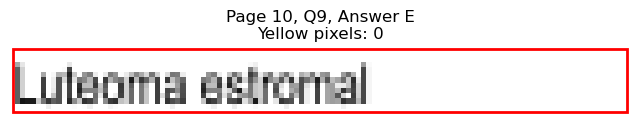


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 6 questions
Page 11, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=162.5, y1=121.3
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 408
Page 11, Q1, A: Yellow percentage: 0.0%


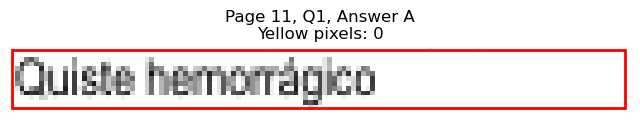

Page 11, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=182.2, y1=133.3
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 492
Page 11, Q1, B: Yellow percentage: 0.0%


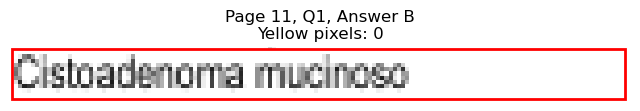

Page 11, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=122.8, y1=145.3
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 178
Page 11, Q1, C: Yellow percentage: 0.0%


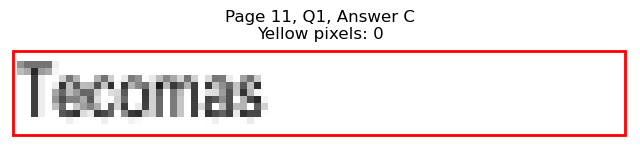

Page 11, Q1 - D: Detected box: x0=336.7, y0=109.2, x1=409.4, y1=121.3
Page 11, Q1, D: Yellow pixels: 124
Page 11, Q1, D: Total non-white pixels: 490
Page 11, Q1, D: Yellow percentage: 25.3%


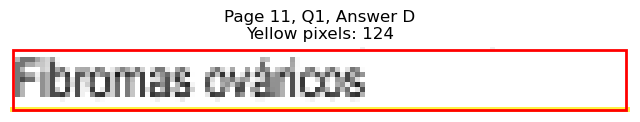

Page 11, Q1 - E: Detected box: x0=336.7, y0=121.2, x1=395.1, y1=133.3
Page 11, Q1, E: Yellow pixels: 1061
Page 11, Q1, E: Total non-white pixels: 1430
Page 11, Q1, E: Yellow percentage: 74.2%


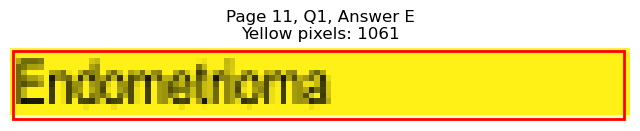


Page 11, Q1 - Selected Answer: E (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=250.6, y1=181.5
Page 11, Q2, A: Yellow pixels: 1753
Page 11, Q2, A: Total non-white pixels: 2483
Page 11, Q2, A: Yellow percentage: 70.6%


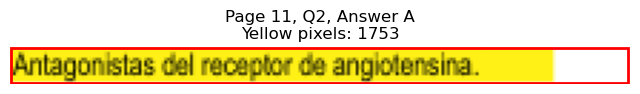

Page 11, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=164.1, y1=193.5
Page 11, Q2, B: Yellow pixels: 131
Page 11, Q2, B: Total non-white pixels: 553
Page 11, Q2, B: Yellow percentage: 23.7%


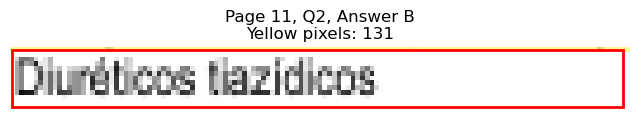

Page 11, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=234.3, y1=205.5
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 744
Page 11, Q2, C: Yellow percentage: 0.0%


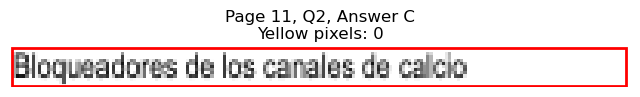

Page 11, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=422.4, y1=181.5
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 457
Page 11, Q2, D: Yellow percentage: 0.0%


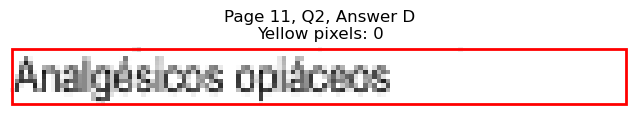

Page 11, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=460.7, y1=193.5
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 645
Page 11, Q2, E: Yellow percentage: 0.0%


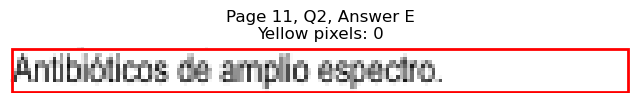


Page 11, Q2 - Selected Answer: A (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=310.3, y1=265.8
Page 11, Q3, A: Yellow pixels: 2432
Page 11, Q3, A: Total non-white pixels: 3601
Page 11, Q3, A: Yellow percentage: 67.5%


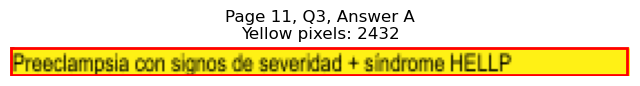

Page 11, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=270.1, y1=277.9
Page 11, Q3, B: Yellow pixels: 233
Page 11, Q3, B: Total non-white pixels: 1109
Page 11, Q3, B: Yellow percentage: 21.0%


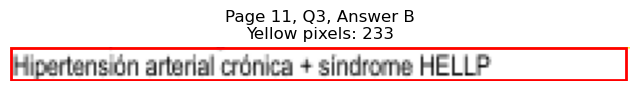

Page 11, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=206.3, y1=289.9
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 611
Page 11, Q3, C: Yellow percentage: 0.0%


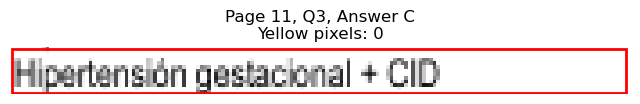

Page 11, Q3 - D: Detected box: x0=85.0, y0=289.9, x1=187.7, y1=302.0
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 495
Page 11, Q3, D: Yellow percentage: 0.0%


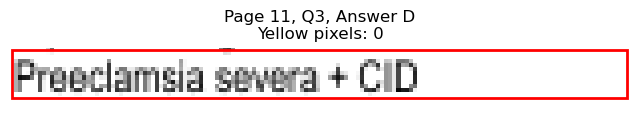

Page 11, Q3 - E: Detected box: x0=85.0, y0=301.9, x1=255.7, y1=314.0
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 845
Page 11, Q3, E: Yellow percentage: 0.0%


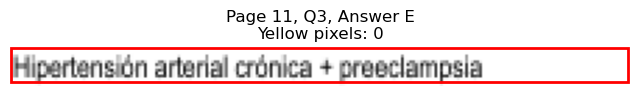


Page 11, Q3 - Selected Answer: A (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=85.0, y0=350.2, x1=94.6, y1=362.3
Page 11, Q4, A: Yellow pixels: 693
Page 11, Q4, A: Total non-white pixels: 793
Page 11, Q4, A: Yellow percentage: 87.4%


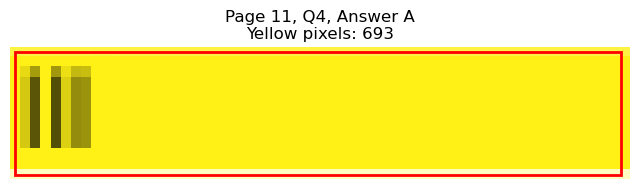

Page 11, Q4 - B: Detected box: x0=70.8, y0=362.2, x1=79.0, y1=374.3
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 114
Page 11, Q4, B: Yellow percentage: 0.0%


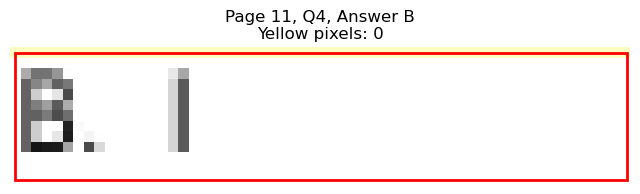

Page 11, Q4 - C: Detected box: x0=70.8, y0=374.2, x1=79.5, y1=386.3
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 67
Page 11, Q4, C: Yellow percentage: 0.0%


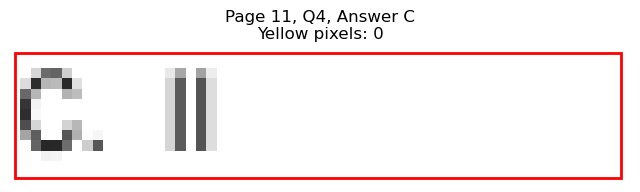

Page 11, Q4 - D: Detected box: x0=322.5, y0=350.2, x1=331.2, y1=362.3
Page 11, Q4, D: Yellow pixels: 0
Page 11, Q4, D: Total non-white pixels: 61
Page 11, Q4, D: Yellow percentage: 0.0%


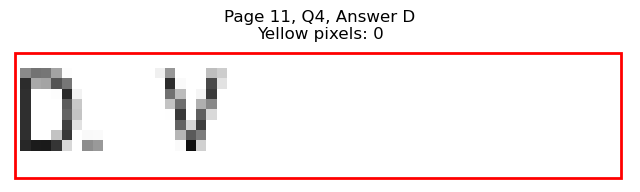

Page 11, Q4 - E: Detected box: x0=336.7, y0=362.2, x1=347.2, y1=374.3
Page 11, Q4, E: Yellow pixels: 0
Page 11, Q4, E: Total non-white pixels: 44
Page 11, Q4, E: Yellow percentage: 0.0%


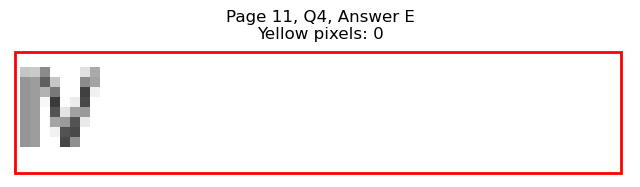


Page 11, Q4 - Selected Answer: A (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=85.0, y0=422.4, x1=182.7, y1=434.5
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 517
Page 11, Q5, A: Yellow percentage: 0.0%


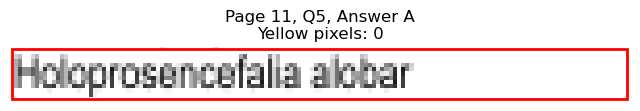

Page 11, Q5 - B: Detected box: x0=85.0, y0=434.4, x1=177.9, y1=446.5
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 491
Page 11, Q5, B: Yellow percentage: 0.0%


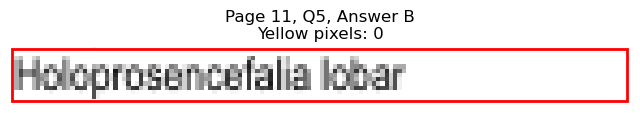

Page 11, Q5 - C: Detected box: x0=85.0, y0=446.6, x1=195.2, y1=458.7
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 568
Page 11, Q5, C: Yellow percentage: 0.0%


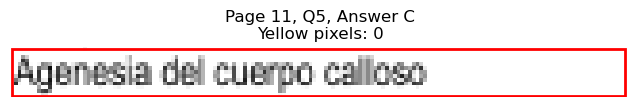

Page 11, Q5 - D: Detected box: x0=336.7, y0=422.4, x1=444.8, y1=434.5
Page 11, Q5, D: Yellow pixels: 1639
Page 11, Q5, D: Total non-white pixels: 2067
Page 11, Q5, D: Yellow percentage: 79.3%


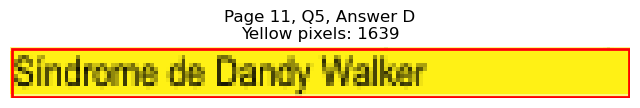

Page 11, Q5 - E: Detected box: x0=336.7, y0=434.4, x1=408.4, y1=446.5
Page 11, Q5, E: Yellow pixels: 123
Page 11, Q5, E: Total non-white pixels: 500
Page 11, Q5, E: Yellow percentage: 24.6%


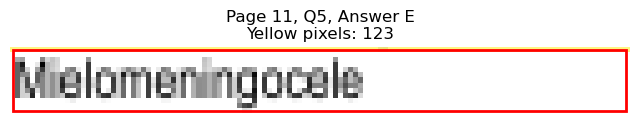


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=85.0, y0=253.7, x1=139.7, y1=265.8
Page 11, Q6, A: Yellow pixels: 839
Page 11, Q6, A: Total non-white pixels: 1378
Page 11, Q6, A: Yellow percentage: 60.9%


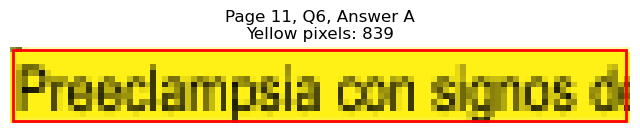

Page 11, Q6 - B: Detected box: x0=85.0, y0=494.7, x1=108.4, y1=506.8
Page 11, Q6, B: Yellow pixels: 74
Page 11, Q6, B: Total non-white pixels: 196
Page 11, Q6, B: Yellow percentage: 37.8%


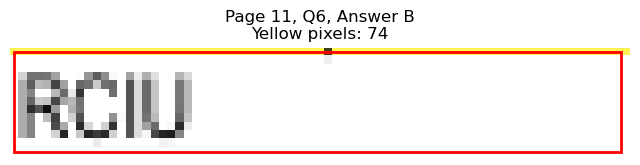

Page 11, Q6 - C: Detected box: x0=85.0, y0=506.8, x1=172.1, y1=518.9
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 431
Page 11, Q6, C: Yellow percentage: 0.0%


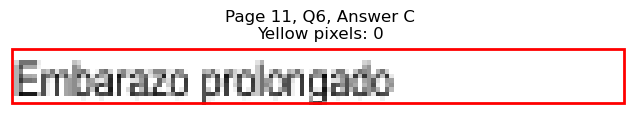

Page 11, Q6 - D: Detected box: x0=336.7, y0=482.7, x1=398.5, y1=494.8
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 309
Page 11, Q6, D: Yellow percentage: 0.0%


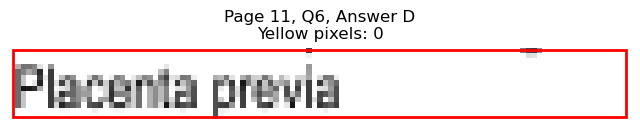

Page 11, Q6 - E: Detected box: x0=336.7, y0=494.7, x1=429.6, y1=506.8
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 469
Page 11, Q6, E: Yellow percentage: 0.0%


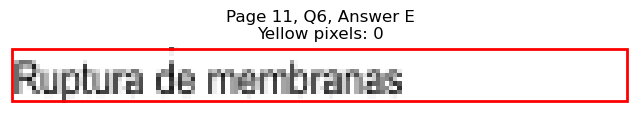


Page 11, Q6 - Selected Answer: A (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,En mujeres gestantes. ¿Cuál es el fármaco asoc...
1,Mujer de 38 años con dolor intenso en fosa ili...
2,¿Cuál es una contraindicación relativa para el...
3,En relación a los miomas uterinos ¿Cuál de las...
4,El Síndrome de Kallmann se clasifica como amen...
...,...
95,¿Qué tipo de fármacos administrados en el segu...
96,"Multigesta de 39 semanas, acude por cefalea y ..."
97,Gestante con diagnóstico de linfoma. Según el ...
98,Gestante de 20 semanas. Ecografía morfológica:...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Carbamazepina,Fenobarbital,Lamotrigina,Topiramato,Valproato
1,III,I,IV,II,V
2,Inestabilidad hemodinámica,Abundante líquido libre en cavidad,Embarazo ectópico roto,Saco gestacional mayor a 3.5 cm,Enfermedad pulmonar activa
3,Embarazo,Sobrepeso,Historia familiar,Edad fértil,Tabaquismo
4,Adquirida,Hipogonadismo hipogonadotrópico,Hipogonadismo hipergonadotrópico,Eugonadotrópica,Hereditaria
...,...,...,...,...,...
95,Antagonistas del receptor de angiotensina.,Diuréticos tiazídicos,Bloqueadores de los canales de calcio,Analgésicos opiáceos,Antibióticos de amplio espectro.
96,Preeclampsia con signos de severidad + síndrom...,Hipertensión arterial crónica + síndrome HELLP,Hipertensión gestacional + CID,Preeclamsia severa + CID,Hipertensión arterial crónica + preeclampsia
97,III,I,II,V,IV
98,Holoprosencefalia alobar,Holoprosencefalia lobar,Agenesia del cuerpo calloso,Síndrome de Dandy Walker,Mielomeningocele


In [9]:
correct_answers_df

,correct_answer
0,E
1,C
2,D
3,E
4,B
...,...
95,A
96,A
97,A
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,En mujeres gestantes. ¿Cuál es el fármaco asoc...,Carbamazepina,Fenobarbital,Lamotrigina,Topiramato,Valproato,E
1,Mujer de 38 años con dolor intenso en fosa ili...,III,I,IV,II,V,C
2,¿Cuál es una contraindicación relativa para el...,Inestabilidad hemodinámica,Abundante líquido libre en cavidad,Embarazo ectópico roto,Saco gestacional mayor a 3.5 cm,Enfermedad pulmonar activa,D
3,En relación a los miomas uterinos ¿Cuál de las...,Embarazo,Sobrepeso,Historia familiar,Edad fértil,Tabaquismo,E
4,El Síndrome de Kallmann se clasifica como amen...,Adquirida,Hipogonadismo hipogonadotrópico,Hipogonadismo hipergonadotrópico,Eugonadotrópica,Hereditaria,B
...,...,...,...,...,...,...,...
95,¿Qué tipo de fármacos administrados en el segu...,Antagonistas del receptor de angiotensina.,Diuréticos tiazídicos,Bloqueadores de los canales de calcio,Analgésicos opiáceos,Antibióticos de amplio espectro.,A
96,"Multigesta de 39 semanas, acude por cefalea y ...",Preeclampsia con signos de severidad + síndrom...,Hipertensión arterial crónica + síndrome HELLP,Hipertensión gestacional + CID,Preeclamsia severa + CID,Hipertensión arterial crónica + preeclampsia,A
97,Gestante con diagnóstico de linfoma. Según el ...,III,I,II,V,IV,A
98,Gestante de 20 semanas. Ecografía morfológica:...,Holoprosencefalia alobar,Holoprosencefalia lobar,Agenesia del cuerpo calloso,Síndrome de Dandy Walker,Mielomeningocele,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/GINECOLOGÍA.csv
